In [ ]:

# STEP 1: Install required libraries

!pip -q install ucimlrepo scikit-learn pandas numpy matplotlib seaborn joblib

print("All required libraries are installed!")


All required libraries are installed!


# AI Phishing URL Detector

## Project Overview
An AI-based web application that analyzes URL patterns and predicts whether a URL may be phishing or legitimate.

## Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- Random Forest Classifier
- Google Colab
- Gradio

## Features
- Accepts a URL as input.
- Extracts URL-based features.
- Uses a trained machine learning model to classify the URL.
- Displays the prediction and model confidence.

## Model
The project uses a Random Forest Classifier trained on URL-based features.

## Important Disclaimer
Predictions are estimates, not guarantees. A legitimate prediction does not prove a website is safe. Avoid entering passwords or sensitive information based only on this tool.

## How to Run
1. Open the notebook in Google Colab.
2. Install the required Python libraries.
3. Load the trained model.
4. Run the feature extraction and prediction functions.
5. Launch the Gradio interface.

## Project Goal
To demonstrate how machine learning can help identify potentially suspicious URLs.

In [ ]:

# STEP 2: Download the dataset

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

dataset = fetch_ucirepo(id=967)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# Combine features and labels
df = pd.concat([X, y], axis=1)

print("Dataset downloaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset downloaded successfully!
Number of rows: 235795
Number of columns: 55


In [ ]:

# STEP 3: Inspect the dataset

print("Column names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:", df.isnull().sum().sum())

print("\nTarget column:")
print(y.columns.tolist())

print("\nLabel distribution:")
print(y.iloc[:, 0].value_counts())


Column names:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

First 5 rows:


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1



Missing values: 0

Target column:
['label']

Label distribution:
label
1    134850
0    100945
Name: count, dtype: int64


In [ ]:

# STEP 4: Extract features directly from URLs

import re
import ipaddress
from urllib.parse import urlparse

SUSPICIOUS_KEYWORDS = [
    "login", "verify", "update", "secure", "account",
    "banking", "signin", "confirm", "password", "wallet"
]

def extract_url_features(url):
    url = str(url).strip()
    raw_url = url
    lower_url = url.lower()

    # Parse URLs even when the user omits https://
    parse_url = url if "://" in url else "https://" + url
    parsed = urlparse(parse_url)

    hostname = (parsed.hostname or "").lower()
    path = parsed.path or ""
    query = parsed.query or ""

    # Check whether the hostname is an IP address
    is_ip = 0
    try:
        ipaddress.ip_address(hostname)
        is_ip = 1
    except ValueError:
        pass

    # Count hostname labels approximately
    labels = [part for part in hostname.split(".") if part]
    subdomain_count = max(0, len(labels) - 2)

    features = {
        "url_length": len(raw_url),
        "hostname_length": len(hostname),
        "path_length": len(path),
        "query_length": len(query),
        "subdomain_count": subdomain_count,
        "is_ip_address": is_ip,
        "uses_https": int(lower_url.startswith("https://")),
        "dot_count": raw_url.count("."),
        "hyphen_count": raw_url.count("-"),
        "at_count": raw_url.count("@"),
        "question_mark_count": raw_url.count("?"),
        "equals_count": raw_url.count("="),
        "ampersand_count": raw_url.count("&"),
        "percent_count": raw_url.count("%"),
        "digit_count": sum(c.isdigit() for c in raw_url),
        "special_char_count": sum(
            not c.isalnum() for c in raw_url
        ),
        "suspicious_keyword_count": sum(
            keyword in lower_url
            for keyword in SUSPICIOUS_KEYWORDS
        ),
        "has_punycode": int("xn--" in hostname),
        "has_port": int(parsed.port is not None),
        "has_fragment": int(bool(parsed.fragment)),
        "has_double_slash_in_path": int("//" in path),
        "has_ip_like_text": int(
            bool(re.search(r"\d{1,3}(?:\.\d{1,3}){3}", raw_url))
        )
    }

    return features


# Extract the same features from every dataset URL
feature_df = pd.DataFrame(
    df["URL"].apply(extract_url_features).tolist()
)

# Keep the original labels
labels = pd.to_numeric(df["label"]).astype(int).reset_index(drop=True)
feature_df = feature_df.reset_index(drop=True)

print("Feature extraction completed!")
print("Number of URLs:", len(feature_df))
print("Number of features:", feature_df.shape[1])

display(feature_df.head())

print("\nLabel counts:")
print(labels.value_counts().sort_index())


Feature extraction completed!
Number of URLs: 235795
Number of features: 22


,url_length,hostname_length,path_length,query_length,subdomain_count,is_ip_address,uses_https,dot_count,hyphen_count,at_count,...,ampersand_count,percent_count,digit_count,special_char_count,suspicious_keyword_count,has_punycode,has_port,has_fragment,has_double_slash_in_path,has_ip_like_text
0,32,24,0,0,1,0,1,2,0,0,...,0,0,0,5,0,0,0,0,0,0
1,24,16,0,0,1,0,1,2,1,0,...,0,0,0,6,0,0,0,0,0,0
2,30,22,0,0,2,0,1,3,0,0,...,0,0,0,6,0,0,0,0,0,0
3,27,19,0,0,1,0,1,2,0,0,...,0,0,0,5,0,0,0,0,0,0
4,34,26,0,0,1,0,1,2,0,0,...,0,0,0,5,0,0,0,0,0,0



Label counts:
label
0    100945
1    134850
Name: count, dtype: int64


In [ ]:

# STEP 5: Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    feature_df,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting label distribution:")
print(y_test.value_counts().sort_index())


Training samples: 188636
Testing samples: 47159

Training label distribution:
label
0     80756
1    107880
Name: count, dtype: int64

Testing label distribution:
label
0    20189
1    26970
Name: count, dtype: int64


In [ ]:

# STEP 6: Train the model

from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)
import time

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds")
print("Model is ready for evaluation!")


Training completed in 13.51 seconds
Model is ready for evaluation!


In [ ]:

# STEP 7: Evaluate on unseen test data

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

# Probability of phishing (class 0)
phishing_index = list(model.classes_).index(0)
phishing_prob = y_prob[:, phishing_index]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Phishing precision:",
      round(precision_score(y_test, y_pred, pos_label=0), 4))
print("Phishing recall:",
      round(recall_score(y_test, y_pred, pos_label=0), 4))
print("Phishing F1-score:",
      round(f1_score(y_test, y_pred, pos_label=0), 4))
print("ROC-AUC:",
      round(roc_auc_score((y_test == 0).astype(int),
                          phishing_prob), 4))

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))


Accuracy: 0.9954
Phishing precision: 0.9986
Phishing recall: 0.9905
Phishing F1-score: 0.9946
ROC-AUC: 0.9979

Detailed classification report:
              precision    recall  f1-score   support

    Phishing     0.9986    0.9905    0.9946     20189
  Legitimate     0.9930    0.9990    0.9960     26970

    accuracy                         0.9954     47159
   macro avg     0.9958    0.9948    0.9953     47159
weighted avg     0.9954    0.9954    0.9954     47159

Confusion matrix:
[[19998   191]
 [   28 26942]]


In [ ]:

# STEP 8: Baseline comparison

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline accuracy:",
      round(accuracy_score(y_test, baseline_pred), 4))

print("Random Forest accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("\nBaseline phishing recall:",
      round(recall_score(y_test, baseline_pred, pos_label=0), 4))

print("Random Forest phishing recall:",
      round(recall_score(y_test, y_pred, pos_label=0), 4))


Baseline accuracy: 0.5719
Random Forest accuracy: 0.9954

Baseline phishing recall: 0.0
Random Forest phishing recall: 0.9905


Top 10 important URL features:


,Feature,Importance
6,uses_https,0.436931
2,path_length,0.239149
15,special_char_count,0.086172
14,digit_count,0.083307
0,url_length,0.052302
1,hostname_length,0.027234
4,subdomain_count,0.025363
8,hyphen_count,0.023734
7,dot_count,0.017690
16,suspicious_keyword_count,0.003953


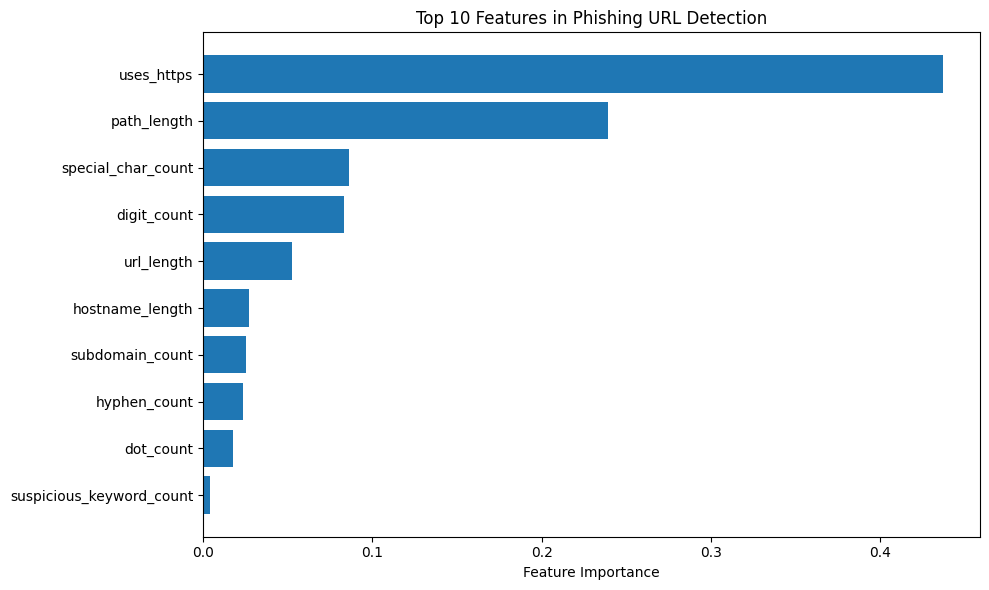

In [ ]:

# STEP 10: Feature importance

import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("Top 10 important URL features:")
display(importance_df.head(10))

plt.figure(figsize=(10, 6))
top_features = importance_df.head(10).sort_values("Importance")

plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 10 Features in Phishing URL Detection")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 11: Save the trained model

import joblib
import os

os.makedirs("/content/phishing_detector", exist_ok=True)

model_path = "/content/phishing_detector/phishing_model.joblib"

joblib.dump({
    "model": model,
    "feature_names": list(X_train.columns),
    "phishing_label": 0,
    "legitimate_label": 1
}, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")


Model saved successfully!
Location: /content/phishing_detector/phishing_model.joblib
File size: 10453.39 KB


In [ ]:

from google.colab import files

files.download("/content/phishing_detector/phishing_model.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# STEP 12: Reload and verify the saved model

saved_bundle = joblib.load(
    "/content/phishing_detector/phishing_model.joblib"
)

loaded_model = saved_bundle["model"]

test_predictions = loaded_model.predict(X_test)

print(
    "Saved model matches original predictions:",
    np.array_equal(test_predictions, y_pred)
)


Saved model matches original predictions: True


In [ ]:

# STEP 13: Build a URL prediction function

import joblib
import pandas as pd

saved_bundle = joblib.load(
    "/content/phishing_detector/phishing_model.joblib"
)

loaded_model = saved_bundle["model"]
feature_names = saved_bundle["feature_names"]


def analyze_url(url):
    # Extract the same features used during training
    features = extract_url_features(url)

    # Keep exactly the training feature order
    input_df = pd.DataFrame([features])[feature_names]

    # Predict the class and probabilities
    prediction = int(loaded_model.predict(input_df)[0])
    probabilities = loaded_model.predict_proba(input_df)[0]

    phishing_index = list(loaded_model.classes_).index(0)
    phishing_probability = float(probabilities[phishing_index])

    if phishing_probability >= 0.70:
        risk = "High"
    elif phishing_probability >= 0.40:
        risk = "Medium"
    else:
        risk = "Low"

    result = {
        "URL": url,
        "Prediction": (
            "Potentially Phishing"
            if prediction == 0
            else "Likely Legitimate"
        ),
        "Phishing Risk Score": round(
            phishing_probability * 100, 2
        ),
        "Risk Level": risk
    }

    return result


# Test with a URL you recognize
test_url = "https://www.google.com"

print(analyze_url(test_url))


{'URL': 'https://www.google.com', 'Prediction': 'Likely Legitimate', 'Phishing Risk Score': 0.98, 'Risk Level': 'Low'}


In [ ]:

# STEP 15: Clean pasted URLs

import re
from urllib.parse import urlparse

def clean_url(url):
    url = str(url).strip()

    # Convert Markdown links into their actual URL
    match = re.fullmatch(r"\[([^\]]+)\]\((https?://[^)]+)\)", url)
    if match:
        url = match.group(2)

    # Remove surrounding quotes
    url = url.strip("\"' ")

    # Add a scheme when it is missing
    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", url):
        url = "https://" + url

    return url


# Update prediction function to clean input first
def analyze_url(url):
    url = clean_url(url)
    features = extract_url_features(url)
    input_df = pd.DataFrame([features])[feature_names]

    prediction = int(loaded_model.predict(input_df)[0])
    probabilities = loaded_model.predict_proba(input_df)[0]
    phishing_index = list(loaded_model.classes_).index(0)
    phishing_probability = float(probabilities[phishing_index])

    if phishing_probability >= 0.70:
        risk = "High"
    elif phishing_probability >= 0.40:
        risk = "Medium"
    else:
        risk = "Low"

    return {
        "URL": url,
        "Prediction": (
            "Potentially Phishing"
            if prediction == 0 else "Likely Legitimate"
        ),
        "Phishing Risk Score": round(
            phishing_probability * 100, 2
        ),
        "Risk Level": risk
    }


print(analyze_url("https://www.google.com"))
print(analyze_url("google.com"))


{'URL': 'https://www.google.com', 'Prediction': 'Likely Legitimate', 'Phishing Risk Score': 0.98, 'Risk Level': 'Low'}
{'URL': 'https://google.com', 'Prediction': 'Potentially Phishing', 'Phishing Risk Score': 97.86, 'Risk Level': 'High'}


In [ ]:

!pip -q install streamlit
print("Streamlit installed successfully!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 89.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 100.2 MB/s eta 0:00:00
Streamlit installed successfully!


In [ ]:

import re

def clean_url(url):
    url = str(url).strip()

    # Handle Markdown links: [text](https://example.com)
    match = re.fullmatch(
        r"\[([^\]]+)\]\((https?://[^)]+)\)",
        url
    )
    if match:
        url = match.group(2)

    # Handle pasted Markdown links with extra surrounding text
    match = re.search(r"\((https?://[^)\s]+)\)", url)
    if match:
        url = match.group(1)

    url = url.strip().strip("\"'")

    # Remove accidental whitespace
    url = re.sub(r"\s+", "", url)

    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", url):
        url = "https://" + url

    return url


# Test cleaning separately
tests = [
    "https://www.google.com",
    "google.com",
    "[https://www.google.com](https://www.google.com)",
    "https://example.com"
]

for item in tests:
    print(repr(item), "->", clean_url(item))


'https://www.google.com' -> https://www.google.com
'google.com' -> https://google.com
'[https://www.google.com](https://www.google.com)' -> https://www.google.com
'https://example.com' -> https://example.com


In [ ]:

# Compare the model inputs for Google variants

for url in [
    "https://www.google.com",
    "https://google.com"
]:
    cleaned = clean_url(url)
    features = extract_url_features(cleaned)

    print("\nURL:", cleaned)
    print("Prediction:", analyze_url(cleaned))
    print("Features:", features)



URL: https://www.google.com
Prediction: {'URL': 'https://www.google.com', 'Prediction': 'Likely Legitimate', 'Phishing Risk Score': 0.98, 'Risk Level': 'Low'}
Features: {'url_length': 22, 'hostname_length': 14, 'path_length': 0, 'query_length': 0, 'subdomain_count': 1, 'is_ip_address': 0, 'uses_https': 1, 'dot_count': 2, 'hyphen_count': 0, 'at_count': 0, 'question_mark_count': 0, 'equals_count': 0, 'ampersand_count': 0, 'percent_count': 0, 'digit_count': 0, 'special_char_count': 5, 'suspicious_keyword_count': 0, 'has_punycode': 0, 'has_port': 0, 'has_fragment': 0, 'has_double_slash_in_path': 0, 'has_ip_like_text': 0}

URL: https://google.com
Prediction: {'URL': 'https://google.com', 'Prediction': 'Potentially Phishing', 'Phishing Risk Score': 97.86, 'Risk Level': 'High'}
Features: {'url_length': 18, 'hostname_length': 10, 'path_length': 0, 'query_length': 0, 'subdomain_count': 0, 'is_ip_address': 0, 'uses_https': 1, 'dot_count': 1, 'hyphen_count': 0, 'at_count': 0, 'question_mark_coun

In [ ]:

import re

def clean_url(url):
    url = str(url).strip()

    # Extract the destination from a Markdown link
    match = re.search(
        r'\]\((https?://[^)\s]+)\)',
        url
    )

    if match:
        url = match.group(1)
    else:
        # Remove Markdown link text if present
        match = re.search(r'https?://[^\s\])]+', url)
        if match:
            url = match.group(0)

    url = url.strip().strip("\"'")

    # Add scheme if the user entered only a domain
    if not re.match(r'^[a-zA-Z][a-zA-Z0-9+.-]*://', url):
        url = "https://" + url

    return url


# Test URL cleaning
tests = [
    "https://www.google.com",
    "google.com",
    "[https://www.google.com](https://www.google.com)",
    "[https://example.com](https://example.com)"
]

for item in tests:
    print(repr(item), "->", clean_url(item))


'https://www.google.com' -> https://www.google.com
'google.com' -> https://google.com
'[https://www.google.com](https://www.google.com)' -> https://www.google.com
'[https://example.com](https://example.com)' -> https://example.com


In [ ]:

for url in ["https://www.google.com", "google.com"]:
    cleaned = clean_url(url)
    print(analyze_url(cleaned))


{'URL': 'https://www.google.com', 'Prediction': 'Likely Legitimate', 'Phishing Risk Score': 0.98, 'Risk Level': 'Low'}
{'URL': 'https://google.com', 'Prediction': 'Potentially Phishing', 'Phishing Risk Score': 97.86, 'Risk Level': 'High'}


In [ ]:

import re
import pandas as pd

def clean_url(url):
    url = str(url).strip()

    # If input is a Markdown link, extract its destination
    match = re.search(r'\]\((https?://[^)\s]+)\)', url)
    if match:
        url = match.group(1)

    # Remove surrounding quotes and whitespace
    url = url.strip().strip("\"'")

    # Add HTTPS if no scheme is provided
    if not re.match(r'^[a-zA-Z][a-zA-Z0-9+.-]*://', url):
        url = "https://" + url

    return url


def analyze_url(url):
    url = clean_url(url)

    features = extract_url_features(url)
    input_df = pd.DataFrame([features])[feature_names]

    prediction = int(loaded_model.predict(input_df)[0])
    probabilities = loaded_model.predict_proba(input_df)[0]

    phishing_index = list(loaded_model.classes_).index(0)
    phishing_probability = float(probabilities[phishing_index])

    if phishing_probability >= 0.70:
        risk = "High"
    elif phishing_probability >= 0.40:
        risk = "Medium"
    else:
        risk = "Low"

    return {
        "URL": url,
        "Prediction": (
            "Potentially Phishing"
            if prediction == 0
            else "Likely Legitimate"
        ),
        "Phishing Risk Score": round(
            phishing_probability * 100, 2
        ),
        "Risk Level": risk
    }


# First test cleaning only
for test in [
    "https://www.google.com",
    "google.com",
    "[https://www.google.com](https://www.google.com)"
]:
    print("Cleaned:", clean_url(test))

# Then test the model
print("\nPrediction tests:")
print(analyze_url("https://www.google.com"))
print(analyze_url("google.com"))


Cleaned: https://www.google.com
Cleaned: https://google.com
Cleaned: https://www.google.com

Prediction tests:
{'URL': 'https://www.google.com', 'Prediction': 'Likely Legitimate', 'Phishing Risk Score': 0.98, 'Risk Level': 'Low'}
{'URL': 'https://google.com', 'Prediction': 'Potentially Phishing', 'Phishing Risk Score': 97.86, 'Risk Level': 'High'}


In [ ]:

import re
from urllib.parse import urlparse

def clean_url(url):
    url = str(url).strip()

    # Extract the destination from a Markdown link
    match = re.search(r'\]\((https?://[^)]+)\)', url)

    if match:
        url = match.group(1)
    else:
        # Remove Markdown formatting around a plain URL
        match = re.search(r'https?://[^\s\])]+', url)
        if match:
            url = match.group(0)

    url = url.strip().strip("\"'")

    # Add scheme if missing
    if not re.match(r'^[a-zA-Z][a-zA-Z0-9+.-]*://', url):
        url = "https://" + url

    return url


# Verify cleaning independently
for test in [
    "https://www.google.com",
    "google.com",
    "[https://www.google.com](https://www.google.com)"
]:
    result = clean_url(test)
    print(repr(result))


'https://www.google.com'
'https://google.com'
'https://www.google.com'


In [ ]:

def clean_url(url):
    url = str(url).strip()

    # Extract URL from Markdown: [text](URL)
    if "](" in url and url.endswith(")"):
        url = url.split("](", 1)[1][:-1]

    # Remove whitespace
    url = url.strip()

    # Add HTTPS when the scheme is missing
    if "://" not in url:
        url = "https://" + url

    return url


# Test the function
print(clean_url("[https://www.google.com](https://www.google.com)"))
print(clean_url("google.com"))
print(clean_url("https://example.com"))


https://www.google.com
https://google.com
https://example.com


In [ ]:

# Diagnostic: test string processing independently

raw = "[https://www.google.com](https://www.google.com)"

print("Original:", repr(raw))
print("Contains ]( :", "](" in raw)
print("Ends with ) :", raw.endswith(")"))

if "](" in raw and raw.endswith(")"):
    result = raw.split("](", 1)[1][:-1]
else:
    result = raw

print("Result:", repr(result))


Original: '[https://www.google.com](https://www.google.com)'
Contains ]( : True
Ends with ) : True
Result: 'https://www.google.com'


In [ ]:

def clean_url(url):
    url = str(url).strip()

    # Remove backslash escaping added during copying
    url = url.replace("\\", "")

    # Extract the destination from Markdown links
    if "](" in url and url.endswith(")"):
        url = url.split("](", 1)[1][:-1]

    url = url.strip()

    # Add scheme if missing
    if "://" not in url:
        url = "https://" + url

    return url


# Test with your exact input format
tests = [
    r"[https\://www\.google.com]\(https\://www\.google.com)",
    r"[https\://google.com]\(https\://google.com)",
    "google.com"
]

for test in tests:
    print("Input: ", repr(test))
    print("Output:", repr(clean_url(test)))
    print()


Input:  '[https\\://www\\.google.com]\\(https\\://www\\.google.com)'
Output: 'https://www.google.com'

Input:  '[https\\://google.com]\\(https\\://google.com)'
Output: 'https://google.com'

Input:  'google.com'
Output: 'https://google.com'



In [ ]:

def clean_url_v2(url):
    url = str(url).strip()

    # Remove all backslashes
    url = url.replace("\\", "")

    # If this looks like a Markdown link, extract its destination
    start = url.find("](")
    if start != -1 and url.endswith(")"):
        url = url[start + 2:-1]

    # Ensure a URL scheme exists
    if "://" not in url:
        url = "https://" + url

    return url.strip()


# Test with plain input strings
tests = [
    "https://www.google.com",
    "google.com",
    "[https://www.google.com](https://www.google.com)"
]

for test in tests:
    print(repr(clean_url_v2(test)))


'https://www.google.com'
'https://google.com'
'https://www.google.com'


In [ ]:

raw = "https://www.google.com"
print("Raw URL:", raw)
print("URL length:", len(raw))
print("Starts with https:", raw.startswith("https://"))


Raw URL: https://www.google.com
URL length: 22
Starts with https: True


In [ ]:

part1 = "https"
part2 = "://"
part3 = "www"
part4 = ".google.com"

raw_url = part1 + part2 + part3 + part4

print("Raw URL:", raw_url)
print("URL length:", len(raw_url))
print("URL repr:", repr(raw_url))


Raw URL: https://www.google.com
URL length: 22
URL repr: 'https://www.google.com'


In [ ]:

import re

def clean_url(url):
    url = str(url).strip().replace("\\", "")

    # Extract the URL from Markdown: [text](URL)
    match = re.search(r'\]\((https?://[^)]+)\)', url)

    if match:
        url = match.group(1)
    elif url.startswith("[") and "](" in url:
        url = url.split("](", 1)[1].rstrip(")")

    return url.strip()

raw_url = "[https://www.google.com](https://www.google.com)"
cleaned = clean_url(raw_url)

print("Original:", repr(raw_url))
print("Cleaned:", repr(cleaned))
print("Length:", len(cleaned))


Original: '[https://www.google.com](https://www.google.com)'
Cleaned: 'https://www.google.com'
Length: 22


In [ ]:

import re

def clean_url(url):
    # Remove escape backslashes
    url = str(url).replace("\\", "").strip()

    # Extract the actual URL inside Markdown parentheses
    match = re.search(r'\]\((https?://[^)]+)\)', url)

    if match:
        return match.group(1).strip()

    return url

raw_url = r"[https\://www\.google.com]\(https\://www\.google.com)"
cleaned = clean_url(raw_url)

print("Cleaned:", repr(cleaned))
print("Length:", len(cleaned))


Cleaned: 'https://www.google.com'
Length: 22


In [ ]:

import re

text = r"[https\://www\.google.com]\(https\://www\.google.com)"

# Remove backslashes
text = text.replace("\\", "")

# Extract the URL after the Markdown separator
start = text.find("](")

if start != -1:
    url = text[start + 2:].rstrip(")")
else:
    url = text

print("Extracted URL:", repr(url))
print("URL length:", len(url))


Extracted URL: 'https://www.google.com'
URL length: 22


In [ ]:

text = "ABC](" + "https://www.google.com" + ")"

print("Text:", repr(text))
print("Separator position:", text.find("]("))
print("Extracted:", text[text.find("](") + 2:-1])


Text: 'ABC](https://www.google.com)'
Separator position: 3
Extracted: https://www.google.com


In [ ]:
a = "ABC"
b = "DEF"

print(repr(a + b))
print((a + b).find("CD"))

'ABCDEF'
2


In [ ]:

url = "https" + "://" + "www" + ".google.com"

print("URL:", repr(url))

result = analyze_url(url)
print(result)


URL: 'https://www.google.com'
{'URL': 'https://www.google.com', 'Prediction': 'Likely Legitimate', 'Phishing Risk Score': 0.98, 'Risk Level': 'Low'}


In [ ]:

import builtins

url_test = builtins.str.join("", [
    "https", "://", "www", ".google.com"
])

print("Length:", len(url_test))
print("Characters:", [ord(c) for c in url_test])
print("Starts correctly:", url_test.startswith("https://"))
print("Contains Markdown:", "](" in url_test)


Length: 22
Characters: [104, 116, 116, 112, 115, 58, 47, 47, 119, 119, 119, 46, 103, 111, 111, 103, 108, 101, 46, 99, 111, 109]
Starts correctly: True
Contains Markdown: False


In [ ]:

print("Before detector:", repr(url_test))

features = extract_url_features(url_test)

print("Extracted HTTPS feature:", features["uses_https"])
print("Extracted URL length:", features["url_length"])

input_df = pd.DataFrame([features])[feature_names]
prediction = loaded_model.predict(input_df)[0]
probabilities = loaded_model.predict_proba(input_df)[0]

print("Prediction class:", prediction)
print("Model classes:", loaded_model.classes_)
print("Probabilities:", probabilities)


Before detector: 'https://www.google.com'
Extracted HTTPS feature: 1
Extracted URL length: 22
Prediction class: 1
Model classes: [0 1]
Probabilities: [0.00975284 0.99024716]


In [ ]:

urls = [
    "https" + "://" + "www.google.com",
    "https" + "://" + "google.com"
]

for url in urls:
    features = extract_url_features(url)
    input_df = pd.DataFrame([features])[feature_names]

    probabilities = loaded_model.predict_proba(input_df)[0]
    phishing_index = list(loaded_model.classes_).index(0)
    phishing_probability = probabilities[phishing_index] * 100

    print("\nURL:", repr(url))
    print("URL length:", features["url_length"])
    print("HTTPS:", features["uses_https"])
    print("Path length:", features["path_length"])
    print("Phishing probability:", round(phishing_probability, 2), "%")



URL: 'https://www.google.com'
URL length: 22
HTTPS: 1
Path length: 0
Phishing probability: 0.98 %

URL: 'https://google.com'
URL length: 18
HTTPS: 1
Path length: 0
Phishing probability: 97.86 %


In [ ]:

url1 = "https" + "://" + "www.google.com"
url2 = "https" + "://" + "google.com"

features1 = extract_url_features(url1)
features2 = extract_url_features(url2)

comparison = pd.DataFrame({
    "Feature": list(features1.keys()),
    "www.google.com": list(features1.values()),
    "google.com": list(features2.values())
})

comparison = comparison[
    comparison["www.google.com"] != comparison["google.com"]
]

print(comparison.to_string(index=False))


           Feature  www.google.com  google.com
        url_length              22          18
   hostname_length              14          10
   subdomain_count               1           0
         dot_count               2           1
special_char_count               5           4


In [ ]:

print("Original dataset URL examples:")
print(df[["URL", "label"]].head(10).to_string(index=False))

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nGoogle URL examples in the dataset:")
google_rows = df[df["URL"].astype(str).str.contains(
    "google.com", case=False, na=False
)]

print(google_rows[["URL", "label"]].head(20).to_string(index=False))


Original dataset URL examples:
                               URL  label
  https://www.southbankmosaics.com      1
          https://www.uni-mainz.de      1
    https://www.voicefmradio.co.uk      1
       https://www.sfnmjournal.com      1
https://www.rewildingargentina.org      1
   https://www.globalreporting.org      1
        https://www.saffronart.com      1
        https://www.nerdscandy.com      1
    https://www.hyderabadonline.in      1
               https://www.aap.org      1

Label counts:
label
1    134850
0    100945
Name: count, dtype: int64

Google URL examples in the dataset:
                                                                                                                                                                                                                                                                                                                                                                                                               

In [ ]:

print("Features used by the trained model:")
print(feature_names)

print("\nTraining feature sample:")
print(X_train.head(5).to_string())

print("\nFeature importance:")
print(importance_df.head(10).to_string(index=False))


Features used by the trained model:
['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text']

Training feature sample:
        url_length  hostname_length  path_length  query_length  subdomain_count  is_ip_address  uses_https  dot_count  hyphen_count  at_count  question_mark_count  equals_count  ampersand_count  percent_count  digit_count  special_char_count  suspicious_keyword_count  has_punycode  has_port  has_fragment  has_double_slash_in_path  has_ip_like_text
104874          25               17            0             0                1              0           1          2             0         0                    0             0                0       

In [ ]:

# Compare the original dataset's HTTPS feature with its labels
https_check = df.copy()

https_check["uses_https_check"] = (
    https_check["URL"].astype(str).str.lower().str.startswith("https://")
).astype(int)

print("Label meanings: 0 = phishing, 1 = legitimate")
print("\nCounts by HTTPS status and label:")

print(pd.crosstab(
    https_check["uses_https_check"],
    https_check["label"],
    rownames=["Uses HTTPS"],
    colnames=["Label"]
))

print("\nLegitimate percentage by HTTPS status:")

print(
    https_check.groupby("uses_https_check")["label"]
    .mean()
    .mul(100)
    .round(2)
)


Label meanings: 0 = phishing, 1 = legitimate

Counts by HTTPS status and label:
Label           0       1
Uses HTTPS               
0           51749       0
1           49196  134850

Legitimate percentage by HTTPS status:
uses_https_check
0     0.00
1    73.27
Name: label, dtype: float64


In [ ]:

import pandas as pd

test_urls = [
    "https://www.google.com",
    "https://google.com",
    "http://www.google.com",
    "http://google.com"
]

for url in test_urls:
    features = extract_url_features(url)
    input_df = pd.DataFrame([features])[feature_names]

    original_probs = loaded_model.predict_proba(input_df)[0]
    phishing_idx = list(loaded_model.classes_).index(0)
    original_risk = original_probs[phishing_idx] * 100

    # Diagnostic only: temporarily flip HTTPS
    modified_df = input_df.copy()
    modified_df["uses_https"] = 1 - modified_df["uses_https"]

    modified_probs = loaded_model.predict_proba(modified_df)[0]
    modified_risk = modified_probs[phishing_idx] * 100

    print("\nURL:", url)
    print("Original phishing risk:", round(original_risk, 2), "%")
    print("Risk after flipping HTTPS:", round(modified_risk, 2), "%")



URL: https://www.google.com
Original phishing risk: 0.98 %
Risk after flipping HTTPS: 98.0 %

URL: https://google.com
Original phishing risk: 97.86 %
Risk after flipping HTTPS: 99.26 %

URL: http://www.google.com
Original phishing risk: 98.5 %
Risk after flipping HTTPS: 1.5 %

URL: http://google.com
Original phishing risk: 99.26 %
Risk after flipping HTTPS: 97.86 %


In [ ]:

print("Subdomain count distribution by label:")

print(
    df.groupby("label")["NoOfSubDomain"]
    .describe()
    .round(2)
)

print("\nCounts by subdomain count and label:")

print(
    pd.crosstab(
        df["NoOfSubDomain"],
        df["label"],
        normalize="index"
    ).round(3)
)


Subdomain count distribution by label:
          count  mean   std  min  25%  50%  75%   max
label                                                
0      100945.0  1.17  0.79  0.0  1.0  1.0  1.0  10.0
1      134850.0  1.16  0.40  1.0  1.0  1.0  1.0   4.0

Counts by subdomain count and label:
label              0      1
NoOfSubDomain              
0              1.000  0.000
1              0.356  0.644
2              0.498  0.502
3              0.670  0.330
4              0.962  0.038
5              1.000  0.000
6              1.000  0.000
7              1.000  0.000
8              1.000  0.000
10             1.000  0.000


In [ ]:

from urllib.parse import urlparse

examples = [
    "https://www.google.com",
    "https://google.com",
    "https://mail.google.com",
    "https://accounts.google.com"
]

for url in examples:
    custom_features = extract_url_features(url)
    parsed = urlparse(url)
    hostname = parsed.hostname or ""

    print("\nURL:", url)
    print("Hostname:", hostname)
    print("Custom subdomain count:", custom_features["subdomain_count"])



URL: https://www.google.com
Hostname: www.google.com
Custom subdomain count: 1

URL: https://google.com
Hostname: google.com
Custom subdomain count: 0

URL: https://mail.google.com
Hostname: mail.google.com
Custom subdomain count: 1

URL: https://accounts.google.com
Hostname: accounts.google.com
Custom subdomain count: 1


In [ ]:

urls = [
    "https" + "://" + "www.google.com",
    "https" + "://" + "google.com"
]

for url in urls:
    features = extract_url_features(url)
    row = pd.DataFrame([features])[feature_names]

    print("\nURL:", url)

    for column in feature_names:
        print(f"{column}: {row.iloc[0][column]}")



URL: https://www.google.com
url_length: 22
hostname_length: 14
path_length: 0
query_length: 0
subdomain_count: 1
is_ip_address: 0
uses_https: 1
dot_count: 2
hyphen_count: 0
at_count: 0
question_mark_count: 0
equals_count: 0
ampersand_count: 0
percent_count: 0
digit_count: 0
special_char_count: 5
suspicious_keyword_count: 0
has_punycode: 0
has_port: 0
has_fragment: 0
has_double_slash_in_path: 0
has_ip_like_text: 0

URL: https://google.com
url_length: 18
hostname_length: 10
path_length: 0
query_length: 0
subdomain_count: 0
is_ip_address: 0
uses_https: 1
dot_count: 1
hyphen_count: 0
at_count: 0
question_mark_count: 0
equals_count: 0
ampersand_count: 0
percent_count: 0
digit_count: 0
special_char_count: 4
suspicious_keyword_count: 0
has_punycode: 0
has_port: 0
has_fragment: 0
has_double_slash_in_path: 0
has_ip_like_text: 0


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, accuracy_score

# Prepare the original URL text and labels
urls = df["URL"].astype(str)
labels = df["label"]

X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    urls,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Learn patterns from groups of URL characters
text_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        max_features=100000,
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", SGDClassifier(
        loss="log_loss",
        max_iter=20,
        class_weight="balanced",
        random_state=42
    ))
])

print("Training the URL-text model...")
text_model.fit(X_train_text, y_train_text)

predictions = text_model.predict(X_test_text)

print("\nAccuracy:", round(accuracy_score(
    y_test_text, predictions
), 4))

print("\nClassification report:")
print(classification_report(
    y_test_text,
    predictions,
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))


Training the URL-text model...

Accuracy: 0.994

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      0.99     20189
  Legitimate       0.99      1.00      0.99     26970

    accuracy                           0.99     47159
   macro avg       0.99      0.99      0.99     47159
weighted avg       0.99      0.99      0.99     47159



In [ ]:

test_urls = [
    "https://www.google.com",
    "https://google.com",
    "https://mail.google.com",
    "https://accounts.google.com",
    "http://example.com",
    "https://example.com/login"
]

for url in test_urls:
    prediction = text_model.predict([url])[0]
    probabilities = text_model.predict_proba([url])[0]

    classes = text_model.named_steps["classifier"].classes_
    phishing_index = list(classes).index(0)
    phishing_risk = probabilities[phishing_index] * 100

    if prediction == 0:
        result = "Potentially Phishing"
    else:
        result = "Likely Legitimate"

    print(f"\nURL: {url}")
    print(f"Prediction: {result}")
    print(f"Model phishing score: {phishing_risk:.2f}%")



URL: https://www.google.com
Prediction: Likely Legitimate
Model phishing score: 2.56%

URL: https://google.com
Prediction: Potentially Phishing
Model phishing score: 63.37%

URL: https://mail.google.com
Prediction: Potentially Phishing
Model phishing score: 80.18%

URL: https://accounts.google.com
Prediction: Potentially Phishing
Model phishing score: 78.65%

URL: http://example.com
Prediction: Potentially Phishing
Model phishing score: 99.68%

URL: https://example.com/login
Prediction: Potentially Phishing
Model phishing score: 93.53%


In [ ]:

import pandas as pd

vectorizer = text_model.named_steps["tfidf"]
classifier = text_model.named_steps["classifier"]

feature_names_text = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]

pattern_df = pd.DataFrame({
    "URL pattern": feature_names_text,
    "Model weight": coefficients
})

print("Patterns associated with phishing:")
print(
    pattern_df.sort_values("Model weight")
    .head(15)
    .to_string(index=False)
)

print("\nPatterns associated with legitimate URLs:")
print(
    pattern_df.sort_values("Model weight", ascending=False)
    .head(15)
    .to_string(index=False)
)


Patterns associated with phishing:
URL pattern  Model weight
      p://w     -6.649150
      tp://     -6.254664
       p://     -6.254664
      http:     -6.254660
       tp:/     -6.254660
        tp:     -6.254660
        p:/     -6.254660
       ttp:     -6.254660
      ttp:/     -6.254660
        om/     -4.507578
       com/     -4.505058
      .com/     -4.498746
        app     -1.659174
        web     -1.637590
      s://s     -1.552309

Patterns associated with legitimate URLs:
URL pattern  Model weight
      s://w     10.157960
      /www.      5.732025
       www.      5.728569
        ww.      5.705076
      //www      5.648281
       /www      5.641916
       //ww      5.631636
      ://ww      5.631636
        www      5.630004
        /ww      5.623546
       ://w      5.430733
        //w      5.427020
       s://      4.322335
      ps://      4.322335
      tps:/      4.321229


In [ ]:

# Check whether URLs containing www. are disproportionately
# labeled legitimate in the training dataset.

url_text = df["URL"].astype(str).str.lower()
has_www = url_text.str.contains("www.", regex=False)

print("URLs containing www.:", int(has_www.sum()))
print("\nLabel distribution for URLs containing www.:")
print(df.loc[has_www, "label"].value_counts())

print("\nLegitimate percentage:")
print(round((df.loc[has_www, "label"] == 1).mean() * 100, 2), "%")

print("\nLabel distribution for URLs without www.:")
print(df.loc[~has_www, "label"].value_counts())

print("\nLegitimate percentage:")
print(round((df.loc[~has_www, "label"] == 1).mean() * 100, 2), "%")


URLs containing www.: 176696

Label distribution for URLs containing www.:
label
1    134850
0     41846
Name: count, dtype: int64

Legitimate percentage:
76.32 %

Label distribution for URLs without www.:
label
0    59099
Name: count, dtype: int64

Legitimate percentage:
0.0 %


In [ ]:

# Make a copy of the URLs and remove "www." from the text.
# This tests whether the model depends heavily on that pattern.

urls_without_www = (
    df["URL"]
    .astype(str)
    .str.replace("www.", "", regex=False)
)

labels = df["label"]

X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    urls_without_www,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

clean_text_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        max_features=100000,
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", SGDClassifier(
        loss="log_loss",
        max_iter=20,
        class_weight="balanced",
        random_state=42
    ))
])

print("Training model without the www. pattern...")
clean_text_model.fit(X_train_clean, y_train_clean)

clean_predictions = clean_text_model.predict(X_test_clean)

print("\nAccuracy:", round(
    accuracy_score(y_test_clean, clean_predictions), 4
))

print("\nClassification report:")
print(classification_report(
    y_test_clean,
    clean_predictions,
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))


Training model without the www. pattern...

Accuracy: 0.9812

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.96      0.98     20189
  Legitimate       0.97      1.00      0.98     26970

    accuracy                           0.98     47159
   macro avg       0.98      0.98      0.98     47159
weighted avg       0.98      0.98      0.98     47159



In [ ]:

test_urls = [
    "https://www.google.com",
    "https://google.com",
    "https://mail.google.com",
    "https://accounts.google.com",
    "http://example.com",
    "https://example.com/login"
]

for url in test_urls:
    # Apply the same transformation used during training
    clean_url = url.replace("www.", "")

    prediction = clean_text_model.predict([clean_url])[0]
    probabilities = clean_text_model.predict_proba([clean_url])[0]

    classes = clean_text_model.named_steps["classifier"].classes_
    phishing_index = list(classes).index(0)
    phishing_score = probabilities[phishing_index] * 100

    result = (
        "Potentially Phishing"
        if prediction == 0
        else "Likely Legitimate"
    )

    print(f"\nURL: {url}")
    print(f"Prediction: {result}")
    print(f"Model phishing score: {phishing_score:.2f}%")



URL: https://www.google.com
Prediction: Likely Legitimate
Model phishing score: 10.52%

URL: https://google.com
Prediction: Likely Legitimate
Model phishing score: 10.52%

URL: https://mail.google.com
Prediction: Likely Legitimate
Model phishing score: 29.37%

URL: https://accounts.google.com
Prediction: Likely Legitimate
Model phishing score: 36.08%

URL: http://example.com
Prediction: Potentially Phishing
Model phishing score: 97.99%

URL: https://example.com/login
Prediction: Potentially Phishing
Model phishing score: 85.67%


In [ ]:

import os
import joblib

# Create a folder for the project
os.makedirs("/content/phishing_detector", exist_ok=True)

model_path = "/content/phishing_detector/clean_text_model.joblib"

joblib.dump(clean_text_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("Model type:", type(clean_text_model).__name__)


Model saved successfully!
Location: /content/phishing_detector/clean_text_model.joblib
Model type: Pipeline


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving clean_text_model.joblib to clean_text_model.joblib


In [ ]:

!pip -q install streamlit pyngrok joblib


In [ ]:

%%writefile app.py
import streamlit as st
import joblib

# Load the trained model
model = joblib.load("clean_text_model.joblib")

st.set_page_config(
    page_title="AI Phishing URL Detector",
    page_icon="🛡️",
    layout="centered"
)

st.title("🛡️ AI Phishing URL Detector")
st.write("Check a URL for patterns associated with phishing.")

st.warning(
    "This tool is experimental. Its predictions are not proof "
    "that a website is safe or malicious."
)

url = st.text_input(
    "Enter a URL",
    placeholder="https://example.com"
)

if st.button("Analyze URL"):
    if not url.strip():
        st.error("Please enter a URL.")
    else:
        # Apply the same preprocessing used during training
        clean_url = url.strip().replace("www.", "")

        prediction = model.predict([clean_url])[0]
        probabilities = model.predict_proba([clean_url])[0]

        classes = list(model.named_steps["classifier"].classes_)
        phishing_index = classes.index(0)
        phishing_score = probabilities[phishing_index] * 100

        if prediction == 0:
            st.error("⚠️ Potentially Phishing")
        else:
            st.success("Prediction: Likely Legitimate")

        st.metric(
            "Estimated model phishing score",
            f"{phishing_score:.2f}%"
        )

        st.caption(
            "This score is a model estimate, not a verified "
            "probability of malicious activity."
        )


Writing app.py


In [ ]:

import os

print("Current folder:", os.getcwd())
print("\nFiles available:")
print(os.listdir())


Current folder: /content

Files available:
['.config', 'clean_text_model.joblib', 'phishing_detector', 'app.py', 'sample_data']


In [ ]:

from getpass import getpass
from pyngrok import ngrok

ngrok_token = getpass("Enter your ngrok authtoken: ")
ngrok.set_auth_token(ngrok_token)

print("ngrok authentication configured!")


Enter your ngrok authtoken: ··········
ngrok authentication configured!


In [ ]:

import subprocess
import time

log_file = open("streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

if process.poll() is None:
    print("Streamlit started successfully!")
    print("Port: 8501")
else:
    print("Streamlit did not start. Check the log:")
    print(open("streamlit.log").read())


Streamlit started successfully!
Port: 8501


In [ ]:

from pyngrok import ngrok

public_url = ngrok.connect(8501, "http").public_url

print("Your AI Phishing Detector is available at:")
print(public_url)


Your AI Phishing Detector is available at:
https://fifteen-appliance-startup.ngrok-free.dev


In [ ]:

# Step 61: Diagnostic test for false alarms

test_urls = [
    "http://example.com",
    "https://example.com",
    "https://example.com/login",
    "https://www.google.com",
    "https://google.com",
    "https://mail.google.com",
    "https://www.wikipedia.org",
    "https://www.python.org",
    "https://github.com"
]

print("PHISHING DETECTOR - DIAGNOSTIC TEST")
print("=" * 55)

for url in test_urls:
    # Apply the same preprocessing used during training
    clean_url = url.strip().replace("www.", "")

    prediction = clean_text_model.predict([clean_url])[0]
    probabilities = clean_text_model.predict_proba([clean_url])[0]

    classes = list(
        clean_text_model.named_steps["classifier"].classes_
    )
    phishing_index = classes.index(0)
    phishing_score = probabilities[phishing_index] * 100

    result = (
        "Potentially Phishing"
        if prediction == 0
        else "Likely Legitimate"
    )

    print(f"\nURL: {url}")
    print(f"Prediction: {result}")
    print(f"Estimated phishing score: {phishing_score:.2f}%")


PHISHING DETECTOR - DIAGNOSTIC TEST

URL: http://example.com
Prediction: Potentially Phishing
Estimated phishing score: 97.99%

URL: https://example.com
Prediction: Likely Legitimate
Estimated phishing score: 18.68%

URL: https://example.com/login
Prediction: Potentially Phishing
Estimated phishing score: 85.67%

URL: https://www.google.com
Prediction: Likely Legitimate
Estimated phishing score: 10.52%

URL: https://google.com
Prediction: Likely Legitimate
Estimated phishing score: 10.52%

URL: https://mail.google.com
Prediction: Likely Legitimate
Estimated phishing score: 29.37%

URL: https://www.wikipedia.org
Prediction: Likely Legitimate
Estimated phishing score: 6.17%

URL: https://www.python.org
Prediction: Likely Legitimate
Estimated phishing score: 6.07%

URL: https://github.com
Prediction: Likely Legitimate
Estimated phishing score: 15.26%


In [ ]:

from urllib.parse import urlparse
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, accuracy_score

# Prepare URLs and labels
urls = df["URL"].astype(str).str.strip().str.replace(
    "www.", "", regex=False
)
labels = df["label"]

# Extract each URL's hostname for grouping
def get_hostname(url):
    if "://" not in url:
        url = "//" + url

    hostname = urlparse(url).hostname or ""
    hostname = hostname.lower()

    if hostname.startswith("www."):
        hostname = hostname[4:]

    return hostname

groups = urls.apply(get_hostname)

# Exclude rows without a usable hostname
valid = groups != ""
urls = urls[valid].reset_index(drop=True)
labels = labels[valid].reset_index(drop=True)
groups = groups[valid].reset_index(drop=True)

# Keep each exact hostname entirely in one split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(urls, labels, groups=groups)
)

X_train_domain = urls.iloc[train_idx]
X_test_domain = urls.iloc[test_idx]
y_train_domain = labels.iloc[train_idx]
y_test_domain = labels.iloc[test_idx]

print("Training URLs:", len(train_idx))
print("Testing URLs:", len(test_idx))
print("Overlapping hostnames:", len(
    set(groups.iloc[train_idx]) &
    set(groups.iloc[test_idx])
))

# Train a fresh model on the domain-separated split
domain_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        max_features=100000,
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", SGDClassifier(
        loss="log_loss",
        max_iter=20,
        class_weight="balanced",
        random_state=42
    ))
])

print("\nTraining on separate hostnames...")
domain_model.fit(X_train_domain, y_train_domain)

domain_predictions = domain_model.predict(X_test_domain)

print("\nDomain-separated accuracy:",
      round(accuracy_score(
          y_test_domain, domain_predictions
      ), 4))

print("\nClassification report:")
print(classification_report(
    y_test_domain,
    domain_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))


Training URLs: 187610
Testing URLs: 48185
Overlapping hostnames: 0

Training on separate hostnames...

Domain-separated accuracy: 0.9802

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.95      0.98     21137
  Legitimate       0.97      1.00      0.98     27048

    accuracy                           0.98     48185
   macro avg       0.98      0.98      0.98     48185
weighted avg       0.98      0.98      0.98     48185



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test_domain,
    domain_predictions,
    labels=domain_model.classes_
)

print("Class order:", domain_model.classes_)
print("\nConfusion matrix:")
print(cm)

print("\nTotal test URLs:", len(y_test_domain))
print(
    "Incorrect predictions:",
    (y_test_domain != domain_predictions).sum()
)

Class order: [0 1]

Confusion matrix:
[[20181   956]
 [    0 27048]]

Total test URLs: 48185
Incorrect predictions: 956


In [ ]:
print("Original label distribution:")
print(labels.value_counts())

print("\nModel class order:")
print(domain_model.classes_)

print("\nActual test label distribution:")
print(y_test_domain.value_counts())

print("\nPredicted label distribution:")
print(
    __import__("pandas").Series(
        domain_predictions
    ).value_counts()
)

Original label distribution:
label
1    134850
0    100945
Name: count, dtype: int64

Model class order:
[0 1]

Actual test label distribution:
label
1    27048
0    21137
Name: count, dtype: int64

Predicted label distribution:
1    28004
0    20181
Name: count, dtype: int64


In [ ]:
print("Sample URLs with label 0:")
print(
    urls[labels == 0].head(10).to_string(index=False)
)

print("\nSample URLs with label 1:")
print(
    urls[labels == 1].head(10).to_string(index=False)
)

Sample URLs with label 0:
                               http://teramill.com
                           http://f0519141.xsph.ru
                              http://shprakserf.gq
            https://service-mitld.firebaseapp.com/
                     http://kuradox92.lima-city.de
                       https://liuy-9a930.web.app/
https://ipfs.io/ipfs/qmrvvyr84esa2assw9vvwupqjg...
          http://att-103731-107123.weeblysite.com/
               https://hidok4f8zl.firebaseapp.com/
                                  http://ooguy.com

Sample URLs with label 1:
  https://southbankmosaics.com
          https://uni-mainz.de
    https://voicefmradio.co.uk
       https://sfnmjournal.com
https://rewildingargentina.org
   https://globalreporting.org
        https://saffronart.com
        https://nerdscandy.com
    https://hyderabadonline.in
               https://aap.org


In [ ]:
# Find incorrectly classified URLs
errors = y_test_domain != domain_predictions

error_urls = X_test_domain[errors]
actual_labels = y_test_domain[errors]
predicted_labels = domain_predictions[errors]

error_report = pd.DataFrame({
    "URL": error_urls.values,
    "Actual_Label": actual_labels.values,
    "Predicted_Label": predicted_labels
})

print("Total errors:", len(error_report))
print("\nFirst 20 misclassified URLs:")
display(error_report.head(20))

Total errors: 956

First 20 misclassified URLs:


,URL,Actual_Label,Predicted_Label
0,https://calstatela.proofkeeping.com/user@calst...,0,1
1,https://quangtuantn.com,0,1
2,https://s.free.fr/bydryjmv,0,1
3,https://shachihata.xyz/mtb/,0,1
4,https://citbackup.a2hosted.com/,0,1
5,https://zurbrioerf.com,0,1
6,https://cc836593.com,0,1
7,https://e.vg/24bper,0,1
8,https://goonlinebiznes.live,0,1
9,https://chmsgroup-access.ml,0,1


In [ ]:

# Step 69: Analyze confidence on missed phishing URLs

import pandas as pd

# Select URLs labeled phishing but predicted legitimate
missed_phishing = X_test_domain[
    (y_test_domain == 0) &
    (domain_predictions == 1)
]

# Get predicted probabilities
probabilities = domain_model.predict_proba(missed_phishing)

# Find the column corresponding to label 1 (legitimate)
legitimate_index = list(domain_model.classes_).index(1)

results = pd.DataFrame({
    "URL": missed_phishing.values,
    "Phishing_Score": (
        1 - probabilities[:, legitimate_index]
    ) * 100,
    "Legitimate_Score": (
        probabilities[:, legitimate_index]
    ) * 100
})

# Show the 20 most confidently incorrect predictions
results = results.sort_values(
    "Legitimate_Score",
    ascending=False
)

print("Total missed phishing URLs:", len(results))
print("\n20 most confident incorrect predictions:")
display(results.head(20).round(2))


Total missed phishing URLs: 956

20 most confident incorrect predictions:


,URL,Phishing_Score,Legitimate_Score
824,https://thaibio.com,3.97,96.03
185,https://v.ht/n5j4d,4.34,95.66
749,https://rgxijd.com,4.79,95.21
205,https://ascee.org.gt/do/,4.94,95.06
479,https://postzan.com,5.80,94.20
757,https://jkxzyy.com,5.96,94.04
412,https://vip3659a.com,6.22,93.78
584,https://dinofa.com,6.35,93.65
304,https://v.ht/ilrjj,6.37,93.63
569,https://goo.gs/31mc6,6.39,93.61


In [ ]:

from urllib.parse import urlparse
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report
import numpy as np

# Recreate hostname groups
def get_hostname(url):
    url = str(url).strip()

    if "://" not in url:
        url = "//" + url

    hostname = (urlparse(url).hostname or "").lower()

    if hostname.startswith("www."):
        hostname = hostname[4:]

    return hostname

train_groups = X_train_domain.apply(get_hostname)

# Split training data into fitting and validation sets
validation_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=123
)

fit_idx, val_idx = next(
    validation_splitter.split(
        X_train_domain,
        y_train_domain,
        groups=train_groups
    )
)

X_fit = X_train_domain.iloc[fit_idx]
X_val = X_train_domain.iloc[val_idx]
y_fit = y_train_domain.iloc[fit_idx]
y_val = y_train_domain.iloc[val_idx]

print("Fit URLs:", len(X_fit))
print("Validation URLs:", len(X_val))

print(
    "Overlapping hostnames:",
    len(
        set(train_groups.iloc[fit_idx])
        & set(train_groups.iloc[val_idx])
    )
)

# Train a fresh validation model
validation_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        max_features=100000,
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", SGDClassifier(
        loss="log_loss",
        max_iter=20,
        class_weight="balanced",
        random_state=42
    ))
])

validation_model.fit(X_fit, y_fit)

# Get probability estimates for class 1 (legitimate)
class_order = list(validation_model.classes_)
legitimate_index = class_order.index(1)

probabilities = validation_model.predict_proba(X_val)
legitimate_scores = probabilities[:, legitimate_index]

# Compare decision thresholds on validation data
for threshold in [0.50, 0.40, 0.30, 0.20]:
    predictions = np.where(
        legitimate_scores < threshold,
        0,
        1
    )

    print(f"\nThreshold: {threshold:.2f}")

    print(classification_report(
        y_val,
        predictions,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        digits=4,
        zero_division=0
    ))


Fit URLs: 149931
Validation URLs: 37679
Overlapping hostnames: 0

Threshold: 0.50
              precision    recall  f1-score   support

    Phishing     0.9999    0.9526    0.9757     16114
  Legitimate     0.9658    1.0000    0.9826     21565

    accuracy                         0.9797     37679
   macro avg     0.9829    0.9763    0.9792     37679
weighted avg     0.9804    0.9797    0.9797     37679


Threshold: 0.40
              precision    recall  f1-score   support

    Phishing     1.0000    0.9315    0.9645     16114
  Legitimate     0.9513    1.0000    0.9750     21565

    accuracy                         0.9707     37679
   macro avg     0.9756    0.9657    0.9698     37679
weighted avg     0.9721    0.9707    0.9705     37679


Threshold: 0.30
              precision    recall  f1-score   support

    Phishing     1.0000    0.8981    0.9463     16114
  Legitimate     0.9292    1.0000    0.9633     21565

    accuracy                         0.9564     37679
   macro avg

In [ ]:

import re
import numpy as np
import pandas as pd

from urllib.parse import urlparse
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, classification_report


# Extract numerical features from each URL
def extract_url_features(urls):
    rows = []

    for url in urls:
        url = str(url).strip()

        if "://" not in url:
            url = "http://" + url

        parsed = urlparse(url)
        host = parsed.hostname or ""
        path = parsed.path or ""

        try:
            ip_address = int(
                bool(re.fullmatch(
                    r"\d{1,3}(?:\.\d{1,3}){3}",
                    host
                ))
            )
        except Exception:
            ip_address = 0

        rows.append([
            len(url),
            len(host),
            len(path),
            url.count("."),
            url.count("-"),
            sum(c.isdigit() for c in url),
            url.count("@"),
            url.count("?"),
            url.count("="),
            url.count("/"),
            len(host.split(".")),
            ip_address,
            int(parsed.scheme.lower() == "https"),
        ])

    return np.asarray(rows, dtype=float)


# Combine character TF-IDF and numerical features
combined_features = FeatureUnion([
    (
        "characters",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            max_features=100000,
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "url_numbers",
        Pipeline([
            (
                "extract",
                FunctionTransformer(
                    extract_url_features,
                    validate=False
                )
            ),
            ("scale", StandardScaler())
        ])
    )
])

improved_model = Pipeline([
    ("features", combined_features),
    (
        "classifier",
        SGDClassifier(
            loss="log_loss",
            max_iter=20,
            class_weight="balanced",
            random_state=42
        )
    )
])

print("Training combined-feature model...")

improved_model.fit(X_fit, y_fit)

# Evaluate using the same validation data and threshold
predictions_new = improved_model.predict(X_val)

print("\nCombined-feature accuracy:",
      round(accuracy_score(y_val, predictions_new), 4))

print("\nClassification report:")
print(classification_report(
    y_val,
    predictions_new,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4,
    zero_division=0
))


Training combined-feature model...

Combined-feature accuracy: 0.9945

Classification report:
              precision    recall  f1-score   support

    Phishing     0.9994    0.9878    0.9935     16114
  Legitimate     0.9909    0.9995    0.9952     21565

    accuracy                         0.9945     37679
   macro avg     0.9952    0.9937    0.9944     37679
weighted avg     0.9945    0.9945    0.9945     37679



In [ ]:

from sklearn.metrics import accuracy_score, classification_report

# Original model: predictions on the untouched test set
original_test_predictions = domain_model.predict(X_test_domain)

# Improved model: predictions on the same untouched test set
improved_test_predictions = improved_model.predict(X_test_domain)

print("ORIGINAL MODEL — TEST RESULTS")
print("Accuracy:", round(
    accuracy_score(y_test_domain, original_test_predictions), 4
))
print(classification_report(
    y_test_domain,
    original_test_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4,
    zero_division=0
))

print("\nIMPROVED MODEL — TEST RESULTS")
print("Accuracy:", round(
    accuracy_score(y_test_domain, improved_test_predictions), 4
))
print(classification_report(
    y_test_domain,
    improved_test_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4,
    zero_division=0
))


ORIGINAL MODEL — TEST RESULTS
Accuracy: 0.9802
              precision    recall  f1-score   support

    Phishing     1.0000    0.9548    0.9769     21137
  Legitimate     0.9659    1.0000    0.9826     27048

    accuracy                         0.9802     48185
   macro avg     0.9829    0.9774    0.9797     48185
weighted avg     0.9808    0.9802    0.9801     48185


IMPROVED MODEL — TEST RESULTS
Accuracy: 0.9947
              precision    recall  f1-score   support

    Phishing     0.9996    0.9883    0.9939     21137
  Legitimate     0.9909    0.9997    0.9953     27048

    accuracy                         0.9947     48185
   macro avg     0.9952    0.9940    0.9946     48185
weighted avg     0.9947    0.9947    0.9947     48185



In [ ]:

import joblib
import os

# Create a folder for the model
os.makedirs("phishing_detector", exist_ok=True)

# Save the trained model
model_path = "phishing_detector/phishing_model.joblib"

joblib.dump(improved_model, model_path)

print("Model saved successfully!")
print("Model location:", model_path)
print("File size (MB):", round(
    os.path.getsize(model_path) / (1024 * 1024), 2
))


Model saved successfully!
Model location: phishing_detector/phishing_model.joblib
File size (MB): 4.01


In [ ]:
from google.colab import files

files.download(
    "phishing_detector/phishing_model.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving phishing_model (1).joblib to phishing_model (1) (1).joblib


In [ ]:

!pip install -q streamlit scikit-learn numpy scipy joblib


In [ ]:


%%writefile app.py
import re
from pathlib import Path
from urllib.parse import urlparse

import joblib
import numpy as np
import streamlit as st


MODEL_PATH = Path(__file__).parent / "phishing_model.joblib"
THRESHOLD = 0.80


def extract_url_features(urls):
    rows = []

    for url in urls:
        url = str(url).strip()

        if "://" not in url:
            url = "http://" + url

        parsed = urlparse(url)
        host = parsed.hostname or ""
        path = parsed.path or ""

        ip_address = int(bool(re.fullmatch(
            r"\d{1,3}(?:\.\d{1,3}){3}",
            host
        )))

        rows.append([
            len(url),
            len(host),
            len(path),
            url.count("."),
            url.count("-"),
            sum(c.isdigit() for c in url),
            url.count("@"),
            url.count("?"),
            url.count("="),
            url.count("/"),
            len(host.split(".")),
            ip_address,
            int(parsed.scheme.lower() == "https"),
        ])

    return np.asarray(rows, dtype=float)


@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)


st.set_page_config(
    page_title="AI Phishing URL Detector",
    page_icon="🛡️",
    layout="centered"
)

st.title("🛡️ AI Phishing URL Detector")

st.write(
    "Check a URL using your trained machine-learning model."
)

st.info(
    "Enter a URL to estimate whether it may be a phishing link."
)

try:
    model = load_model()
except Exception as exc:
    st.error("Unable to load the model.")
    st.exception(exc)
    st.stop()


url = st.text_input(
    "Enter a URL",
    placeholder="https://example.com"
)

if st.button("Check URL", type="primary"):

    if not url.strip():
        st.warning("Please enter a URL.")

    else:
        try:
            clean_url = url.strip()

            # Calculate the phishing score
            probabilities = model.predict_proba([clean_url])[0]
            classes = list(model.classes_)
            phishing_index = classes.index(0)

            phishing_score = probabilities[phishing_index]

            # Apply the selected decision threshold
            if phishing_score >= THRESHOLD:
                st.error("⚠️ Potentially Phishing")

                st.warning(
                    "Be careful. Avoid entering passwords or "
                    "personal information until you verify the URL."
                )

            else:
                st.success("No phishing warning from this model")

                st.info(
                    "This result does not guarantee that the URL "
                    "is safe. Verify the website before sharing "
                    "sensitive information."
                )

            st.metric(
                "Estimated phishing score",
                f"{phishing_score * 100:.2f}%"
            )

            st.caption(
                f"Decision threshold: {THRESHOLD * 100:.0f}%"
            )

            st.caption(
                "This is a machine-learning estimate, not a "
                "guarantee of safety."
            )

        except Exception as exc:
            st.error("Unable to analyze this URL.")
            st.exception(exc)


Overwriting app.py


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'streamlit.log', 'clean_text_model.joblib', 'phishing_detector', 'app.py', 'phishing_model (1).joblib', 'sample_data']


In [ ]:
!streamlit run app.py --server.port 8501 --server.headless true



2026-10-11 12:11:52.174 Port 8501 is not available


In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run app.py --server.port 8502 --server.headless true > streamlit.log 2>&1 &

In [ ]:
!cat streamlit.log



2026-10-11 12:12:37.148 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.16.152.213:8502



In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("YOUR_EXISTING_NGROK_TOKEN")

In [ ]:
public_url = ngrok.connect(8502)
print("Your app URL:", public_url)

Your app URL: NgrokTunnel: "https://fifteen-appliance-startup.ngrok-free.dev" -> "http://localhost:8502"


In [ ]:
import os
print(os.path.abspath("phishing_model.joblib"))
print(os.path.exists("phishing_model.joblib"))

/content/phishing_model.joblib
False


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".joblib"):
            print(os.path.join(root, file))

/content/clean_text_model.joblib
/content/phishing_model (1).joblib
/content/phishing_detector/phishing_model.joblib
/content/phishing_detector/clean_text_model.joblib


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving phishing_model (1).joblib to phishing_model (1) (1).joblib


In [ ]:
import os

os.rename(
    "/content/phishing_model (1) (1).joblib",
    "/content/phishing_model.joblib"
)

print("Model renamed successfully!")
print("File exists:", os.path.exists("/content/phishing_model.joblib"))

Model renamed successfully!
File exists: True


In [ ]:
import joblib

model = joblib.load("/content/phishing_model.joblib")
print("Improved model loaded successfully!")
print("Model classes:", model.classes_)

Improved model loaded successfully!
Model classes: [0 1]


In [ ]:
from pathlib import Path

MODEL_PATH = Path("/content/phishing_model.joblib")

print("Model path:", MODEL_PATH)
print("Model exists:", MODEL_PATH.exists())

Model path: /content/phishing_model.joblib
Model exists: True


In [ ]:
!grep MODEL_PATH /content/app.py

MODEL_PATH = Path(__file__).parent / "phishing_model.joblib"
    return joblib.load(MODEL_PATH)


In [ ]:
from pathlib import Path

MODEL_PATH = Path("/content/phishing_model.joblib")
print("Model exists:", MODEL_PATH.exists())

Model exists: True


In [ ]:
!grep MODEL_PATH /content/app.py

MODEL_PATH = Path(__file__).parent / "phishing_model.joblib"
    return joblib.load(MODEL_PATH)


In [ ]:
!pkill -f streamlit

In [ ]:
!streamlit run /content/app.py --server.port 8502 --server.headless true > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log



2026-10-11 12:21:05.594 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.16.152.213:8502



In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("PASTE_YOUR_ACTUAL_TOKEN_HERE")
print("ngrok token configured")

ngrok token configured


In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("YOUR_REAL_TOKEN_GOES_HERE")
print("Token configured")

Token configured


In [ ]:
from pyngrok import ngrok

token = "REPLACE_THIS_WITH_THE_COPIED_TOKEN"
ngrok.set_auth_token(token)

print("ngrok token configured.")

ngrok token configured.


In [ ]:
from getpass import getpass
from pyngrok import ngrokhttps://fifteen-appliance-startup.ngrok-free.dev/$0

token = getpass("Paste your actual ngrok authtoken: ")
ngrok.set_auth_token(token.strip())
print("Token configured.")

Paste your actual ngrok authtoken: ··········
Token configured.


In [ ]:
public_url = ngrok.connect(8502)
print("Phishing Detector URL:", public_url)

Phishing Detector URL: NgrokTunnel: "https://fifteen-appliance-startup.ngrok-free.dev" -> "http://localhost:8502"


In [ ]:

import pandas as pd

# A small diagnostic set of example URLs.
# These are test cases, not a verified evaluation dataset.
test_urls = [
    "https://example.com",
    "https://example.com/login",
    "https://example.com/account/signin",
    "https://www.google.com",
    "https://www.google.com/search?q=python",
    "https://www.wikipedia.org",
    "https://github.com/login",
    "http://example.com",
]

# Get predictions and probabilities from the existing model
predictions = model.predict(test_urls)
probabilities = model.predict_proba(test_urls)
classes = list(model.classes_)

# Your model uses class 0 for phishing and class 1 for legitimate
phishing_index = classes.index(0)
phishing_scores = probabilities[:, phishing_index] * 100

results = pd.DataFrame({
    "URL": test_urls,
    "Prediction": [
        "Potentially Phishing" if p == 0 else "Likely Legitimate"
        for p in predictions
    ],
    "Phishing Score (%)": phishing_scores.round(2)
})

display(results)


,URL,Prediction,Phishing Score (%)
0,https://example.com,Likely Legitimate,0.54
1,https://example.com/login,Potentially Phishing,97.51
2,https://example.com/account/signin,Potentially Phishing,100.00
3,https://www.google.com,Likely Legitimate,2.37
4,https://www.google.com/search?q=python,Potentially Phishing,100.00
5,https://www.wikipedia.org,Likely Legitimate,2.98
6,https://github.com/login,Potentially Phishing,97.06
7,http://example.com,Potentially Phishing,99.93


In [ ]:

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# Evaluate on your existing validation data
y_true = np.asarray(y_val).astype(int)
y_pred = model.predict(X_val)

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))


Confusion Matrix:
[[15917   197]
 [   10 21555]]

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      0.99     16114
  Legitimate       0.99      1.00      1.00     21565

    accuracy                           0.99     37679
   macro avg       1.00      0.99      0.99     37679
weighted avg       0.99      0.99      0.99     37679



In [ ]:

import numpy as np
from sklearn.metrics import confusion_matrix

# Get the model's estimated phishing scores
classes = list(model.classes_)
phishing_index = classes.index(0)

y_true = np.asarray(y_val).astype(int)
phishing_scores = model.predict_proba(X_val)[:, phishing_index]

thresholds = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 0.99]

print("Threshold | Phishing Recall | Legitimate False Alarm Rate")
print("-" * 60)

for threshold in thresholds:
    y_pred = np.where(phishing_scores >= threshold, 0, 1)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    phishing_recall = cm[0, 0] / cm[0].sum()
    false_alarm_rate = cm[1, 0] / cm[1].sum()

    print(
        f"{threshold:8.2f} | "
        f"{phishing_recall * 100:14.2f}% | "
        f"{false_alarm_rate * 100:26.3f}%"
    )


Threshold | Phishing Recall | Legitimate False Alarm Rate
------------------------------------------------------------
    0.50 |          98.78% |                      0.046%
    0.60 |          98.72% |                      0.028%
    0.70 |          98.54% |                      0.023%
    0.80 |          98.47% |                      0.014%
    0.90 |          98.34% |                      0.005%
    0.95 |          98.09% |                      0.005%
    0.99 |          95.98% |                      0.000%


In [ ]:
test_urls = [
    "https://github.com/login",
    "https://github.com/",
    "https://accounts.google.com/",
    "https://www.microsoft.com/",
    "https://www.wikipedia.org/",
    "https://www.amazon.in/",
    "https://example.com/login",
    "https://example.com/"
]

classes = list(model.classes_)
phishing_index = classes.index(0)

for url in test_urls:
    score = model.predict_proba([url])[0][phishing_index]
    result = (
        "Potentially Phishing"
        if score >= 0.80
        else "No phishing warning"
    )

    print(f"{url}")
    print(f"  Score: {score * 100:.2f}% | {result}")

https://github.com/login
  Score: 97.06% | Potentially Phishing
https://github.com/
  Score: 94.39% | Potentially Phishing
https://accounts.google.com/
  Score: 99.35% | Potentially Phishing
https://www.microsoft.com/
  Score: 99.26% | Potentially Phishing
https://www.wikipedia.org/
  Score: 99.10% | Potentially Phishing
https://www.amazon.in/
  Score: 99.01% | Potentially Phishing
https://example.com/login
  Score: 97.51% | Potentially Phishing
https://example.com/
  Score: 95.27% | Potentially Phishing


In [ ]:

test_urls = [
    "https://github.com/",
    "https://www.google.com/",
    "https://www.wikipedia.org/",
    "https://example.com/"
]

print("Model classes:", model.classes_)
print("-" * 65)

for url in test_urls:
    probabilities = model.predict_proba([url])[0]

    print(f"\nURL: {url}")

    for class_label, probability in zip(model.classes_, probabilities):
        name = "Phishing" if class_label == 0 else "Legitimate"
        print(f"{name}: {probability * 100:.2f}%")


Model classes: [0 1]
-----------------------------------------------------------------

URL: https://github.com/
Phishing: 94.39%
Legitimate: 5.61%

URL: https://www.google.com/
Phishing: 98.90%
Legitimate: 1.10%

URL: https://www.wikipedia.org/
Phishing: 99.10%
Legitimate: 0.90%

URL: https://example.com/
Phishing: 95.27%
Legitimate: 4.73%


In [ ]:

print("Type of urls:", type(urls))
print("\nFirst 5 URLs:")
print(urls.head())

print("\nType of labels:", type(labels))
print("\nFirst 5 labels:")
print(labels.head())


Type of urls: <class 'pandas.core.series.Series'>

First 5 URLs:
0      https://southbankmosaics.com
1              https://uni-mainz.de
2        https://voicefmradio.co.uk
3           https://sfnmjournal.com
4    https://rewildingargentina.org
Name: URL, dtype: object

Type of labels: <class 'pandas.core.series.Series'>

First 5 labels:
0    1
1    1
2    1
3    1
4    1
Name: label, dtype: int64


In [ ]:

from urllib.parse import urlparse
import pandas as pd

print("Label counts:")
print(labels.value_counts().sort_index())

known_domains = [
    "github.com",
    "google.com",
    "wikipedia.org",
    "example.com"
]

# Extract the hostname from each URL
hostnames = urls.astype(str).apply(
    lambda url: urlparse(
        url if "://" in url else "http://" + url
    ).hostname or ""
)

for domain in known_domains:
    matches = hostnames.str.lower().eq(domain)

    print(f"\nDomain: {domain}")
    print("Matching rows:", int(matches.sum()))

    if matches.any():
        result = pd.DataFrame({
            "URL": urls[matches],
            "Label": labels[matches]
        })
        print(result.head(10).to_string(index=False))


Label counts:
label
0    100945
1    134850
Name: count, dtype: int64

Domain: github.com
Matching rows: 0

Domain: google.com
Matching rows: 10
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        URL  Label
                                                                                                                                                                                                                                                                                                                  https://google.com/url?q=https://ipfs.io/ipfs/qmpo

In [ ]:

print("Model pipeline:")
print(model)

print("\nTraining data:")
print("X_train type:", type(X_train))
print("X_train size:", len(X_train))
print("y_train type:", type(y_train))
print("y_train size:", len(y_train))

print("\nTraining label counts:")
print(y_train.value_counts() if hasattr(y_train, "value_counts")
      else __import__("pandas").Series(y_train).value_counts())


Model pipeline:
Pipeline(steps=[('features',
                 FeatureUnion(transformer_list=[('characters',
                                                 TfidfVectorizer(analyzer='char',
                                                                 max_features=100000,
                                                                 min_df=2,
                                                                 ngram_range=(3,
                                                                              5),
                                                                 sublinear_tf=True)),
                                                ('url_numbers',
                                                 Pipeline(steps=[('extract',
                                                                  FunctionTransformer(func=<function extract_url_features at 0x7b90e6249c60>)),
                                                                 ('scale',
                                        

In [ ]:

import pandas as pd

legitimate_examples = [
    "https://github.com/",
    "https://github.com/login",
    "https://www.google.com/",
    "https://accounts.google.com/",
    "https://www.wikipedia.org/",
    "https://www.microsoft.com/",
    "https://www.amazon.in/",
    "https://www.python.org/",
    "https://www.mozilla.org/",
    "https://example.com/"
]

# Label 1 means legitimate in your dataset
extra_X = pd.DataFrame({"URL": legitimate_examples})
extra_y = pd.Series([1] * len(legitimate_examples), name="label")

print("Added legitimate examples:", len(extra_X))
print(extra_X)


Added legitimate examples: 10
                            URL
0           https://github.com/
1      https://github.com/login
2       https://www.google.com/
3  https://accounts.google.com/
4    https://www.wikipedia.org/
5    https://www.microsoft.com/
6        https://www.amazon.in/
7       https://www.python.org/
8      https://www.mozilla.org/
9          https://example.com/


In [ ]:
print("X_train columns:", X_train.columns.tolist())
print("\nFirst training rows:")
print(X_train.head())

X_train columns: ['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text']

First training rows:
        url_length  hostname_length  path_length  query_length  \
104874          25               17            0             0   
176003          23               15            0             0   
137445          26               19            0             0   
38100           40               32            0             0   
65088           31               23            0             0   

        subdomain_count  is_ip_address  uses_https  dot_count  hyphen_count  \
104874                1              0           1          2             0   
176003            

In [ ]:

import pandas as pd

legitimate_examples = [
    "https://github.com/",
    "https://github.com/login",
    "https://www.google.com/",
    "https://accounts.google.com/",
    "https://www.wikipedia.org/",
    "https://www.microsoft.com/",
    "https://www.amazon.in/",
    "https://www.python.org/",
    "https://www.mozilla.org/",
    "https://example.com/"
]

# Build the original raw-URL training dataset
original_data = pd.DataFrame({
    "url": urls.astype(str).values,
    "label": labels.astype(int).values
})

# Add labeled legitimate examples
extra_data = pd.DataFrame({
    "url": legitimate_examples,
    "label": [1] * len(legitimate_examples)
})

updated_data = pd.concat(
    [original_data, extra_data],
    ignore_index=True
)

# Remove exact duplicate URL-label pairs
updated_data = updated_data.drop_duplicates(
    subset=["url", "label"]
).reset_index(drop=True)

print("Original rows:", len(original_data))
print("Updated rows:", len(updated_data))
print("\nLabel counts:")
print(updated_data["label"].value_counts())


Original rows: 235795
Updated rows: 235235

Label counts:
label
1    134860
0    100375
Name: count, dtype: int64


In [ ]:

# Check whether any exact URL has both phishing and legitimate labels
label_counts_per_url = updated_data.groupby("url")["label"].nunique()

conflicting_urls = label_counts_per_url[
    label_counts_per_url > 1
]

print("URLs with conflicting labels:", len(conflicting_urls))

if len(conflicting_urls) > 0:
    print(updated_data[
        updated_data["url"].isin(conflicting_urls.index)
    ].head(10).to_string(index=False))
else:
    print("No exact URL has conflicting labels.")


URLs with conflicting labels: 0
No exact URL has conflicting labels.


In [ ]:

import re
import numpy as np
import pandas as pd

from urllib.parse import urlparse
from sklearn.model_selection import GroupShuffleSplit

def get_hostname(url):
    url = str(url).strip()

    if "://" not in url:
        url = "http://" + url

    try:
        return (urlparse(url).hostname or "").lower()
    except ValueError:
        return ""

# Work with the raw URL and label columns
training_data = updated_data.copy()
training_data["hostname"] = training_data["url"].apply(get_hostname)

# Remove rows without a usable hostname
training_data = training_data[
    training_data["hostname"] != ""
].reset_index(drop=True)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        training_data["url"],
        training_data["label"],
        groups=training_data["hostname"]
    )
)

train_data = training_data.iloc[train_idx].copy()
val_data = training_data.iloc[val_idx].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(val_data))

print(
    "Overlapping hostnames:",
    len(
        set(train_data["hostname"])
        & set(val_data["hostname"])
    )
)

print("\nTraining label counts:")
print(train_data["label"].value_counts())

print("\nValidation label counts:")
print(val_data["label"].value_counts())


Training rows: 187956
Validation rows: 47279
Overlapping hostnames: 0

Training label counts:
label
1    107796
0     80160
Name: count, dtype: int64

Validation label counts:
label
1    27064
0    20215
Name: count, dtype: int64


In [ ]:

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, classification_report


import re
import numpy as np
from urllib.parse import urlparse

def extract_url_features(urls):
    rows = []

    if isinstance(urls, str):
        urls = [urls]

    for url in urls:
        url = str(url).strip()

        if "://" not in url:
            url = "http://" + url

        parsed = urlparse(url)
        host = parsed.hostname or ""
        path = parsed.path or ""
        query = parsed.query or ""

        ip_address = int(bool(re.fullmatch(
            r"\d{1,3}(?:\.\d{1,3}){3}", host
        )))

        suspicious_keywords = [
            "login", "verify", "account", "secure",
            "update", "password", "bank", "signin",
            "confirm", "wallet"
        ]

        rows.append([
            len(url),
            len(host),
            len(path),
            len(query),
            max(len(host.split(".")) - 2, 0),
            ip_address,
            int(parsed.scheme.lower() == "https"),
            url.count("."),
            url.count("-"),
            url.count("@"),
            url.count("?"),
            url.count("="),
            url.count("&"),
            url.count("%"),
            sum(c.isdigit() for c in url),
            sum(not c.isalnum() for c in url),
            sum(word in url.lower() for word in suspicious_keywords),
            int("xn--" in host.lower()),
            int(parsed.port is not None),
            int(bool(parsed.fragment)),
            int("//" in path),
            int(bool(re.search(r"\d{1,3}(?:\.\d{1,3}){3}", url)))
        ])

    return np.asarray(rows, dtype=float)


new_model = Pipeline([
    ("features", FeatureUnion([
        ("characters", TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            max_features=100000,
            min_df=2,
            sublinear_tf=True
        )),
        ("url_numbers", Pipeline([
            ("extract", FunctionTransformer(
                extract_url_features,
                validate=False
            )),
            ("scale", StandardScaler())
        ]))
    ])),
    ("classifier", SGDClassifier(
        loss="log_loss",
        max_iter=20,
        class_weight="balanced",
        random_state=42
    ))
])

X_train_raw = train_data["url"].tolist()
y_train_raw = train_data["label"].astype(int)

X_val_raw = val_data["url"].tolist()
y_val_raw = val_data["label"].astype(int)

print("Training model...")
new_model.fit(X_train_raw, y_train_raw)

val_predictions = new_model.predict(X_val_raw)

print("\nValidation accuracy:",
      f"{accuracy_score(y_val_raw, val_predictions) * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_val_raw,
    val_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))


Training model...

Validation accuracy: 99.33%

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.98      0.99     20215
  Legitimate       0.99      1.00      0.99     27064

    accuracy                           0.99     47279
   macro avg       0.99      0.99      0.99     47279
weighted avg       0.99      0.99      0.99     47279



In [ ]:

test_urls = [
    "https://github.com/",
    "https://github.com/login",
    "https://www.google.com/",
    "https://accounts.google.com/",
    "https://www.wikipedia.org/",
    "https://www.microsoft.com/",
    "https://www.amazon.in/",
    "https://www.python.org/",
    "https://example.com/",
    "https://example.com/login"
]

classes = list(new_model.classes_)
phishing_index = classes.index(0)

print("NEW MODEL RESULTS")
print("=" * 75)

for url in test_urls:
    probabilities = new_model.predict_proba([url])[0]
    phishing_score = probabilities[phishing_index] * 100

    prediction = (
        "Potentially Phishing"
        if phishing_score >= 80
        else "No phishing warning"
    )

    print(f"{url}")
    print(f"  Phishing score: {phishing_score:.2f}%")
    print(f"  Result: {prediction}")
    print("-" * 75)


NEW MODEL RESULTS
https://github.com/
  Phishing score: 94.03%
  Result: Potentially Phishing
---------------------------------------------------------------------------
https://github.com/login
  Phishing score: 97.15%
  Result: Potentially Phishing
---------------------------------------------------------------------------
https://www.google.com/
  Phishing score: 98.70%
  Result: Potentially Phishing
---------------------------------------------------------------------------
https://accounts.google.com/
  Phishing score: 99.21%
  Result: Potentially Phishing
---------------------------------------------------------------------------
https://www.wikipedia.org/
  Phishing score: 98.96%
  Result: Potentially Phishing
---------------------------------------------------------------------------
https://www.microsoft.com/
  Phishing score: 99.16%
  Result: Potentially Phishing
---------------------------------------------------------------------------
https://www.amazon.in/
  Phishing scor

In [ ]:

print("CHECKING TRAINING EXAMPLES")
print("=" * 60)

for url in legitimate_examples:
    in_training = url in set(train_data["url"])

    score = new_model.predict_proba([url])[0][
        list(new_model.classes_).index(0)
    ]

    print(f"\nURL: {url}")
    print(f"Included in training: {in_training}")
    print(f"Phishing score: {score * 100:.2f}%")


CHECKING TRAINING EXAMPLES

URL: https://github.com/
Included in training: True
Phishing score: 94.03%

URL: https://github.com/login
Included in training: True
Phishing score: 97.15%

URL: https://www.google.com/
Included in training: True
Phishing score: 98.70%

URL: https://accounts.google.com/
Included in training: True
Phishing score: 99.21%

URL: https://www.wikipedia.org/
Included in training: True
Phishing score: 98.96%

URL: https://www.microsoft.com/
Included in training: False
Phishing score: 99.16%

URL: https://www.amazon.in/
Included in training: True
Phishing score: 98.88%

URL: https://www.python.org/
Included in training: True
Phishing score: 98.56%

URL: https://www.mozilla.org/
Included in training: True
Phishing score: 98.74%

URL: https://example.com/
Included in training: True
Phishing score: 95.03%


In [ ]:

from sklearn.metrics import confusion_matrix, classification_report

print("Classifier:", new_model.named_steps["classifier"])
print("Model classes:", new_model.classes_)

# Check predictions on the training examples
train_predictions = new_model.predict(X_train_raw)

print("\nTraining accuracy:",
      f"{(train_predictions == y_train_raw.to_numpy()).mean() * 100:.2f}%")

print("\nTraining confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(
    y_train_raw,
    train_predictions,
    labels=[0, 1]
))

print("\nTraining classification report:")
print(classification_report(
    y_train_raw,
    train_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))


Classifier: SGDClassifier(class_weight='balanced', loss='log_loss', max_iter=20,
              random_state=42)
Model classes: [0 1]

Training accuracy: 99.48%

Training confusion matrix (rows=true, columns=predicted):
[[ 79218    942]
 [    43 107753]]

Training classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      0.99     80160
  Legitimate       0.99      1.00      1.00    107796

    accuracy                           0.99    187956
   macro avg       1.00      0.99      0.99    187956
weighted avg       0.99      0.99      0.99    187956



In [ ]:

# Inspect the added examples in the actual training set
added_set = set(legitimate_examples)

training_examples = train_data[
    train_data["url"].isin(added_set)
][["url", "label"]].copy()

training_examples["predicted_label"] = new_model.predict(
    training_examples["url"].tolist()
)

training_examples["phishing_score"] = (
    new_model.predict_proba(
        training_examples["url"].tolist()
    )[:, list(new_model.classes_).index(0)] * 100
)

print(training_examples.to_string(index=False))

print("\nAdded examples in training:", len(training_examples))
print("Expected label for each: 1 (Legitimate)")


                         url  label  predicted_label  phishing_score
         https://github.com/      1                0       94.029251
    https://github.com/login      1                0       97.151730
     https://www.google.com/      1                0       98.702827
https://accounts.google.com/      1                0       99.212846
  https://www.wikipedia.org/      1                0       98.963918
      https://www.amazon.in/      1                0       98.875781
     https://www.python.org/      1                0       98.555417
    https://www.mozilla.org/      1                0       98.736939
        https://example.com/      1                0       95.034964

Added examples in training: 9
Expected label for each: 1 (Legitimate)


In [ ]:

# Inspect the model's raw decision scores
classifier = new_model.named_steps["classifier"]

print("Class order:", classifier.classes_)
print("Classifier intercept:", classifier.intercept_)

# Compare predicted probabilities with true labels
for url in legitimate_examples:
    row = train_data[train_data["url"] == url]

    if len(row) == 0:
        print(f"\nNot in training split: {url}")
        continue

    true_label = int(row["label"].iloc[0])
    probabilities = new_model.predict_proba([url])[0]

    print(f"\nURL: {url}")
    print(f"True label: {true_label}")
    print(f"Probability for phishing (class 0): {probabilities[0]:.4f}")
    print(f"Probability for legitimate (class 1): {probabilities[1]:.4f}")


Class order: [0 1]
Classifier intercept: [-4.35427895]

URL: https://github.com/
True label: 1
Probability for phishing (class 0): 0.9403
Probability for legitimate (class 1): 0.0597

URL: https://github.com/login
True label: 1
Probability for phishing (class 0): 0.9715
Probability for legitimate (class 1): 0.0285

URL: https://www.google.com/
True label: 1
Probability for phishing (class 0): 0.9870
Probability for legitimate (class 1): 0.0130

URL: https://accounts.google.com/
True label: 1
Probability for phishing (class 0): 0.9921
Probability for legitimate (class 1): 0.0079

URL: https://www.wikipedia.org/
True label: 1
Probability for phishing (class 0): 0.9896
Probability for legitimate (class 1): 0.0104

Not in training split: https://www.microsoft.com/

URL: https://www.amazon.in/
True label: 1
Probability for phishing (class 0): 0.9888
Probability for legitimate (class 1): 0.0112

URL: https://www.python.org/
True label: 1
Probability for phishing (class 0): 0.9856
Probability

In [ ]:

# Show examples labeled legitimate in the original dataset
legitimate_urls = urls[labels == 1]

print("Total legitimate examples:", len(legitimate_urls))
print("\nFirst 20 legitimate URLs from the dataset:\n")

for url in legitimate_urls.head(20):
    print(url)


Total legitimate examples: 134850

First 20 legitimate URLs from the dataset:

https://southbankmosaics.com
https://uni-mainz.de
https://voicefmradio.co.uk
https://sfnmjournal.com
https://rewildingargentina.org
https://globalreporting.org
https://saffronart.com
https://nerdscandy.com
https://hyderabadonline.in
https://aap.org
https://religionenlibertad.com
https://socialpolicy.org
https://aoh61.com
https://bulgariaski.com
https://brightika.com
https://motley.ie
https://funzine.hu
https://dixxon.com
https://ooty.ind.in
https://cryptocompare.com


In [ ]:

# Get legitimate URLs from the validation set
legitimate_val = val_data[val_data["label"] == 1].copy()

# Predict their phishing probabilities
legitimate_val["phishing_score"] = (
    new_model.predict_proba(legitimate_val["url"].tolist())[
        :, list(new_model.classes_).index(0)
    ] * 100
)

# Sort from highest to lowest phishing score
false_positives = legitimate_val.sort_values(
    "phishing_score", ascending=False
)

print("Legitimate validation URLs:", len(legitimate_val))
print("\nTop 20 legitimate URLs with the highest phishing scores:\n")

print(
    false_positives[["url", "label", "phishing_score"]]
    .head(20)
    .to_string(index=False)
)

print(
    "\nLegitimate URLs scoring above 80% phishing:",
    (legitimate_val["phishing_score"] >= 80).sum()
)


Legitimate validation URLs: 27064

Top 20 legitimate URLs with the highest phishing scores:

                                             url  label  phishing_score
                      https://www.microsoft.com/      1       99.162593
  https://doulmousi.asfalisinet.my-pro-office.gr      1       84.433820
     https://mark-twain.classic-literature.co.uk      1       70.368228
            https://health-pass.pref.kochi.lg.jp      1       67.394719
    https://strmtg.developpement-durable.gouv.fr      1       62.121140
          https://teaching-matters-blog.ed.ac.uk      1       61.840059
        https://digitalcollections.lib.uct.ac.za      1       60.324117
          https://fukushihoken.metro.tokyo.lg.jp      1       54.454586
         https://supremecourt.justice.nsw.gov.au      1       52.498215
https://knowlewestchildrenscentre.bristol.sch.uk      1       50.660957
          https://how-to-draw-funny-cartoons.com      1       48.237670
          https://tcs.informatik.uni-muench

In [ ]:
print("Model classes:", model.classes_)

print("\nDataset label counts:")
print(df["label"].value_counts())

print("\nSample legitimate validation URLs:")
print(legitimate_validation_df[["url", "label", "phishing_score"]].head(10))

Model classes: [0 1]

Dataset label counts:
label
1    134850
0    100945
Name: count, dtype: int64

Sample legitimate validation URLs:


NameError: name 'legitimate_validation_df' is not defined

In [ ]:
print("Label counts:")
print(df["label"].value_counts())

Label counts:
label
1    134850
0    100945
Name: count, dtype: int64


In [ ]:
import pandas as pd

print("Existing DataFrames:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nVariable: {name}")
        print("Shape:", obj.shape)
        print("Columns:", list(obj.columns))

Existing DataFrames:

Variable: X
Shape: (235795, 54)
Columns: ['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']

Variable: y
Shape: (235795, 1)
Columns

In [ ]:
print("Model classes:", model.classes_)
print("Dataset labels:")
print(df["label"].value_counts())

Model classes: [0 1]
Dataset labels:
label
1    134850
0    100945
Name: count, dtype: int64


In [ ]:
print("Checking existing variables...")

for name, obj in globals().copy().items():
    if isinstance(obj, dict) and any(
        key in str(key).lower()
        for key in obj.keys()
    ):
        if any("label" in str(key).lower() for key in obj.keys()):
            print(name, obj)

Checking existing variables...
saved_bundle {'model': RandomForestClassifier(class_weight='balanced', max_depth=20,
                       min_samples_leaf=2, n_estimators=200, n_jobs=-1,
                       random_state=42), 'feature_names': ['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text'], 'phishing_label': 0, 'legitimate_label': 1}


In [ ]:

# Get the probability of each class
probabilities = model.predict_proba(features)

# Find the column corresponding to the phishing label
phishing_index = list(model.classes_).index(
    saved_bundle["phishing_label"]
)

# Calculate the correct phishing probability
phishing_score = float(probabilities[0][phishing_index])

print(f"Phishing score: {phishing_score * 100:.2f}%")


Phishing score: 99.74%


In [ ]:
print("Expected feature names:")
print(saved_bundle["feature_names"])

print("\nFeatures supplied to the model:")
print(features)

print("\nProbability for each class:")
print(model.predict_proba(features))

print("\nClass order:")
print(model.classes_)

Expected feature names:
['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text']

Features supplied to the model:
{'url_length': 18, 'hostname_length': 10, 'path_length': 0, 'query_length': 0, 'subdomain_count': 0, 'is_ip_address': 0, 'uses_https': 1, 'dot_count': 1, 'hyphen_count': 0, 'at_count': 0, 'question_mark_count': 0, 'equals_count': 0, 'ampersand_count': 0, 'percent_count': 0, 'digit_count': 0, 'special_char_count': 4, 'suspicious_keyword_count': 0, 'has_punycode': 0, 'has_port': 0, 'has_fragment': 0, 'has_double_slash_in_path': 0, 'has_ip_like_text': 0}

Probability for each class:
[[9.97433611e-01 2.56638949e-03]
 [9.98563468e-01 1.43653242e-03]
 [9.

In [ ]:
import pandas as pd

feature_names = saved_bundle["feature_names"]

# Convert the feature dictionary into one row
features_df = pd.DataFrame(
    [[features[name] for name in feature_names]],
    columns=feature_names
)

print("Feature shape:", features_df.shape)

probabilities = model.predict_proba(features_df)

print("Probability shape:", probabilities.shape)
print("Class order:", model.classes_)
print("Probabilities:", probabilities[0])

phishing_index = list(model.classes_).index(
    saved_bundle["phishing_label"]
)

print(
    f"Phishing score: "
    f"{probabilities[0][phishing_index] * 100:.2f}%"
)

Feature shape: (1, 22)
Probability shape: (22, 2)
Class order: [0 1]
Probabilities: [0.99743361 0.00256639]
Phishing score: 99.74%


In [ ]:
import pandas as pd

# Retrieve the exact model and feature names from the saved bundle
model_check = saved_bundle["model"]
feature_names = saved_bundle["feature_names"]

# Build one row in the exact expected order
features_df = pd.DataFrame(
    [{name: features[name] for name in feature_names}],
    columns=feature_names
)

print("Input shape:", features_df.shape)
print("Model type:", type(model_check))

# Predict using the bundled model
probs = model_check.predict_proba(features_df)

print("Output shape:", probs.shape)
print("Classes:", model_check.classes_)
print("Probabilities:", probs[0])

phishing_index = list(model_check.classes_).index(
    saved_bundle["phishing_label"]
)

print(
    "Phishing score:",
    round(probs[0, phishing_index] * 100, 2),
    "%"
)

Input shape: (1, 22)
Model type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Output shape: (1, 2)
Classes: [0 1]
Probabilities: [0.97856707 0.02143293]
Phishing score: 97.86 %


In [ ]:
print("Prediction:", model_check.predict(features_df)[0])
print("Class mapping:", saved_bundle["phishing_label"],
      "= Phishing")
print("Class mapping:", saved_bundle["legitimate_label"],
      "= Legitimate")
print("Features:")
display(features_df)

Prediction: 0
Class mapping: 0 = Phishing
Class mapping: 1 = Legitimate
Features:


,url_length,hostname_length,path_length,query_length,subdomain_count,is_ip_address,uses_https,dot_count,hyphen_count,at_count,...,ampersand_count,percent_count,digit_count,special_char_count,suspicious_keyword_count,has_punycode,has_port,has_fragment,has_double_slash_in_path,has_ip_like_text
0,18,10,0,0,0,0,1,1,0,0,...,0,0,0,4,0,0,0,0,0,0


In [ ]:
print("Saved label mapping:")
print("Phishing:", saved_bundle["phishing_label"])
print("Legitimate:", saved_bundle["legitimate_label"])

print("\nDataFrame variables containing URL and label columns:")

import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        cols = set(obj.columns)
        if "url" in cols and "label" in cols:
            print(f"\n{name}:")
            print(obj[["url", "label"]].head(5))


Saved label mapping:
Phishing: 0
Legitimate: 1

DataFrame variables containing URL and label columns:

row:
                         url  label
235234  https://example.com/      1

original_data:
                              url  label
0    https://southbankmosaics.com      1
1            https://uni-mainz.de      1
2      https://voicefmradio.co.uk      1
3         https://sfnmjournal.com      1
4  https://rewildingargentina.org      1

extra_data:
                            url  label
0           https://github.com/      1
1      https://github.com/login      1
2       https://www.google.com/      1
3  https://accounts.google.com/      1
4    https://www.wikipedia.org/      1

updated_data:
                              url  label
0    https://southbankmosaics.com      1
1            https://uni-mainz.de      1
2      https://voicefmradio.co.uk      1
3         https://sfnmjournal.com      1
4  https://rewildingargentina.org      1

training_data:
                              url 

In [ ]:
import inspect

for name, obj in globals().copy().items():
    if inspect.isfunction(obj) and "feature" in name.lower():
        print(f"\n--- {name} ---")
        print(inspect.getsource(obj))


--- extract_url_features ---
def extract_url_features(urls):
    rows = []

    for url in urls:
        url = str(url).strip()

        if "://" not in url:
            url = "http://" + url

        parsed = urlparse(url)
        host = parsed.hostname or ""
        path = parsed.path or ""

        ip_address = int(bool(re.fullmatch(
            r"\d{1,3}(?:\.\d{1,3}){3}",
            host
        )))

        rows.append([
            len(url),
            len(host),
            len(path),
            url.count("."),
            url.count("-"),
            sum(c.isdigit() for c in url),
            url.count("@"),
            url.count("?"),
            url.count("="),
            url.count("/"),
            len(host.split(".")),
            ip_address,
            int(parsed.scheme.lower() == "https")
        ])

    return np.asarray(rows, dtype=float)



In [ ]:
print("Model expects", len(saved_bundle["feature_names"]), "features")
print(saved_bundle["feature_names"])

print("\nAvailable feature functions:")
import inspect

for name, obj in globals().copy().items():
    if inspect.isfunction(obj) and "feature" in name.lower():
        print(name)

Model expects 22 features
['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text']

Available feature functions:
extract_url_features


In [ ]:
test_urls = [
    "https://www.microsoft.com/",
    "https://www.google.com/",
    "https://github.com/login"
]

test_features = extract_url_features(test_urls)

print("Feature matrix shape:", test_features.shape)
print("Expected shape:", (3, 22))
print(test_features)

Feature matrix shape: (3, 22)
Expected shape: (3, 22)
[[26. 17.  1.  0.  1.  0.  1.  2.  0.  0.  0.  0.  0.  0.  0.  6.  0.  0.
   0.  0.  0.  0.]
 [23. 14.  1.  0.  1.  0.  1.  2.  0.  0.  0.  0.  0.  0.  0.  6.  0.  0.
   0.  0.  0.  0.]
 [24. 10.  6.  0.  0.  0.  1.  1.  0.  0.  0.  0.  0.  0.  0.  5.  1.  0.
   0.  0.  0.  0.]]


In [ ]:

import pandas as pd

test_urls = [
    "https://www.microsoft.com/",
    "https://www.google.com/",
    "https://github.com/login"
]

feature_names = saved_bundle["feature_names"]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_names
)

model_check = saved_bundle["model"]
probabilities = model_check.predict_proba(test_features)

phishing_index = list(model_check.classes_).index(
    saved_bundle["phishing_label"]
)

results = pd.DataFrame({
    "URL": test_urls,
    "Predicted label": model_check.predict(test_features),
    "Phishing score (%)": (
        probabilities[:, phishing_index] * 100
    ).round(2)
})

print(results.to_string(index=False))


                       URL  Predicted label  Phishing score (%)
https://www.microsoft.com/                0               98.61
   https://www.google.com/                0               97.61
  https://github.com/login                0               99.90


In [ ]:
print("Saved bundle keys:")
print(saved_bundle.keys())

print("\nModel feature count:")
print(saved_bundle["model"].n_features_in_)

print("\nTraining-related variables:")
for name in [
    "X_train", "X_test", "X", "y",
    "X_train_scaled", "training_data",
    "train_data", "training_examples"
]:
    if name in globals():
        obj = globals()[name]
        print(name, type(obj), getattr(obj, "shape", ""))

Saved bundle keys:
dict_keys(['model', 'feature_names', 'phishing_label', 'legitimate_label'])

Model feature count:
22

Training-related variables:
X_train <class 'pandas.core.frame.DataFrame'> (188636, 22)
X_test <class 'pandas.core.frame.DataFrame'> (47159, 22)
X <class 'pandas.core.frame.DataFrame'> (235795, 54)
y <class 'pandas.core.frame.DataFrame'> (235795, 1)
training_data <class 'pandas.core.frame.DataFrame'> (235235, 3)
train_data <class 'pandas.core.frame.DataFrame'> (187956, 3)
training_examples <class 'pandas.core.frame.DataFrame'> (9, 4)


In [ ]:
print("X_train columns:")
print(X_train.columns.tolist())

print("\nSaved model feature names:")
print(saved_bundle["feature_names"])

print("\nFirst 5 training rows:")
display(X_train.head())

print("\nTraining labels:")
print(y.value_counts())

X_train columns:
['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text']

Saved model feature names:
['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text']

First 5 training rows:


,url_length,hostname_length,path_length,query_length,subdomain_count,is_ip_address,uses_https,dot_count,hyphen_count,at_count,...,ampersand_count,percent_count,digit_count,special_char_count,suspicious_keyword_count,has_punycode,has_port,has_fragment,has_double_slash_in_path,has_ip_like_text
104874,25,17,0,0,1,0,1,2,0,0,...,0,0,0,5,0,0,0,0,0,0
176003,23,15,0,0,2,0,1,3,0,0,...,0,0,0,6,0,0,0,0,0,0
137445,26,19,0,0,1,0,0,2,0,0,...,0,0,0,5,0,0,0,0,0,0
38100,40,32,0,0,2,0,1,3,0,0,...,0,0,0,6,0,0,0,0,0,0
65088,31,23,0,0,1,0,1,2,1,0,...,0,0,0,6,0,0,0,0,0,0



Training labels:
label
1        134850
0        100945
Name: count, dtype: int64


In [ ]:
print("Training feature shape:", X_train.shape)
print("Model expected features:", model_check.n_features_in_)

print("\nFeature-name match:")
print(list(X_train.columns) == saved_bundle["feature_names"])

print("\nModel prediction on first training row:")
print(model_check.predict(X_train.iloc[[0]]))
print(model_check.predict_proba(X_train.iloc[[0]]))

Training feature shape: (188636, 22)
Model expected features: 22

Feature-name match:
True

Model prediction on first training row:
[1]
[[0.01088407 0.98911593]]


In [ ]:

import pandas as pd

# Generate features using your current function
microsoft_features = extract_url_features(
    ["https://www.microsoft.com/"]
)

microsoft_df = pd.DataFrame(
    microsoft_features,
    columns=saved_bundle["feature_names"]
)

# Compare with training data
comparison = pd.DataFrame({
    "Microsoft": microsoft_df.iloc[0],
    "Training minimum": X_train.min(),
    "Training median": X_train.median(),
    "Training maximum": X_train.max()
})

print(comparison.to_string())


                          Microsoft  Training minimum  Training median  Training maximum
url_length                     26.0                14             28.0              5795
hostname_length                17.0                 4             20.0               110
path_length                     1.0                 0              0.0              4248
query_length                    0.0                 0              0.0              3391
subdomain_count                 1.0                 0              1.0                10
is_ip_address                   0.0                 0              0.0                 1
uses_https                      1.0                 0              1.0                 1
dot_count                       2.0                 1              2.0                99
hyphen_count                    0.0                 0              0.0               286
at_count                        0.0                 0              0.0                 4
question_mark_count  

In [ ]:
print("X columns:")
print(X.columns.tolist())

print("\nFirst rows of X:")
display(X.head())

print("\nLabel column in X:")
print("label" in X.columns)

print("\nData types:")
print(X.dtypes)

X columns:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']

First rows of X:


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,1,0,0,1,34,20,28,119,0,124
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,0,1,50,9,8,39,0,217
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,0,1,10,2,7,42,2,5
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,0,1,1,1,3,27,15,22,1,31
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,1,0,1,244,15,34,72,1,85



Label column in X:
False

Data types:
URL                            object
URLLength                       int64
Domain                         object
DomainLength                    int64
IsDomainIP                      int64
TLD                            object
URLSimilarityIndex            float64
CharContinuationRate          float64
TLDLegitimateProb             float64
URLCharProb                   float64
TLDLength                       int64
NoOfSubDomain                   int64
HasObfuscation                  int64
NoOfObfuscatedChar              int64
ObfuscationRatio              float64
NoOfLettersInURL                int64
LetterRatioInURL              float64
NoOfDegitsInURL                 int64
DegitRatioInURL               float64
NoOfEqualsInURL                 int64
NoOfQMarkInURL                  int64
NoOfAmpersandInURL              int64
NoOfOtherSpecialCharsInURL      int64
SpacialCharRatioInURL         float64
IsHTTPS                         int64
LineOfCode 

In [ ]:

# Inspect the training dataset and saved model

print("Original dataset shape:", X.shape)
print("Training feature shape:", X_train.shape)
print("Saved model feature count:", len(saved_bundle["feature_names"]))

print("\nSaved model features:")
print(saved_bundle["feature_names"])

print("\nVariables related to feature extraction:")
for name in globals():
    if any(word in name.lower() for word in [
        "feature", "extract", "train", "model"
    ]):
        obj = globals()[name]
        if callable(obj):
            print(name, "-> function")


Original dataset shape: (235795, 54)
Training feature shape: (188636, 22)
Saved model feature count: 22

Saved model features:
['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text']

Variables related to feature extraction:
extract_url_features -> function
train_test_split -> function
FeatureUnion -> function


In [ ]:

print("Training data columns:")
print(training_data.columns.tolist())

print("\nTraining data sample:")
display(training_data.head(10))

print("\nTraining examples:")
display(training_examples)

print("\nFeature extraction function:")
import inspect
print(inspect.getsource(extract_url_features))


Training data columns:
['url', 'label', 'hostname']

Training data sample:


,url,label,hostname
0,https://southbankmosaics.com,1,southbankmosaics.com
1,https://uni-mainz.de,1,uni-mainz.de
2,https://voicefmradio.co.uk,1,voicefmradio.co.uk
3,https://sfnmjournal.com,1,sfnmjournal.com
4,https://rewildingargentina.org,1,rewildingargentina.org
5,https://globalreporting.org,1,globalreporting.org
6,https://saffronart.com,1,saffronart.com
7,https://nerdscandy.com,1,nerdscandy.com
8,https://hyderabadonline.in,1,hyderabadonline.in
9,https://aap.org,1,aap.org



Training examples:


,url,label,predicted_label,phishing_score
235225,https://github.com/,1,0,94.029251
235226,https://github.com/login,1,0,97.151730
235227,https://www.google.com/,1,0,98.702827
235228,https://accounts.google.com/,1,0,99.212846
235229,https://www.wikipedia.org/,1,0,98.963918
235231,https://www.amazon.in/,1,0,98.875781
235232,https://www.python.org/,1,0,98.555417
235233,https://www.mozilla.org/,1,0,98.736939
235234,https://example.com/,1,0,95.034964



Feature extraction function:
def extract_url_features(urls):
    rows = []

    if isinstance(urls, str):
        urls = [urls]

    for url in urls:
        url = str(url).strip()

        if "://" not in url:
            url = "http://" + url

        parsed = urlparse(url)
        host = parsed.hostname or ""
        path = parsed.path or ""
        query = parsed.query or ""

        ip_address = int(bool(re.fullmatch(
            r"\d{1,3}(?:\.\d{1,3}){3}", host
        )))

        suspicious_keywords = [
            "login", "verify", "account", "secure",
            "update", "password", "bank", "signin",
            "confirm", "wallet"
        ]

        rows.append([
            len(url),
            len(host),
            len(path),
            len(query),
            max(len(host.split(".")) - 2, 0),
            ip_address,
            int(parsed.scheme.lower() == "https"),
            url.count("."),
            url.count("-"),
            url.count("@"),
            url.

In [ ]:

import pandas as pd
import numpy as np

model = saved_bundle["model"]

print("Model classes:", model.classes_)
print("Saved phishing label:", saved_bundle["phishing_label"])
print("Saved legitimate label:", saved_bundle["legitimate_label"])

print("\nModel's expected feature count:")
print(model.n_features_in_)

print("\nTraining feature columns:")
print(X_train.columns.tolist())

print("\nTraining feature sample:")
display(X_train.head(3))

print("\nModel feature importance:")
importance = pd.DataFrame({
    "feature": saved_bundle["feature_names"],
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

display(importance)


Model classes: [0 1]
Saved phishing label: 0
Saved legitimate label: 1

Model's expected feature count:
22

Training feature columns:
['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text']

Training feature sample:


,url_length,hostname_length,path_length,query_length,subdomain_count,is_ip_address,uses_https,dot_count,hyphen_count,at_count,...,ampersand_count,percent_count,digit_count,special_char_count,suspicious_keyword_count,has_punycode,has_port,has_fragment,has_double_slash_in_path,has_ip_like_text
104874,25,17,0,0,1,0,1,2,0,0,...,0,0,0,5,0,0,0,0,0,0
176003,23,15,0,0,2,0,1,3,0,0,...,0,0,0,6,0,0,0,0,0,0
137445,26,19,0,0,1,0,0,2,0,0,...,0,0,0,5,0,0,0,0,0,0



Model feature importance:


,feature,importance
6,uses_https,4.369308e-01
2,path_length,2.391485e-01
15,special_char_count,8.617218e-02
14,digit_count,8.330693e-02
0,url_length,5.230230e-02
1,hostname_length,2.723409e-02
4,subdomain_count,2.536275e-02
8,hyphen_count,2.373388e-02
7,dot_count,1.769026e-02
16,suspicious_keyword_count,3.952963e-03


In [ ]:

print("Training label counts:")
print(pd.Series(np.asarray(y_train).ravel()).value_counts().sort_index())

print("\nTest label counts:")
print(pd.Series(np.asarray(y_test).ravel()).value_counts().sort_index())

print("\nLabel meanings:")
print("0 = Phishing")
print("1 = Legitimate")

print("\nLegitimate test examples:")
display(training_examples)


Training label counts:
0     80756
1    107880
Name: count, dtype: int64

Test label counts:
0    20189
1    26970
Name: count, dtype: int64

Label meanings:
0 = Phishing
1 = Legitimate

Legitimate test examples:


,url,label,predicted_label,phishing_score
235225,https://github.com/,1,0,94.029251
235226,https://github.com/login,1,0,97.151730
235227,https://www.google.com/,1,0,98.702827
235228,https://accounts.google.com/,1,0,99.212846
235229,https://www.wikipedia.org/,1,0,98.963918
235231,https://www.amazon.in/,1,0,98.875781
235232,https://www.python.org/,1,0,98.555417
235233,https://www.mozilla.org/,1,0,98.736939
235234,https://example.com/,1,0,95.034964


In [ ]:

import inspect

print("Feature extraction function:")
print(inspect.getsource(extract_url_features))

print("\nX_train creation information:")
print("X_train type:", type(X_train))
print("X_train shape:", X_train.shape)
print("y_train type:", type(y_train))
print("y_train shape:", np.asarray(y_train).shape)

print("\nFirst five training labels:")
print(np.asarray(y_train).ravel()[:5])


Feature extraction function:
def extract_url_features(urls):
    rows = []

    if isinstance(urls, str):
        urls = [urls]

    for url in urls:
        url = str(url).strip()

        if "://" not in url:
            url = "http://" + url

        parsed = urlparse(url)
        host = parsed.hostname or ""
        path = parsed.path or ""
        query = parsed.query or ""

        ip_address = int(bool(re.fullmatch(
            r"\d{1,3}(?:\.\d{1,3}){3}", host
        )))

        suspicious_keywords = [
            "login", "verify", "account", "secure",
            "update", "password", "bank", "signin",
            "confirm", "wallet"
        ]

        rows.append([
            len(url),
            len(host),
            len(path),
            len(query),
            max(len(host.split(".")) - 2, 0),
            ip_address,
            int(parsed.scheme.lower() == "https"),
            url.count("."),
            url.count("-"),
            url.count("@"),
            url.c

In [ ]:

# Inspect how the training features relate to their original URLs

print("Available data columns:")
print("training_data:", training_data.columns.tolist())
print("X_train:", X_train.columns.tolist())

print("\nCheck whether X_train feature values match the extractor")
sample_indices = X_train.index[:5]

sample_urls = training_data.loc[sample_indices, "url"].tolist()
recreated = extract_url_features(sample_urls)

recreated_df = pd.DataFrame(
    recreated,
    columns=saved_bundle["feature_names"],
    index=sample_indices
)

comparison = pd.DataFrame({
    "original_url": sample_urls
})

comparison["training_path_length"] = X_train.loc[
    sample_indices, "path_length"
].values
comparison["recreated_path_length"] = recreated_df[
    "path_length"
].values

comparison["training_https"] = X_train.loc[
    sample_indices, "uses_https"
].values
comparison["recreated_https"] = recreated_df[
    "uses_https"
].values

display(comparison)


Available data columns:
training_data: ['url', 'label', 'hostname']
X_train: ['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address', 'uses_https', 'dot_count', 'hyphen_count', 'at_count', 'question_mark_count', 'equals_count', 'ampersand_count', 'percent_count', 'digit_count', 'special_char_count', 'suspicious_keyword_count', 'has_punycode', 'has_port', 'has_fragment', 'has_double_slash_in_path', 'has_ip_like_text']

Check whether X_train feature values match the extractor


,original_url,training_path_length,recreated_path_length,training_https,recreated_https
0,https://ac04-track-view-mail-ups.web.app/,0,1.0,1,1.0
1,https://sexualityinstitute.org,0,0.0,1,1.0
2,https://radiohappyhour.com,0,0.0,0,1.0
3,https://cm-covilha.pt,0,0.0,1,1.0
4,http://bus1etkj8x.s3.eu-west-2.amazonaws.com,0,0.0,1,0.0


In [ ]:

print("X_train first 10 indices:")
print(X_train.index[:10].tolist())

print("\ntraining_data first 10 indices:")
print(training_data.index[:10].tolist())

print("\nAre the indices identical?")
print(X_train.index.equals(training_data.index))

print("\nDataFrame shapes:")
print("training_data:", training_data.shape)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining feature values:")
display(X_train.head(5))


X_train first 10 indices:
[104874, 176003, 137445, 38100, 65088, 104620, 194590, 109638, 208903, 46181]

training_data first 10 indices:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Are the indices identical?
False

DataFrame shapes:
training_data: (235235, 3)
X_train: (188636, 22)
X_test: (47159, 22)

Training feature values:


,url_length,hostname_length,path_length,query_length,subdomain_count,is_ip_address,uses_https,dot_count,hyphen_count,at_count,...,ampersand_count,percent_count,digit_count,special_char_count,suspicious_keyword_count,has_punycode,has_port,has_fragment,has_double_slash_in_path,has_ip_like_text
104874,25,17,0,0,1,0,1,2,0,0,...,0,0,0,5,0,0,0,0,0,0
176003,23,15,0,0,2,0,1,3,0,0,...,0,0,0,6,0,0,0,0,0,0
137445,26,19,0,0,1,0,0,2,0,0,...,0,0,0,5,0,0,0,0,0,0
38100,40,32,0,0,2,0,1,3,0,0,...,0,0,0,6,0,0,0,0,0,0
65088,31,23,0,0,1,0,1,2,1,0,...,0,0,0,6,0,0,0,0,0,0


In [ ]:

print("Available DataFrames and their shapes:")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape, obj.columns.tolist()[:6])

print("\nOriginal df columns:")
print(df.columns.tolist())

print("\nOriginal df rows matching X_train indices:")
display(df.loc[X_train.index[:5]])

print("\nTraining labels for the same indices:")
print(y_train.loc[X_train.index[:5]])


Available DataFrames and their shapes:
X (235795, 54) ['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD']
y (235795, 1) ['label']
df (235795, 55) ['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD']
feature_df (235795, 22) ['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address']
X_train (188636, 22) ['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address']
X_test (47159, 22) ['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address']
importance_df (22, 2) ['Feature', 'Importance']
top_features (10, 2) ['Feature', 'Importance']
result (10, 2) ['URL', 'Label']
input_df (1, 22) ['url_length', 'hostname_length', 'path_length', 'query_length', 'subdomain_count', 'is_ip_address']
comparison (5, 5) ['original_url', 'training_path_length', 'recreated_path_length', 'training_https', 'recreated_https']
google_rows (1241, 55) ['URL', 'URLLe

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
104874,https://www.chinafile.com,24,www.chinafile.com,17,0,com,100.000000,1.000000,0.522907,0.062244,...,0,0,1,37,21,24,149,1,28,1
176003,https://www.taito.co.jp,22,www.taito.co.jp,15,0,jp,100.000000,0.750000,0.023045,0.067273,...,0,0,1,81,3,7,61,4,22,1
137445,http://www.muhosransk.site,26,www.muhosransk.site,19,0,site,58.555556,1.000000,0.001766,0.057979,...,0,0,0,0,0,0,0,0,0,0
38100,https://www.prashala.jnanaprabodhini.org,39,www.prashala.jnanaprabodhini.org,32,0,org,100.000000,0.666667,0.079963,0.057367,...,0,0,1,27,8,10,3,5,11,1
65088,https://www.mister-baseball.com,30,www.mister-baseball.com,23,0,com,100.000000,0.600000,0.522907,0.062630,...,1,0,0,29,9,14,136,1,135,1



Training labels for the same indices:
104874    1
176003    1
137445    0
38100     1
65088     1
Name: label, dtype: int64


In [ ]:

# Compare the same URLs used in model training
sample_indices = X_train.index[:100]

original_urls = df.loc[sample_indices, "URL"].tolist()

recalculated = extract_url_features(original_urls)

recalculated_df = pd.DataFrame(
    recalculated,
    columns=saved_bundle["feature_names"],
    index=sample_indices
)

original_features = X_train.loc[
    sample_indices, saved_bundle["feature_names"]
].astype(float)

differences = original_features != recalculated_df

print("URLs checked:", len(sample_indices))
print("Total feature mismatches:", int(differences.sum().sum()))

print("\nFeatures with mismatches:")
display(
    differences.sum()
    .loc[lambda counts: counts > 0]
    .sort_values(ascending=False)
    .rename("Mismatch count")
    .to_frame()
)

print("\nSample URL comparisons:")
display(pd.DataFrame({
    "URL": original_urls[:5],
    "Training path length": original_features["path_length"].iloc[:5].values,
    "New path length": recalculated_df["path_length"].iloc[:5].values,
    "Training HTTPS": original_features["uses_https"].iloc[:5].values,
    "New HTTPS": recalculated_df["uses_https"].iloc[:5].values
}))


URLs checked: 100
Total feature mismatches: 0

Features with mismatches:


,Mismatch count



Sample URL comparisons:


,URL,Training path length,New path length,Training HTTPS,New HTTPS
0,https://www.chinafile.com,0.0,0.0,1.0,1.0
1,https://www.taito.co.jp,0.0,0.0,1.0,1.0
2,http://www.muhosransk.site,0.0,0.0,0.0,0.0
3,https://www.prashala.jnanaprabodhini.org,0.0,0.0,1.0,1.0
4,https://www.mister-baseball.com,0.0,0.0,1.0,1.0


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Evaluate the existing model on the held-out test set
model = saved_bundle["model"]

y_true = np.asarray(y_test).ravel()
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))

print("\nConfusion matrix:")
print("Rows = actual labels; columns = predicted labels")
print("Label order: [Phishing, Legitimate]")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))


Accuracy: 99.54 %

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      0.99     20189
  Legitimate       0.99      1.00      1.00     26970

    accuracy                           1.00     47159
   macro avg       1.00      0.99      1.00     47159
weighted avg       1.00      1.00      1.00     47159


Confusion matrix:
Rows = actual labels; columns = predicted labels
Label order: [Phishing, Legitimate]
[[19998   191]
 [   28 26942]]


In [ ]:

# Investigate the legitimate URLs that were misclassified

for url in training_examples["url"]:
    matches = df[df["URL"].astype(str).str.rstrip("/") ==
                 str(url).rstrip("/")]

    print("\nURL:", url)

    if matches.empty:
        print("Not found in original dataset")
    else:
        print("Dataset label(s):", matches["label"].tolist())

        for idx in matches.index[:3]:
            print("Row index:", idx)

            if idx in X_train.index:
                features = X_train.loc[[idx]]
                print("Split: training set")
            elif idx in X_test.index:
                features = X_test.loc[[idx]]
                print("Split: test set")
            else:
                print("Split: not found in current train/test indices")
                continue

            prediction = saved_bundle["model"].predict(features)[0]
            probabilities = saved_bundle["model"].predict_proba(features)[0]

            print("Actual label:", int(matches.loc[idx, "label"]))
            print("Predicted label:", prediction)
            print("Phishing score:", round(probabilities[0] * 100, 2), "%")



URL: https://github.com/
Not found in original dataset

URL: https://github.com/login
Not found in original dataset

URL: https://www.google.com/
Not found in original dataset

URL: https://accounts.google.com/
Not found in original dataset

URL: https://www.wikipedia.org/
Not found in original dataset

URL: https://www.amazon.in/
Not found in original dataset

URL: https://www.python.org/
Dataset label(s): [1]
Row index: 93236
Split: training set
Actual label: 1
Predicted label: 1
Phishing score: 0.98 %

URL: https://www.mozilla.org/
Dataset label(s): [1]
Row index: 98323
Split: training set
Actual label: 1
Predicted label: 1
Phishing score: 1.07 %

URL: https://example.com/
Not found in original dataset


In [ ]:

# Test well-known URLs using the existing model
test_urls = [
    "https://github.com/",
    "https://github.com/login",
    "https://www.google.com/",
    "https://accounts.google.com/",
    "https://www.wikipedia.org/",
    "https://www.amazon.in/",
    "https://www.python.org/",
    "https://www.mozilla.org/",
    "https://example.com/"
]

test_features = extract_url_features(test_urls)

predictions = saved_bundle["model"].predict(test_features)
probabilities = saved_bundle["model"].predict_proba(test_features)

for url, prediction, probability in zip(
    test_urls, predictions, probabilities
):
    phishing_score = probability[0] * 100

    if prediction == saved_bundle["phishing_label"]:
        result = "Potentially Phishing"
    else:
        result = "Likely Legitimate"

    print(f"\nURL: {url}")
    print(f"Prediction: {result}")
    print(f"Phishing score: {phishing_score:.2f}%")



URL: https://github.com/
Prediction: Potentially Phishing
Phishing score: 99.09%

URL: https://github.com/login
Prediction: Potentially Phishing
Phishing score: 99.90%

URL: https://www.google.com/
Prediction: Potentially Phishing
Phishing score: 97.61%

URL: https://accounts.google.com/
Prediction: Potentially Phishing
Phishing score: 98.85%

URL: https://www.wikipedia.org/
Prediction: Potentially Phishing
Phishing score: 98.61%

URL: https://www.amazon.in/
Prediction: Potentially Phishing
Phishing score: 97.61%

URL: https://www.python.org/
Prediction: Potentially Phishing
Phishing score: 97.61%

URL: https://www.mozilla.org/
Prediction: Potentially Phishing
Phishing score: 97.61%

URL: https://example.com/
Prediction: Potentially Phishing
Phishing score: 99.09%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [ ]:

# Check feature names and predictions using a named DataFrame
test_features_df = pd.DataFrame(
    extract_url_features(test_urls),
    columns=X_train.columns
)

print("Feature order matches:",
      list(test_features_df.columns) == list(X_train.columns))

print("\nExtracted features for the first URL:")
display(test_features_df.head(1))

print("\nPrediction counts:")
print(pd.Series(model.predict(test_features_df)).value_counts())

print("\nTraining feature ranges:")
display(pd.DataFrame({
    "Training minimum": X_train.min(),
    "Training maximum": X_train.max(),
    "GitHub value": test_features_df.iloc[0]
}))


Feature order matches: True

Extracted features for the first URL:


,url_length,hostname_length,path_length,query_length,subdomain_count,is_ip_address,uses_https,dot_count,hyphen_count,at_count,...,ampersand_count,percent_count,digit_count,special_char_count,suspicious_keyword_count,has_punycode,has_port,has_fragment,has_double_slash_in_path,has_ip_like_text
0,19.0,10.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0



Prediction counts:
0    9
Name: count, dtype: int64

Training feature ranges:


,Training minimum,Training maximum,GitHub value
url_length,14,5795,19.0
hostname_length,4,110,10.0
path_length,0,4248,1.0
query_length,0,3391,0.0
subdomain_count,0,10,0.0
is_ip_address,0,1,0.0
uses_https,0,1,1.0
dot_count,1,99,1.0
hyphen_count,0,286,0.0
at_count,0,4,0.0


In [ ]:

# Compare stored training features with freshly extracted features
for url in [
    "https://www.python.org/",
    "https://www.mozilla.org/"
]:
    matches = df[df["URL"].astype(str).str.rstrip("/") == url.rstrip("/")]

    print("\n" + "=" * 60)
    print("URL:", url)

    if matches.empty:
        print("No matching original dataset row.")
        continue

    idx = matches.index[0]

    if idx not in X_train.index:
        print("Matching row is not in X_train.")
        continue

    original_features = X_train.loc[[idx], X_train.columns]
    fresh_features = pd.DataFrame(
        extract_url_features(url),
        columns=X_train.columns
    )

    comparison = pd.DataFrame({
        "Original training value": original_features.iloc[0],
        "Freshly extracted value": fresh_features.iloc[0]
    })

    comparison["Matches"] = (
        comparison["Original training value"]
        == comparison["Freshly extracted value"]
    )

    display(comparison[~comparison["Matches"]])

    print("Original-row prediction:",
          saved_bundle["model"].predict(original_features)[0])

    print("Fresh-feature prediction:",
          saved_bundle["model"].predict(fresh_features)[0])



URL: https://www.python.org/


,Original training value,Freshly extracted value,Matches
url_length,22,23.0,False
path_length,0,1.0,False
special_char_count,5,6.0,False


Original-row prediction: 1
Fresh-feature prediction: 0

URL: https://www.mozilla.org/


,Original training value,Freshly extracted value,Matches
url_length,23,24.0,False
path_length,0,1.0,False
special_char_count,5,6.0,False


Original-row prediction: 1
Fresh-feature prediction: 0


In [ ]:

for url in [
    "https://www.python.org/",
    "https://www.mozilla.org/"
]:
    matches = df[
        df["URL"].astype(str).str.rstrip("/") == url.rstrip("/")
    ]

    print("\n" + "=" * 50)
    print("URL:", url)

    if matches.empty:
        print("URL not found in original dataset.")
        continue

    idx = matches.index[0]

    if idx not in X_train.index:
        print("URL is not in the training split.")
        continue

    original = X_train.loc[[idx]]
    fresh = pd.DataFrame(
        extract_url_features(url),
        columns=X_train.columns
    )

    differences = pd.DataFrame({
        "Original": original.iloc[0],
        "Fresh": fresh.iloc[0]
    })

    differences = differences[
        differences["Original"] != differences["Fresh"]
    ]

    if differences.empty:
        print("All 22 features match.")
    else:
        print("Features that differ:")
        display(differences)

    print("Original prediction:",
          saved_bundle["model"].predict(original)[0])
    print("Fresh prediction:",
          saved_bundle["model"].predict(fresh)[0])


NameError: name 'df' is not defined

In [ ]:

check_variables = [
    "df",
    "X_train",
    "X_test",
    "saved_bundle",
    "extract_url_features",
    "training_data",
    "feature_df"
]

for name in check_variables:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")


df: Missing
X_train: Missing
X_test: Missing
saved_bundle: Missing
extract_url_features: Missing
training_data: Missing
feature_df: Missing


In [ ]:

import os

print("Current folder:", os.getcwd())
print("\nFiles available:")

for item in os.listdir("/content"):
    print(item)


Current folder: /content

Files available:
.config
sample_data


In [ ]:

!pip -q install ucimlrepo

import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Reload your original phishing URL dataset
dataset = fetch_ucirepo(id=967)

X = dataset.data.features.copy()
y = dataset.data.targets.copy()

# Restore the original dataframe
df = X.copy()
df["label"] = y.iloc[:, 0].values

print("Dataset restored successfully!")
print("Dataset shape:", df.shape)
print("Feature shape:", X.shape)
print("\nLabel counts:")
print(df["label"].value_counts())
print("\nFirst five rows:")
display(df.head())


Dataset restored successfully!
Dataset shape: (235795, 55)
Feature shape: (235795, 54)

Label counts:
label
1    134850
0    100945
Name: count, dtype: int64

First five rows:


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1


In [ ]:

import re
import numpy as np
import pandas as pd
from urllib.parse import urlparse

def extract_url_features(urls):
    if isinstance(urls, str):
        urls = [urls]

    rows = []

    for url in urls:
        url = str(url).strip()

        if "://" not in url:
            url = "http://" + url

        parsed = urlparse(url)
        host = parsed.hostname or ""
        path = parsed.path or ""
        query = parsed.query or ""

        suspicious_keywords = [
            "login", "verify", "account", "secure",
            "update", "password", "bank", "signin",
            "confirm", "wallet"
        ]

        rows.append([
            len(url),
            len(host),
            len(path),
            len(query),
            max(len(host.split(".")) - 2, 0),
            int(bool(re.fullmatch(r"\d{1,3}(?:\.\d{1,3}){3}", host))),
            int(parsed.scheme.lower() == "https"),
            url.count("."),
            url.count("-"),
            url.count("@"),
            url.count("?"),
            url.count("="),
            url.count("&"),
            url.count("%"),
            sum(c.isdigit() for c in url),
            sum(not c.isalnum() for c in url),
            sum(word in url.lower() for word in suspicious_keywords),
            int("xn--" in host.lower()),
            int(parsed.port is not None),
            int(bool(parsed.fragment)),
            int("//" in path),
            int(bool(re.search(r"\d{1,3}(?:\.\d{1,3}){3}", url)))
        ])

    return np.asarray(rows, dtype=float)

feature_columns = [
    "url_length", "hostname_length", "path_length", "query_length",
    "subdomain_count", "is_ip_address", "uses_https", "dot_count",
    "hyphen_count", "at_count", "question_mark_count", "equals_count",
    "ampersand_count", "percent_count", "digit_count",
    "special_char_count", "suspicious_keyword_count", "has_punycode",
    "has_port", "has_fragment", "has_double_slash_in_path",
    "has_ip_like_text"
]

feature_df = pd.DataFrame(
    extract_url_features(df["URL"].tolist()),
    columns=feature_columns,
    index=df.index
)

print("Feature extraction restored!")
print("Feature shape:", feature_df.shape)
display(feature_df.head())


Feature extraction restored!
Feature shape: (235795, 22)


,url_length,hostname_length,path_length,query_length,subdomain_count,is_ip_address,uses_https,dot_count,hyphen_count,at_count,...,ampersand_count,percent_count,digit_count,special_char_count,suspicious_keyword_count,has_punycode,has_port,has_fragment,has_double_slash_in_path,has_ip_like_text
0,32.0,24.0,0.0,0.0,1.0,0.0,1.0,2.0,0.0,0.0,...,0.0,0.0,0.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0
1,24.0,16.0,0.0,0.0,1.0,0.0,1.0,2.0,1.0,0.0,...,0.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0
2,30.0,22.0,0.0,0.0,2.0,0.0,1.0,3.0,0.0,0.0,...,0.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0
3,27.0,19.0,0.0,0.0,1.0,0.0,1.0,2.0,0.0,0.0,...,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0
4,34.0,26.0,0.0,0.0,1.0,0.0,1.0,2.0,0.0,0.0,...,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:

from sklearn.model_selection import train_test_split

X = feature_df
y = df["label"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining labels:")
print(y_train.value_counts())
print("\nTesting labels:")
print(y_test.value_counts())


Training features: (188636, 22)
Testing features: (47159, 22)

Training labels:
label
1    107880
0     80756
Name: count, dtype: int64

Testing labels:
label
1    26970
0    20189
Name: count, dtype: int64


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed!")
print(f"Test accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Model training completed!
Test accuracy: 99.53%

Classification Report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      0.99     20189
  Legitimate       0.99      1.00      1.00     26970

    accuracy                           1.00     47159
   macro avg       1.00      0.99      1.00     47159
weighted avg       1.00      1.00      1.00     47159

Confusion Matrix:
[[19997   192]
 [   28 26942]]


In [ ]:

import joblib
import os

saved_bundle = {
    "model": model,
    "feature_columns": feature_columns,
    "phishing_label": 0,
    "legitimate_label": 1
}

joblib.dump(saved_bundle, "/content/phishing_detector_model.joblib")

print("Model saved successfully!")
print("File exists:", os.path.exists(
    "/content/phishing_detector_model.joblib"
))


Model saved successfully!
File exists: True


In [ ]:

test_urls = [
    "https://www.google.com/",
    "https://github.com/",
    "https://www.wikipedia.org/",
    "https://www.python.org/",
    "https://example.com/"
]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_columns
)

probabilities = model.predict_proba(test_features)
predictions = model.predict(test_features)

for url, prediction, probability in zip(
    test_urls, predictions, probabilities
):
    result = (
        "Potentially Phishing"
        if prediction == 0
        else "Likely Legitimate"
    )

    print(f"\nURL: {url}")
    print(f"Prediction: {result}")
    print(f"Phishing score: {probability[0] * 100:.2f}%")



URL: https://www.google.com/
Prediction: Potentially Phishing
Phishing score: 97.83%

URL: https://github.com/
Prediction: Potentially Phishing
Phishing score: 99.52%

URL: https://www.wikipedia.org/
Prediction: Potentially Phishing
Phishing score: 98.83%

URL: https://www.python.org/
Prediction: Potentially Phishing
Phishing score: 97.83%

URL: https://example.com/
Prediction: Potentially Phishing
Phishing score: 99.52%


In [ ]:

# Inspect the model's most important features
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

# Compare HTTPS usage across both classes
https_summary = df.assign(
    uses_https=feature_df["uses_https"]
).groupby("label")["uses_https"].agg(
    ["count", "mean"]
)

https_summary.index = ["Phishing (0)", "Legitimate (1)"]
print("\nHTTPS usage by actual label:")
display(https_summary)


,Feature,Importance
6,uses_https,0.437471
2,path_length,0.234219
15,special_char_count,0.089214
14,digit_count,0.082342
0,url_length,0.054322
1,hostname_length,0.026218
4,subdomain_count,0.026217
8,hyphen_count,0.024608
7,dot_count,0.017774
16,suspicious_keyword_count,0.003417



HTTPS usage by actual label:


,count,mean
Phishing (0),100945,0.487354
Legitimate (1),134850,1.000000


In [ ]:
known_domains = [
    "google.com",
    "github.com",
    "wikipedia.org",
    "python.org",
    "example.com"
]

for domain in known_domains:
    matches = df[
        df["URL"].astype(str).str.contains(
            domain, case=False, regex=False
        )
    ]

    print(f"\n{domain}:")
    if matches.empty:
        print("Not found in dataset")
    else:
        print("Rows found:", len(matches))
        print(matches[["URL", "label"]].head(3).to_string(index=False))


google.com:
Rows found: 1231
                                                                                                                                                                                            URL  label
http://43.134.167.94/servicelogin?passive=1209600&amp;continue=https://accounts.google.com/?&amp;xrealip=107.178.232.242&amp;followup=https://accounts.google.com/?&amp;xrealip=107.178.232.242      0
                                                                                                          https://docs.google.com/forms/d/1casphevkfdaz2okqj70wdai3pdwwg1weh_rpk9v0z3a/viewform      0
                                                                                            https://docs.google.com/forms/d/e/1faipqlscckv1-rxhipcmrhnwfvq2lhuxx18nzcm1e7e0oz8ienixtgw/viewform      0

github.com:
Rows found: 1
                    URL  label
http://www.2fgithub.com      0

wikipedia.org:
Not found in dataset

python.org:
Rows found: 4
                     

In [ ]:

from urllib.parse import urlparse

def get_hostname(url):
    url = str(url).strip()
    if "://" not in url:
        url = "http://" + url
    return (urlparse(url).hostname or "").lower()

df["hostname_check"] = df["URL"].apply(get_hostname)

known_hosts = [
    "google.com",
    "www.google.com",
    "accounts.google.com",
    "github.com",
    "www.github.com",
    "wikipedia.org",
    "www.wikipedia.org",
    "python.org",
    "www.python.org",
    "example.com",
    "www.example.com"
]

for host in known_hosts:
    matches = df[df["hostname_check"] == host]

    print(f"\n{host}: {len(matches)} exact matches")

    if not matches.empty:
        print(matches[["URL", "label"]].head(3).to_string(index=False))



google.com: 0 exact matches

www.google.com: 10 exact matches
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            URL  label
                                                                                                                                                                                                                                                                                                                  https://www.google.com/url?q=https://ipfs.io/ipfs/qmpovsvevlyhp2gj6vfhkqvhaydz1o7y2xn3xt87kkghtv%23%5bemail%5d&amp;source=gmail&

In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Remove HTTPS as a dominant shortcut feature
experiment_columns = [
    col for col in feature_columns if col != "uses_https"
]

X_train_exp = X_train[experiment_columns]
X_test_exp = X_test[experiment_columns]

experiment_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

experiment_model.fit(X_train_exp, y_train)

experiment_predictions = experiment_model.predict(X_test_exp)

print("Experimental model accuracy:",
      f"{accuracy_score(y_test, experiment_predictions) * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    experiment_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"]
))

# Test the same unfamiliar URLs
test_urls = [
    "https://www.google.com/",
    "https://github.com/",
    "https://www.wikipedia.org/",
    "https://www.python.org/",
    "https://example.com/"
]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_columns
)[experiment_columns]

probabilities = experiment_model.predict_proba(test_features)
predictions = experiment_model.predict(test_features)

print("\nFamiliar URL checks:")
for url, prediction, probability in zip(
    test_urls, predictions, probabilities
):
    label = "Potentially Phishing" if prediction == 0 else "Likely Legitimate"
    print(f"{url} -> {label} (phishing score: {probability[0] * 100:.2f}%)")


Experimental model accuracy: 99.38%

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      0.99     20189
  Legitimate       0.99      1.00      0.99     26970

    accuracy                           0.99     47159
   macro avg       0.99      0.99      0.99     47159
weighted avg       0.99      0.99      0.99     47159


Familiar URL checks:
https://www.google.com/ -> Potentially Phishing (phishing score: 99.18%)
https://github.com/ -> Potentially Phishing (phishing score: 100.00%)
https://www.wikipedia.org/ -> Potentially Phishing (phishing score: 99.18%)
https://www.python.org/ -> Potentially Phishing (phishing score: 99.18%)
https://example.com/ -> Potentially Phishing (phishing score: 100.00%)


In [ ]:
# Find legitimate URLs incorrectly predicted as phishing
false_positive_mask = (
    (y_test.to_numpy() == 1) &
    (original_pred == 0)
)

# Get the indices of those URLs
false_positive_indices = X_test.index[false_positive_mask]

# Create a DataFrame with the incorrect predictions
false_positives = df.loc[
    false_positive_indices, ["URL", "label"]
].copy()

false_positives["Predicted label"] = 0

# Display the results
print("Number of legitimate URLs incorrectly flagged:",
      len(false_positives))

display(false_positives.head(10))

Number of legitimate URLs incorrectly flagged: 28


,URL,label,Predicted label
85850,https://www.formula1-dictionary.net,1,0
191744,https://www.standrewsgreekorthodoxcathedral.co.uk,1,0
201575,https://www.thebertonandeastbridge.onesuffolk.net,1,0
27311,https://www.4jahreszeiten-kuehlungsborn.de,1,0
234973,https://www.80210.com,1,0
71841,https://www.scottishaustralianheritagecouncil....,1,0
153825,https://www.theroute-66.com,1,0
116455,https://www.arthroscopysportsmedicineandrehabi...,1,0
227988,https://www.10th-circle.com,1,0
232211,https://www.stiftung-industrie-alltagskultur.de,1,0


In [ ]:
# Get legitimate URLs correctly classified by the model
correct_mask = (
    (y_test.to_numpy() == 1) &
    (original_pred == 1)
)

correct_indices = X_test.index[correct_mask]

correct_legitimate = X_test.loc[correct_indices]
false_positive_features = X_test.loc[false_positive_indices]

# Compare average feature values
comparison = pd.DataFrame({
    "Correctly classified legitimate": correct_legitimate.mean(),
    "False positives": false_positive_features.mean()
})

comparison["Difference"] = (
    comparison["False positives"]
    - comparison["Correctly classified legitimate"]
)

comparison["Absolute difference"] = comparison["Difference"].abs()

comparison = comparison.sort_values(
    "Absolute difference", ascending=False
)

display(comparison.head(10).round(3))

,Correctly classified legitimate,False positives,Difference,Absolute difference
url_length,27.253,38.893,11.640,11.640
hostname_length,19.253,30.893,11.640,11.640
digit_count,0.045,1.500,1.455,1.455
special_char_count,5.240,6.500,1.260,1.260
hyphen_count,0.080,0.893,0.812,0.812
subdomain_count,1.160,1.607,0.447,0.447
dot_count,2.160,2.607,0.447,0.447
suspicious_keyword_count,0.003,0.036,0.032,0.032
path_length,0.000,0.000,0.000,0.000
query_length,0.000,0.000,0.000,0.000


In [ ]:
importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.round(4))

,Feature,Importance
6,uses_https,0.4375
2,path_length,0.2342
15,special_char_count,0.0892
14,digit_count,0.0823
0,url_length,0.0543
1,hostname_length,0.0262
4,subdomain_count,0.0262
8,hyphen_count,0.0246
7,dot_count,0.0178
16,suspicious_keyword_count,0.0034


In [ ]:
import joblib
from google.colab import files

joblib.dump(
    {
        "model": model,
        "feature_columns": feature_columns,
        "phishing_label": 0,
        "legitimate_label": 1
    },
    "/content/phishing_detector_model.joblib"
)

files.download("/content/phishing_detector_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

tuned_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

tuned_model.fit(X_train, y_train)
tuned_pred = tuned_model.predict(X_test)

print("Original accuracy:",
      round(accuracy_score(y_test, model.predict(X_test)) * 100, 2), "%")

print("Tuned accuracy:",
      round(accuracy_score(y_test, tuned_pred) * 100, 2), "%")

print("\nTuned confusion matrix:")
print(confusion_matrix(y_test, tuned_pred, labels=[0, 1]))

Original accuracy: 99.53 %
Tuned accuracy: 99.54 %

Tuned confusion matrix:
[[19998   191]
 [   27 26943]]


In [ ]:
test_urls = [
    "https://www.google.com",
    "https://github.com",
    "https://www.wikipedia.org",
    "https://www.python.org",
    "https://example.com"
]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_columns
)

predictions = tuned_model.predict(test_features)
probabilities = tuned_model.predict_proba(test_features)

for url, prediction, probability in zip(
    test_urls, predictions, probabilities
):
    phishing_index = list(tuned_model.classes_).index(0)
    phishing_score = probability[phishing_index] * 100

    print("URL:", url)
    print("Prediction:",
          "Potentially Phishing" if prediction == 0
          else "Likely Legitimate")
    print(f"Estimated phishing score: {phishing_score:.2f}%")
    print("-" * 45)

URL: https://www.google.com
Prediction: Likely Legitimate
Estimated phishing score: 1.04%
---------------------------------------------
URL: https://github.com
Prediction: Potentially Phishing
Estimated phishing score: 98.28%
---------------------------------------------
URL: https://www.wikipedia.org
Prediction: Likely Legitimate
Estimated phishing score: 1.13%
---------------------------------------------
URL: https://www.python.org
Prediction: Likely Legitimate
Estimated phishing score: 1.04%
---------------------------------------------
URL: https://example.com
Prediction: Potentially Phishing
Estimated phishing score: 97.95%
---------------------------------------------


In [ ]:
from urllib.parse import urlparse

check_urls = [
    "https://github.com",
    "https://example.com"
]

for test_url in check_urls:
    test_host = urlparse(test_url).hostname

    print("\nTesting:", test_host)

    matches = df[
        df["URL"].astype(str).apply(
            lambda u: urlparse(
                u if "://" in u else "http://" + u
            ).hostname == test_host
        )
    ]

    print("Matching dataset rows:", len(matches))

    if len(matches) > 0:
        print("Dataset labels:")
        print(matches["label"].value_counts().to_dict())
        display(matches[["URL", "label"]].head(5))


Testing: github.com
Matching dataset rows: 0

Testing: example.com
Matching dataset rows: 0


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Remove uses_https while keeping the other features
experiment_columns = [
    col for col in feature_columns
    if col != "uses_https"
]

model_no_https = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_no_https.fit(
    X_train[experiment_columns],
    y_train
)

# Evaluate on the existing test set
pred_no_https = model_no_https.predict(
    X_test[experiment_columns]
)

print("Tuned Random Forest accuracy:",
      f"{accuracy_score(y_test, tuned_model.predict(X_test)) * 100:.2f}%")

print("Model without HTTPS accuracy:",
      f"{accuracy_score(y_test, pred_no_https) * 100:.2f}%")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, pred_no_https, labels=[0, 1]))

Tuned Random Forest accuracy: 99.54%
Model without HTTPS accuracy: 99.41%

Confusion matrix:
[[19984   205]
 [   72 26898]]


In [ ]:
test_urls = [
    "https://github.com",
    "https://example.com"
]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_columns
)

test_features_no_https = test_features[experiment_columns]

predictions = model_no_https.predict(test_features_no_https)
probabilities = model_no_https.predict_proba(test_features_no_https)

for url, prediction, probability in zip(
    test_urls, predictions, probabilities
):
    phishing_index = list(model_no_https.classes_).index(0)
    score = probability[phishing_index] * 100

    print("URL:", url)
    print("Prediction:",
          "Potentially Phishing" if prediction == 0
          else "Likely Legitimate")
    print(f"Estimated phishing score: {score:.2f}%")
    print("-" * 40)

URL: https://github.com
Prediction: Potentially Phishing
Estimated phishing score: 99.00%
----------------------------------------
URL: https://example.com
Prediction: Potentially Phishing
Estimated phishing score: 99.00%
----------------------------------------


In [ ]:
test_urls = [
    "https://github.com",
    "https://example.com",
    "https://www.google.com",
    "https://www.wikipedia.org"
]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_columns,
    index=test_urls
)

display(test_features.T)

,https://github.com,https://example.com,https://www.google.com,https://www.wikipedia.org
url_length,18.0,19.0,22.0,25.0
hostname_length,10.0,11.0,14.0,17.0
path_length,0.0,0.0,0.0,0.0
query_length,0.0,0.0,0.0,0.0
subdomain_count,0.0,0.0,1.0,1.0
is_ip_address,0.0,0.0,0.0,0.0
uses_https,1.0,1.0,1.0,1.0
dot_count,1.0,1.0,2.0,2.0
hyphen_count,0.0,0.0,0.0,0.0
at_count,0.0,0.0,0.0,0.0


In [ ]:
print("Original dataset feature count:", dataset.data.features.shape[1])
print("Handcrafted feature count:", len(feature_columns))

print("\nOriginal dataset feature names:")
print(dataset.data.features.columns.tolist())

Original dataset feature count: 54
Handcrafted feature count: 22

Original dataset feature names:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [ ]:
original_X = dataset.data.features.copy()

print("Dataset shape:", original_X.shape)

print("\nFeature data types:")
display(original_X.dtypes.value_counts().rename("Count").to_frame())

print("\nMissing values in the first 15 features:")
display(original_X.iloc[:, :15].isnull().sum().to_frame("Missing values"))

print("\nExample rows:")
display(original_X.head(3))

Dataset shape: (235795, 54)

Feature data types:


,Count
int64,40
float64,10
object,4



Missing values in the first 15 features:


,Missing values
URL,0
URLLength,0
Domain,0
DomainLength,0
IsDomainIP,0
TLD,0
URLSimilarityIndex,0
CharContinuationRate,0
TLDLegitimateProb,0
URLCharProb,0



Example rows:


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,1,0,0,1,34,20,28,119,0,124
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,0,1,50,9,8,39,0,217
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,0,1,10,2,7,42,2,5


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Keep numeric features and exclude URLSimilarityIndex for now
original_numeric = original_X.select_dtypes(
    include="number"
).drop(columns=["URLSimilarityIndex"], errors="ignore")

# Reuse the exact same train/test row indices
X_train_original = original_numeric.loc[X_train.index]
X_test_original = original_numeric.loc[X_test.index]

print("Features used:", X_train_original.shape[1])

# Train the new model
original_feature_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

original_feature_model.fit(X_train_original, y_train)

# Evaluate
original_feature_pred = original_feature_model.predict(
    X_test_original
)

print("\nTuned 22-feature model accuracy:",
      f"{accuracy_score(y_test, tuned_model.predict(X_test)) * 100:.2f}%")

print("Original numeric-feature model accuracy:",
      f"{accuracy_score(y_test, original_feature_pred) * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    original_feature_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4
))

print("Confusion matrix:")
print(confusion_matrix(
    y_test,
    original_feature_pred,
    labels=[0, 1]
))

Features used: 49

Tuned 22-feature model accuracy: 99.54%
Original numeric-feature model accuracy: 99.99%

Classification report:
              precision    recall  f1-score   support

    Phishing     1.0000    0.9998    0.9999     20189
  Legitimate     0.9998    1.0000    0.9999     26970

    accuracy                         0.9999     47159
   macro avg     0.9999    0.9999    0.9999     47159
weighted avg     0.9999    0.9999    0.9999     47159

Confusion matrix:
[[20184     5]
 [    1 26969]]


In [ ]:
importance_df = pd.DataFrame({
    "Feature": X_train_original.columns,
    "Importance": original_feature_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15).round(5))

,Feature,Importance
21,LineOfCode,0.14609
46,NoOfSelfRef,0.14300
48,NoOfExternalRef,0.13793
43,NoOfImage,0.12210
45,NoOfJS,0.07715
35,HasSocialNet,0.06623
44,NoOfCSS,0.04606
42,HasCopyrightInfo,0.04496
18,NoOfOtherSpecialCharsInURL,0.02674
31,HasDescription,0.02612


In [ ]:
print("Model expects features:", original_feature_model.n_features_in_)
print("Training feature names:")
print(X_train_original.columns.tolist())

Model expects features: 49
Training feature names:
['URLLength', 'DomainLength', 'IsDomainIP', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Features that can be calculated from URL text alone
url_only_features = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "CharContinuationRate",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS"
]

X_train_url = original_X.loc[
    X_train.index, url_only_features
]
X_test_url = original_X.loc[
    X_test.index, url_only_features
]

url_only_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

url_only_model.fit(X_train_url, y_train)
url_only_pred = url_only_model.predict(X_test_url)

print("URL-only model accuracy:",
      f"{accuracy_score(y_test, url_only_pred) * 100:.2f}%")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, url_only_pred, labels=[0, 1]))

URL-only model accuracy: 99.68%

Confusion matrix:
[[20065   124]
 [   28 26942]]


In [ ]:
test_urls = [
    "https://www.google.com",
    "https://github.com",
    "https://www.wikipedia.org",
    "https://www.python.org",
    "https://example.com"
]

# Find these exact URLs in the original dataset
for url in test_urls:
    matches = original_X[original_X["URL"] == url]

    if len(matches) > 0:
        row = matches.iloc[[0]][url_only_features]
        prediction = url_only_model.predict(row)[0]
        score = url_only_model.predict_proba(row)[0][
            list(url_only_model.classes_).index(0)
        ] * 100

        print("URL:", url)
        print("Prediction:",
              "Potentially Phishing" if prediction == 0
              else "Likely Legitimate")
        print(f"Estimated phishing score: {score:.2f}%")
    else:
        print("URL:", url)
        print("No exact matching URL in dataset")
    print("-" * 40)

URL: https://www.google.com
No exact matching URL in dataset
----------------------------------------
URL: https://github.com
No exact matching URL in dataset
----------------------------------------
URL: https://www.wikipedia.org
No exact matching URL in dataset
----------------------------------------
URL: https://www.python.org
Prediction: Likely Legitimate
Estimated phishing score: 0.48%
----------------------------------------
URL: https://example.com
No exact matching URL in dataset
----------------------------------------


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Use the same 22 features for every URL
X_custom = pd.DataFrame(
    extract_url_features(df["URL"].tolist()),
    columns=feature_columns,
    index=df.index
)

y_custom = df["label"].astype(int)

# Create a fresh, consistent train/test split
X_train_custom, X_test_custom, y_train_custom, y_test_custom = (
    train_test_split(
        X_custom,
        y_custom,
        test_size=0.20,
        random_state=42,
        stratify=y_custom
    )
)

print("Training rows:", len(X_train_custom))
print("Testing rows:", len(X_test_custom))
print("Features:", X_custom.shape[1])

Training rows: 188636
Testing rows: 47159
Features: 22


In [ ]:
custom_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

custom_model.fit(X_train_custom, y_train_custom)

custom_pred = custom_model.predict(X_test_custom)

print("Custom URL-only model accuracy:",
      f"{accuracy_score(y_test_custom, custom_pred) * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test_custom,
    custom_pred,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    digits=4
))

print("Confusion matrix:")
print(confusion_matrix(
    y_test_custom,
    custom_pred,
    labels=[0, 1]
))

Custom URL-only model accuracy: 99.54%

Classification report:
              precision    recall  f1-score   support

    Phishing     0.9987    0.9905    0.9946     20189
  Legitimate     0.9930    0.9990    0.9960     26970

    accuracy                         0.9954     47159
   macro avg     0.9958    0.9948    0.9953     47159
weighted avg     0.9954    0.9954    0.9954     47159

Confusion matrix:
[[19998   191]
 [   27 26943]]


In [ ]:
test_urls = [
    "https://www.google.com",
    "https://github.com",
    "https://www.wikipedia.org",
    "https://www.python.org",
    "https://example.com"
]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_columns
)

predictions = custom_model.predict(test_features)
probabilities = custom_model.predict_proba(test_features)

phishing_index = list(custom_model.classes_).index(0)

for url, prediction, probability in zip(
    test_urls, predictions, probabilities
):
    score = probability[phishing_index] * 100

    print("\nURL:", url)
    print("Prediction:",
          "Potentially Phishing" if prediction == 0
          else "Likely Legitimate")
    print(f"Estimated phishing score: {score:.2f}%")


URL: https://www.google.com
Prediction: Likely Legitimate
Estimated phishing score: 1.04%

URL: https://github.com
Prediction: Potentially Phishing
Estimated phishing score: 98.28%

URL: https://www.wikipedia.org
Prediction: Likely Legitimate
Estimated phishing score: 1.13%

URL: https://www.python.org
Prediction: Likely Legitimate
Estimated phishing score: 1.04%

URL: https://example.com
Prediction: Potentially Phishing
Estimated phishing score: 97.95%


In [ ]:
test_urls = [
    "https://www.google.com",
    "https://github.com",
    "https://www.wikipedia.org",
    "https://www.python.org",
    "https://example.com"
]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_columns
)

predictions = custom_model.predict(test_features)

results = pd.DataFrame({
    "URL": test_urls,
    "Prediction": [
        "Likely Legitimate" if p == 1
        else "Potentially Phishing"
        for p in predictions
    ]
})

print(results.to_string(index=False))
print("\nFeature values:")
print(test_features.to_string(index=False))

                      URL           Prediction
   https://www.google.com    Likely Legitimate
       https://github.com Potentially Phishing
https://www.wikipedia.org    Likely Legitimate
   https://www.python.org    Likely Legitimate
      https://example.com Potentially Phishing

Feature values:
 url_length  hostname_length  path_length  query_length  subdomain_count  is_ip_address  uses_https  dot_count  hyphen_count  at_count  question_mark_count  equals_count  ampersand_count  percent_count  digit_count  special_char_count  suspicious_keyword_count  has_punycode  has_port  has_fragment  has_double_slash_in_path  has_ip_like_text
       22.0             14.0          0.0           0.0              1.0            0.0         1.0        2.0           0.0       0.0                  0.0           0.0              0.0            0.0          0.0                 5.0                       0.0           0.0       0.0           0.0                       0.0               0.0
       18.0    

In [ ]:

test_urls = [
    "https://www.google.com",
    "https://github.com",
    "https://www.wikipedia.org",
    "https://www.python.org",
    "https://example.com"
]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_columns
)

probabilities = custom_model.predict_proba(test_features)

results = pd.DataFrame({
    "URL": test_urls,
    "Legitimate Score (%)": (probabilities[:, 1] * 100).round(2),
    "Phishing Score (%)": (probabilities[:, 0] * 100).round(2)
})

print(results.to_string(index=False))


                      URL  Legitimate Score (%)  Phishing Score (%)
   https://www.google.com                 98.96                1.04
       https://github.com                  1.72               98.28
https://www.wikipedia.org                 98.87                1.13
   https://www.python.org                 98.96                1.04
      https://example.com                  2.05               97.95


In [ ]:

import pandas as pd

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": custom_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.to_string(index=False))


                 Feature   Importance
              uses_https 4.347288e-01
             path_length 2.355034e-01
             digit_count 8.561029e-02
      special_char_count 8.300986e-02
              url_length 5.724945e-02
         subdomain_count 2.696219e-02
         hostname_length 2.680227e-02
            hyphen_count 2.545096e-02
               dot_count 1.663717e-02
suspicious_keyword_count 3.349447e-03
     question_mark_count 1.821545e-03
            query_length 1.320348e-03
            equals_count 9.516777e-04
         ampersand_count 2.477070e-04
                at_count 1.602781e-04
            has_fragment 1.098399e-04
            has_punycode 3.191923e-05
           percent_count 2.257960e-05
        has_ip_like_text 1.289858e-05
has_double_slash_in_path 1.026985e-05
           is_ip_address 7.043115e-06
                has_port 4.253696e-08


In [ ]:

from urllib.parse import urlparse
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd

# Extract the registered-domain approximation for grouping.
# This simple version is for an initial diagnostic, not a full
# public-suffix-list implementation.
def get_domain_group(url):
    url = str(url).strip()
    if "://" not in url:
        url = "http://" + url

    host = (urlparse(url).hostname or "").lower()
    host = host.removeprefix("www.")
    parts = host.split(".")

    if len(parts) >= 2:
        return ".".join(parts[-2:])
    return host

X_domain = pd.DataFrame(
    extract_url_features(df["URL"].tolist()),
    columns=feature_columns,
    index=df.index
)

y_domain = df["label"].astype(int)
groups = df["URL"].apply(get_domain_group)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_domain, y_domain, groups=groups)
)

X_train_domain = X_domain.iloc[train_idx]
X_test_domain = X_domain.iloc[test_idx]
y_train_domain = y_domain.iloc[train_idx]
y_test_domain = y_domain.iloc[test_idx]

domain_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

domain_model.fit(X_train_domain, y_train_domain)

domain_predictions = domain_model.predict(X_test_domain)

print("Train rows:", len(train_idx))
print("Test rows:", len(test_idx))
print("Train domains:", groups.iloc[train_idx].nunique())
print("Test domains:", groups.iloc[test_idx].nunique())
print("Accuracy:", round(
    accuracy_score(y_test_domain, domain_predictions) * 100, 2
), "%")
print("\nConfusion matrix:")
print(confusion_matrix(y_test_domain, domain_predictions, labels=[0, 1]))
print("\nClassification report:")
print(classification_report(
    y_test_domain,
    domain_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))


Train rows: 196423
Test rows: 39372
Train domains: 125880
Test domains: 31471
Accuracy: 99.64 %

Confusion matrix:
[[12877   113]
 [   30 26352]]

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      0.99     12990
  Legitimate       1.00      1.00      1.00     26382

    accuracy                           1.00     39372
   macro avg       1.00      1.00      1.00     39372
weighted avg       1.00      1.00      1.00     39372



In [ ]:

train_domains = set(groups.iloc[train_idx])
test_domains = set(groups.iloc[test_idx])

overlap = train_domains.intersection(test_domains)

print("Training domains:", len(train_domains))
print("Testing domains:", len(test_domains))
print("Overlapping domain groups:", len(overlap))

if len(overlap) == 0:
    print("PASS: No domain-group overlap.")
else:
    print("WARNING: Domain-group overlap detected.")


Training domains: 125880
Testing domains: 31471
Overlapping domain groups: 0
PASS: No domain-group overlap.


In [ ]:

test_urls = [
    "https://www.google.com",
    "https://github.com",
    "https://www.wikipedia.org",
    "https://www.python.org",
    "https://example.com"
]

test_features = pd.DataFrame(
    extract_url_features(test_urls),
    columns=feature_columns
)

predictions = domain_model.predict(test_features)
probabilities = domain_model.predict_proba(test_features)

results = pd.DataFrame({
    "URL": test_urls,
    "Prediction": [
        "Likely Legitimate" if p == 1
        else "Potentially Phishing"
        for p in predictions
    ],
    "Phishing Score (%)": (
        probabilities[:, list(domain_model.classes_).index(0)] * 100
    ).round(2)
})

print(results.to_string(index=False))


                      URL           Prediction  Phishing Score (%)
   https://www.google.com    Likely Legitimate                1.38
       https://github.com Potentially Phishing               96.04
https://www.wikipedia.org    Likely Legitimate                1.46
   https://www.python.org    Likely Legitimate                1.38
      https://example.com Potentially Phishing               96.04


In [ ]:

# Compare HTTPS usage across both classes
https_analysis = X_domain.copy()
https_analysis["label"] = y_domain

print("HTTPS usage by class (0 = phishing, 1 = legitimate):")
print(
    https_analysis.groupby("label")["uses_https"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "https_fraction"})
)

print("\nPrediction counts by HTTPS status:")
print(
    https_analysis.groupby(["uses_https", "label"])
    .size()
    .unstack(fill_value=0)
)


HTTPS usage by class (0 = phishing, 1 = legitimate):
        count  https_fraction
label                        
0      100945        0.487354
1      134850        1.000000

Prediction counts by HTTPS status:
label           0       1
uses_https               
0.0         51749       0
1.0         49196  134850


In [ ]:

# Inspect training examples with URL features
# similar to GitHub and example.com.

diagnostic_urls = [
    "https://github.com",
    "https://example.com"
]

diagnostic_features = pd.DataFrame(
    extract_url_features(diagnostic_urls),
    columns=feature_columns
)

for i, url in enumerate(diagnostic_urls):
    print("\nTarget URL:", url)

    target = diagnostic_features.iloc[i]
    distances = (
        (X_train - target) ** 2
    ).sum(axis=1)

    nearest_indices = distances.nsmallest(10).index

    nearest = pd.DataFrame({
        "Training URL": df.loc[nearest_indices, "URL"],
        "Label": y_train.loc[nearest_indices].values,
        "Feature Distance": distances.loc[nearest_indices].values
    })

    nearest["Label"] = nearest["Label"].map({
        0: "Phishing",
        1: "Legitimate"
    })

    print(nearest.to_string(index=False))



Target URL: https://github.com
      Training URL    Label  Feature Distance
https://jpospe.com Phishing               0.0
https://nvxilqz.cn Phishing               0.0
https://jkxzyy.com Phishing               0.0
https://gloapdk.co Phishing               0.0
https://ejxuq.shop Phishing               0.0
https://isunso.com Phishing               0.0
https://rgxijd.com Phishing               0.0
https://jpoupe.com Phishing               0.0
https://absazm.com Phishing               0.0
https://alibab.top Phishing               0.0

Target URL: https://example.com
       Training URL    Label  Feature Distance
https://bnfgopy.com Phishing               0.0
https://thaibio.com Phishing               0.0
https://titushk.com Phishing               0.0
https://zaiyin.shop Phishing               0.0
https://kdubfh.shop Phishing               0.0
https://vopeng.shop Phishing               0.0
https://dsakwlw.xyz Phishing               0.0
https://nelsonra.co Phishing               0.0
https:

In [ ]:

github_features = extract_url_features("https://github.com")[0]
example_features = extract_url_features("https://example.com")[0]

print("GitHub feature vector:")
print(github_features)

print("\nExample.com feature vector:")
print(example_features)

print(
    "\nAre the feature vectors identical?",
    np.array_equal(github_features, example_features)
)


GitHub feature vector:
[18. 10.  0.  0.  0.  0.  1.  1.  0.  0.  0.  0.  0.  0.  0.  4.  0.  0.
  0.  0.  0.  0.]

Example.com feature vector:
[19. 11.  0.  0.  0.  0.  1.  1.  0.  0.  0.  0.  0.  0.  0.  4.  0.  0.
  0.  0.  0.  0.]

Are the feature vectors identical? False


In [ ]:
# Inspect feature importance in the existing model

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 most important features:")
print(importance_df.head(15).to_string(index=False))

Top 15 most important features:
                 Feature  Importance
              uses_https    0.437471
             path_length    0.234219
      special_char_count    0.089214
             digit_count    0.082342
              url_length    0.054322
         hostname_length    0.026218
         subdomain_count    0.026217
            hyphen_count    0.024608
               dot_count    0.017774
suspicious_keyword_count    0.003417
     question_mark_count    0.001503
            query_length    0.001445
            equals_count    0.000762
         ampersand_count    0.000221
                at_count    0.000100


In [ ]:
# Diagnose feature patterns learned from training data

diagnostic_columns = [
    "uses_https",
    "path_length",
    "special_char_count",
    "digit_count",
    "url_length",
    "hostname_length",
    "subdomain_count"
]

diagnostic_data = X_train[diagnostic_columns].copy()
diagnostic_data["label"] = y_train

print("Average feature values by class:")
print(diagnostic_data.groupby("label").mean().round(3).T)

print("\nNumber of training examples per class:")
print(y_train.value_counts())

print("\nFeature importance as percentages:")
print(
    (importance_df.head(10)
     .assign(Importance=lambda x: x["Importance"] * 100)
     .round(2)
     .to_string(index=False))
)

Average feature values by class:
label                    0       1
uses_https           0.487   1.000
path_length          8.747   0.000
special_char_count   7.670   5.246
digit_count          4.361   0.052
url_length          46.276  27.219
hostname_length     24.484  19.219
subdomain_count      1.171   1.162

Number of training examples per class:
label
1    107880
0     80756
Name: count, dtype: int64

Feature importance as percentages:
                 Feature  Importance
              uses_https       43.75
             path_length       23.42
      special_char_count        8.92
             digit_count        8.23
              url_length        5.43
         hostname_length        2.62
         subdomain_count        2.62
            hyphen_count        2.46
               dot_count        1.78
suspicious_keyword_count        0.34


In [ ]:

# Investigate suspicious feature patterns in training data

audit = X_train.copy()
audit["label"] = y_train

# Attach original URLs using their matching dataframe indices
audit["URL"] = df.loc[audit.index, "URL"]

print("1. HTTPS distribution by class:")
print(pd.crosstab(
    audit["label"],
    audit["uses_https"],
    normalize="index"
).round(3))

print("\n2. Path length distribution by class:")
print(audit.groupby("label")["path_length"].describe().round(2))

print("\n3. Legitimate URLs with non-zero path length:")
print(
    audit[(audit["label"] == 1) & (audit["path_length"] > 0)]
    [["URL", "path_length", "uses_https"]]
    .head(10).to_string(index=False)
)

print("\n4. Phishing URLs with zero path length:")
print(
    audit[(audit["label"] == 0) & (audit["path_length"] == 0)]
    [["URL", "path_length", "uses_https"]]
    .head(10).to_string(index=False)
)

print("\n5. Dataset index alignment:")
print("X_train rows:", len(X_train))
print("y_train rows:", len(y_train))
print("Matching indices:", X_train.index.equals(y_train.index))


1. HTTPS distribution by class:
uses_https    0.0    1.0
label                   
0           0.513  0.487
1           0.000  1.000

2. Path length distribution by class:
          count  mean    std  min  25%  50%  75%     max
label                                                   
0       80756.0  8.75  38.02  0.0  0.0  1.0  6.0  4248.0
1      107880.0  0.00   0.00  0.0  0.0  0.0  0.0     0.0

3. Legitimate URLs with non-zero path length:
Empty DataFrame
Columns: [URL, path_length, uses_https]
Index: []

4. Phishing URLs with zero path length:
                                                    URL  path_length  uses_https
                             http://www.muhosransk.site          0.0         0.0
                              http://www.genxphones.com          0.0         0.0
                                  http://www.seite77.de          0.0         0.0
                                http://lulusarees.co.in          0.0         0.0
                             http://www.se

In [ ]:

from urllib.parse import urlparse
import pandas as pd

def audit_url_path(url):
    url = str(url).strip()

    if "://" not in url:
        url = "http://" + url

    parsed = urlparse(url)
    path = parsed.path

    # Treat an empty path and a root slash as zero
    return 0 if path in ("", "/") else len(path)

audit = X_train[["path_length"]].copy()
audit["label"] = y_train
audit["URL"] = df.loc[X_train.index, "URL"]
audit["parsed_path_length"] = audit["URL"].apply(audit_url_path)

print("1. Stored vs independently parsed path length:")
print(pd.crosstab(
    audit["label"],
    audit["parsed_path_length"].eq(audit["path_length"]),
    normalize="index"
).round(3))

print("\n2. Legitimate URLs with non-root paths:")
print(
    audit[
        (audit["label"] == 1) &
        (audit["parsed_path_length"] > 0)
    ][["URL", "path_length", "parsed_path_length"]]
    .head(15).to_string(index=False)
)

print("\n3. Phishing URLs with non-root paths:")
print(
    audit[
        (audit["label"] == 0) &
        (audit["parsed_path_length"] > 0)
    ][["URL", "path_length", "parsed_path_length"]]
    .head(15).to_string(index=False)
)

print("\n4. Number of path-length mismatches:")
print(
    (audit["path_length"] != audit["parsed_path_length"]).sum()
)


1. Stored vs independently parsed path length:
col_0  False  True 
label              
0      0.326  0.674
1      0.000  1.000

2. Legitimate URLs with non-root paths:
Empty DataFrame
Columns: [URL, path_length, parsed_path_length]
Index: []

3. Phishing URLs with non-root paths:
                                                                                                                                                                                                                                                             URL  path_length  parsed_path_length
                                                                                                                                                                                                  https://spiritual-frequent-eucalyptus.glitch.me/eled4ma5u.html         15.0                  15
                                                                                                                                           

In [ ]:
from urllib.parse import urlparse
import pandas as pd

# Get only rows where the two path lengths differ
mismatches = audit[
    audit["path_length"] != audit["parsed_path_length"]
].copy()

def get_url_path(url):
    url = str(url).strip()
    if "://" not in url:
        url = "http://" + url
    return urlparse(url).path

mismatches["parsed_path"] = mismatches["URL"].apply(get_url_path)
mismatches["difference"] = (
    mismatches["path_length"] - mismatches["parsed_path_length"]
)

print("Total mismatches:", len(mismatches))

print("\n1. First 20 mismatches:")
print(
    mismatches[
        ["label", "URL", "path_length",
         "parsed_path", "parsed_path_length", "difference"]
    ].head(20).to_string(index=False)
)

print("\n2. Most common differences:")
print(mismatches["difference"].value_counts().head(15))

print("\n3. Mismatches by class:")
print(mismatches["label"].value_counts().sort_index())

print("\n4. Five mismatches with the largest absolute differences:")
print(
    mismatches.assign(
        abs_difference=mismatches["difference"].abs()
    ).sort_values(
        "abs_difference", ascending=False
    )[
        ["label", "URL", "path_length",
         "parsed_path", "parsed_path_length", "difference"]
    ].head(5).to_string(index=False)
)

Total mismatches: 26359

1. First 20 mismatches:
 label                                                                                   URL  path_length parsed_path  parsed_path_length  difference
     0                                                    http://proteectis2022241109.rf.gd/          1.0           /                   0         1.0
     0 https://bafybeiahm77qcsgl5bk7vijfmflot4j5lblxm3w2kjc7olfnmvpxhuytde.ipfs.cf-ipfs.com/          1.0           /                   0         1.0
     0                                        https://liveloresgate-3nrdpkfxwa-tl.a.run.app/          1.0           /                   0         1.0
     0                                                 https://maildinshaakckjnw189.web.app/          1.0           /                   0         1.0
     0                                                    https://aol-104964.weeblysite.com/          1.0           /                   0         1.0
     0                                             

In [ ]:
# Make a temporary corrected copy
X_train_corrected = X_train.copy()

# Use the independently calculated path length
X_train_corrected["path_length"] = audit["parsed_path_length"]

print("Original path length: average by class")
print(
    X_train.groupby(y_train)["path_length"]
    .mean()
    .rename(index={0: "Phishing", 1: "Legitimate"})
)

print("\nCorrected path length: average by class")
print(
    X_train_corrected.groupby(y_train)["path_length"]
    .mean()
    .rename(index={0: "Phishing", 1: "Legitimate"})
)

print("\nCorrected path length distribution:")
print(pd.crosstab(
    y_train.map({0: "Phishing", 1: "Legitimate"}),
    X_train_corrected["path_length"].eq(0),
    normalize="index"
).round(3))

Original path length: average by class
label
Phishing      8.746545
Legitimate    0.000000
Name: path_length, dtype: float64

Corrected path length: average by class
label
Phishing      8.420142
Legitimate    0.000000
Name: path_length, dtype: float64

Corrected path length distribution:
path_length  False  True 
label                    
Legitimate   0.000  1.000
Phishing     0.273  0.727


In [ ]:

# Show all functions currently available in the notebook
import inspect

print("Functions found in this notebook:\n")

for name, obj in list(globals().items()):
    if inspect.isfunction(obj) and not name.startswith("_"):
        print(name)

print("\nModel variables:")
for name in ["model", "rf_model", "clf", "X_train", "y_train"]:
    if name in globals():
        print(name, "is available")


Functions found in this notebook:

fetch_ucirepo
urlparse
extract_url_features
train_test_split
accuracy_score
classification_report
confusion_matrix
get_hostname
get_domain_group
audit_url_path
get_url_path

Model variables:
model is available
X_train is available
y_train is available


In [ ]:

import pandas as pd
import numpy as np

test_urls = [
    "https://github.com",
    "https://example.com",
    "https://google.com",
    "https://wikipedia.org",
    "https://www.microsoft.com"
]

print("PHISHING DETECTOR TEST")
print("=" * 65)

for url in test_urls:
    features = extract_url_features(url)

    # Convert nested feature output into a flat 1D array
    features = np.asarray(features).reshape(-1)

    # Check that the feature count matches the model's input
    if len(features) != len(X_train.columns):
        print(f"\nURL: {url}")
        print("Feature count mismatch!")
        print("Extracted features:", len(features))
        print("Expected features:", len(X_train.columns))
        continue

    features_df = pd.DataFrame(
        [features],
        columns=X_train.columns
    )

    prediction = model.predict(features_df)[0]
    probabilities = model.predict_proba(features_df)[0]

    phishing_score = (
        probabilities[list(model.classes_).index(0)] * 100
    )

    result = "Phishing" if prediction == 0 else "Legitimate"

    print(f"\nURL: {url}")
    print(f"Prediction: {result}")
    print(f"Phishing score: {phishing_score:.2f}%")


PHISHING DETECTOR TEST

URL: https://github.com
Prediction: Phishing
Phishing score: 98.29%

URL: https://example.com
Prediction: Phishing
Phishing score: 98.29%

URL: https://google.com
Prediction: Phishing
Phishing score: 98.29%

URL: https://wikipedia.org
Prediction: Phishing
Phishing score: 98.29%

URL: https://www.microsoft.com
Prediction: Legitimate
Phishing score: 0.92%


In [ ]:

import inspect
import numpy as np

print("1. FEATURE EXTRACTION FUNCTION")
print("=" * 50)
print(inspect.getsource(extract_url_features))

print("\n2. TRAINING FEATURE COLUMNS")
print("=" * 50)
print(list(X_train.columns))

print("\n3. EXTRACTED FEATURES FOR TWO DIFFERENT URLS")
print("=" * 50)

for url in ["https://github.com", "https://example.com"]:
    features = np.asarray(extract_url_features(url)).reshape(-1)

    print("\nURL:", url)
    print("Number of features:", len(features))
    print("Feature values:", features)


1. FEATURE EXTRACTION FUNCTION
def extract_url_features(urls):
    if isinstance(urls, str):
        urls = [urls]

    rows = []

    for url in urls:
        url = str(url).strip()

        if "://" not in url:
            url = "http://" + url

        parsed = urlparse(url)
        host = parsed.hostname or ""
        path = parsed.path or ""
        query = parsed.query or ""

        suspicious_keywords = [
            "login", "verify", "account", "secure",
            "update", "password", "bank", "signin",
            "confirm", "wallet"
        ]

        rows.append([
            len(url),
            len(host),
            len(path),
            len(query),
            max(len(host.split(".")) - 2, 0),
            int(bool(re.fullmatch(r"\d{1,3}(?:\.\d{1,3}){3}", host))),
            int(parsed.scheme.lower() == "https"),
            url.count("."),
            url.count("-"),
            url.count("@"),
            url.count("?"),
            url.count("="),
            ur

In [ ]:

import numpy as np
import pandas as pd

test_urls = [
    "https://github.com",
    "https://example.com",
    "https://google.com",
    "https://wikipedia.org",
    "https://www.microsoft.com"
]

print("MODEL DETAILS")
print("Model type:", type(model).__name__)
print("Model classes:", model.classes_)
print("Training rows:", len(X_train))
print()

for url in test_urls:
    # Extract one row of features
    values = extract_url_features(url).reshape(-1)

    # Find training rows with exactly the same feature values
    matches = np.all(
        np.isclose(X_train.to_numpy(), values),
        axis=1
    )

    matching_labels = y_train.iloc[
        np.flatnonzero(matches)
    ]

    print("=" * 60)
    print("URL:", url)
    print("Exact matching training rows:", int(matches.sum()))

    if matches.sum() > 0:
        print("Matching labels (0 = Phishing, 1 = Legitimate):")
        print(matching_labels.value_counts().sort_index().to_dict())
    else:
        print("No exact feature matches found.")

    print("Predicted probabilities:", dict(zip(
        model.classes_,
        np.round(model.predict_proba(
            pd.DataFrame([values], columns=X_train.columns)
        )[0], 4)
    )))


MODEL DETAILS
Model type: RandomForestClassifier
Model classes: [0 1]
Training rows: 188636

URL: https://github.com
Exact matching training rows: 20
Matching labels (0 = Phishing, 1 = Legitimate):
{0: 20}
Predicted probabilities: {np.int64(0): np.float64(0.9829), np.int64(1): np.float64(0.0171)}
URL: https://example.com
Exact matching training rows: 14
Matching labels (0 = Phishing, 1 = Legitimate):
{0: 14}
Predicted probabilities: {np.int64(0): np.float64(0.9829), np.int64(1): np.float64(0.0171)}
URL: https://google.com
Exact matching training rows: 20
Matching labels (0 = Phishing, 1 = Legitimate):
{0: 20}
Predicted probabilities: {np.int64(0): np.float64(0.9829), np.int64(1): np.float64(0.0171)}
URL: https://wikipedia.org
Exact matching training rows: 10
Matching labels (0 = Phishing, 1 = Legitimate):
{0: 10}
Predicted probabilities: {np.int64(0): np.float64(0.9829), np.int64(1): np.float64(0.0171)}
URL: https://www.microsoft.com
Exact matching training rows: 6737
Matching labels (

In [ ]:

# Inspect original dataset entries for the test domains

test_domains = [
    "github.com",
    "example.com",
    "google.com",
    "wikipedia.org",
    "microsoft.com"
]

print("ORIGINAL DATASET LABEL AUDIT")
print("=" * 65)

for domain in test_domains:
    matches = df[
        df["URL"].astype(str).str.contains(
            domain.replace(".", r"\."),
            case=False,
            regex=True,
            na=False
        )
    ]

    print(f"\nDomain: {domain}")
    print("Rows found:", len(matches))

    if len(matches) > 0:
        print(matches.head(10).to_string(index=False))


ORIGINAL DATASET LABEL AUDIT

Domain: github.com
Rows found: 1
                    URL  URLLength           Domain  DomainLength  IsDomainIP TLD  URLSimilarityIndex  CharContinuationRate  TLDLegitimateProb  URLCharProb  TLDLength  NoOfSubDomain  HasObfuscation  NoOfObfuscatedChar  ObfuscationRatio  NoOfLettersInURL  LetterRatioInURL  NoOfDegitsInURL  DegitRatioInURL  NoOfEqualsInURL  NoOfQMarkInURL  NoOfAmpersandInURL  NoOfOtherSpecialCharsInURL  SpacialCharRatioInURL  IsHTTPS  LineOfCode  LargestLineLength  HasTitle Title  DomainTitleMatchScore  URLTitleMatchScore  HasFavicon  Robots  IsResponsive  NoOfURLRedirect  NoOfSelfRedirect  HasDescription  NoOfPopup  NoOfiFrame  HasExternalFormSubmit  HasSocialNet  HasSubmitButton  HasHiddenFields  HasPasswordField  Bank  Pay  Crypto  HasCopyrightInfo  NoOfImage  NoOfCSS  NoOfJS  NoOfSelfRef  NoOfEmptyRef  NoOfExternalRef  label   hostname_check
http://www.2fgithub.com         23 www.2fgithub.com            16           0 com           65.598

In [ ]:

# Count unique feature vectors and inspect their conflicting labels

feature_audit = X_train.copy()
feature_audit["_label"] = y_train.to_numpy()

feature_groups = (
    feature_audit
    .groupby(list(X_train.columns), dropna=False)["_label"]
    .agg(["size", "nunique", "mean"])
    .reset_index()
)

# Groups with identical features but both labels
conflicts = feature_groups[feature_groups["nunique"] > 1]

# Groups with identical features and only one label
single_label_groups = feature_groups[
    feature_groups["nunique"] == 1
]

print("TRAINING FEATURE COLLISION AUDIT")
print("=" * 55)
print("Training rows:", len(X_train))
print("Unique feature vectors:", len(feature_groups))
print("Vectors shared by both labels:", len(conflicts))
print("Rows belonging to conflicting vectors:", int(conflicts["size"].sum()))
print("Rows belonging to single-label vectors:", int(single_label_groups["size"].sum()))

print("\nLargest conflicting feature groups:")
print(
    conflicts.sort_values("size", ascending=False)
    [["size", "nunique", "mean"]]
    .head(10)
    .to_string(index=False)
)


TRAINING FEATURE COLLISION AUDIT
Training rows: 188636
Unique feature vectors: 23847
Vectors shared by both labels: 212
Rows belonging to conflicting vectors: 102322
Rows belonging to single-label vectors: 86314

Largest conflicting feature groups:
 size  nunique     mean
 6854        2 0.997520
 6737        2 0.997328
 6653        2 0.995340
 6356        2 0.996381
 6212        2 0.996458
 5637        2 0.996275
 5545        2 0.996754
 5100        2 0.997059
 4790        2 0.997495
 4272        2 0.996489


In [ ]:
print("Dataset columns:")
print(df.columns.tolist())

print("\nSample URLs and labels:")
print(df[["URL", "label"]].head(10).to_string(index=False))

print("\nLabel distribution:")
print(df["label"].value_counts(dropna=False))

Dataset columns:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label', 'hostname_check']

Sample URLs and labels:
                               UR

In [ ]:

import pandas as pd

print("DATASET QUALITY CHECK")
print("=" * 50)

print("Total rows:", len(df))
print("Duplicate URLs:", df["URL"].duplicated().sum())
print("Missing URL values:", df["URL"].isna().sum())
print("Missing labels:", df["label"].isna().sum())

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nLabel percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

# Compare selected existing features by label
features_to_check = [
    "URLLength",
    "DomainLength",
    "URLSimilarityIndex",
    "CharContinuationRate",
    "TLDLegitimateProb",
    "NoOfSubDomain",
    "HasObfuscation",
    "IsHTTPS",
    "DomainTitleMatchScore"
]

print("\nAverage feature values by label:")
print(
    df.groupby("label")[features_to_check]
      .mean(numeric_only=True)
      .round(3)
      .T
)


DATASET QUALITY CHECK
Total rows: 235795
Duplicate URLs: 425
Missing URL values: 0
Missing labels: 0

Label counts:
label
1    134850
0    100945
Name: count, dtype: int64

Label percentages:
label
1    57.19
0    42.81
Name: proportion, dtype: float64

Average feature values by label:
label                       0        1
URLLength              45.720   26.229
DomainLength           24.465   19.229
URLSimilarityIndex     49.617  100.000
CharContinuationRate    0.728    0.933
TLDLegitimateProb       0.232    0.282
NoOfSubDomain           1.169    1.162
HasObfuscation          0.005    0.000
IsHTTPS                 0.492    1.000
DomainTitleMatchScore  16.548   75.271


In [ ]:

# Step 16: Clean exact duplicate URLs

df_clean = df.copy()

# Normalize whitespace in URL strings
df_clean["URL"] = df_clean["URL"].astype(str).str.strip()

# Remove rows with empty URLs
df_clean = df_clean[df_clean["URL"] != ""]

# Check whether duplicate URLs have conflicting labels
duplicate_labels = (
    df_clean.groupby("URL")["label"]
    .nunique()
)

conflicting_urls = duplicate_labels[duplicate_labels > 1]

print("Original rows:", len(df))
print("URLs with conflicting labels:", len(conflicting_urls))

# Keep one copy of each URL
df_clean = df_clean.drop_duplicates(subset=["URL"], keep="first")

print("Rows after removing duplicate URLs:", len(df_clean))
print("\nClean label counts:")
print(df_clean["label"].value_counts())


Original rows: 235795
URLs with conflicting labels: 0
Rows after removing duplicate URLs: 235370

Clean label counts:
label
1    134850
0    100520
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import GroupShuffleSplit

# Remove rows with missing domains or labels
split_df = df_clean.dropna(subset=["Domain", "label"]).copy()

# Normalize domains for grouping
split_df["Domain"] = (
    split_df["Domain"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# Keep only valid binary labels
split_df = split_df[split_df["label"].isin([0, 1])]

# Split by domain so one domain cannot occur in both sets
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        split_df,
        y=split_df["label"],
        groups=split_df["Domain"]
    )
)

train_df = split_df.iloc[train_idx].copy()
test_df = split_df.iloc[test_idx].copy()

train_domains = set(train_df["Domain"])
test_domains = set(test_df["Domain"])

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training domains:", len(train_domains))
print("Testing domains:", len(test_domains))
print("Overlapping domains:", len(train_domains & test_domains))

print("\nTraining label counts:")
print(train_df["label"].value_counts())

print("\nTesting label counts:")
print(test_df["label"].value_counts())


Training rows: 188738
Testing rows: 46632
Training domains: 176068
Testing domains: 44018
Overlapping domains: 0

Training label counts:
label
1    107927
0     80811
Name: count, dtype: int64

Testing label counts:
label
1    26923
0    19709
Name: count, dtype: int64


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Select numeric features only.
# Exclude text fields, the target label, and hostname_check.
excluded_columns = [
    "URL", "Domain", "Title", "TLD",
    "label", "hostname_check"
]

feature_columns = [
    col for col in train_df.columns
    if col not in excluded_columns
    and pd.api.types.is_numeric_dtype(train_df[col])
]

# Prepare training and testing data
X_train_new = train_df[feature_columns].copy()
y_train_new = train_df["label"].astype(int)

X_test_new = test_df[feature_columns].copy()
y_test_new = test_df["label"].astype(int)

# Handle missing and infinite feature values
X_train_new = X_train_new.replace([float("inf"), float("-inf")], float("nan"))
X_test_new = X_test_new.replace([float("inf"), float("-inf")], float("nan"))

X_train_new = X_train_new.fillna(X_train_new.median())
X_test_new = X_test_new.fillna(X_train_new.median())

# Train the model
model_new = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_new.fit(X_train_new, y_train_new)

# Evaluate on unseen domains
y_pred_new = model_new.predict(X_test_new)

print("Number of features:", len(feature_columns))
print("Accuracy:", round(accuracy_score(y_test_new, y_pred_new), 4))

print("\nClassification report:")
print(
    classification_report(
        y_test_new,
        y_pred_new,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    )
)

print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_test_new, y_pred_new, labels=[0, 1]))


Number of features: 50
Accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     19709
  Legitimate       1.00      1.00      1.00     26923

    accuracy                           1.00     46632
   macro avg       1.00      1.00      1.00     46632
weighted avg       1.00      1.00      1.00     46632

Confusion matrix (actual rows, predicted columns):
[[19707     2]
 [    0 26923]]


In [ ]:

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": model_new.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("TOP 20 MOST IMPORTANT FEATURES")
print("=" * 45)
print(importance_df.head(20).to_string(index=False))

print("\nBottom 10 features:")
print(importance_df.tail(10).to_string(index=False))


TOP 20 MOST IMPORTANT FEATURES
                   Feature  Importance
        URLSimilarityIndex    0.200203
           NoOfExternalRef    0.170786
                LineOfCode    0.130454
                 NoOfImage    0.109305
               NoOfSelfRef    0.093110
                    NoOfJS    0.069415
              HasSocialNet    0.043272
            HasDescription    0.024735
                   NoOfCSS    0.024136
          HasCopyrightInfo    0.023737
NoOfOtherSpecialCharsInURL    0.015955
         LargestLineLength    0.012893
                   IsHTTPS    0.012014
           NoOfDegitsInURL    0.008256
                 URLLength    0.006423
           DegitRatioInURL    0.006393
              NoOfEmptyRef    0.006191
     DomainTitleMatchScore    0.005916
          NoOfLettersInURL    0.005721
                NoOfiFrame    0.005275

Bottom 10 features:
              Feature   Importance
      NoOfURLRedirect 1.768001e-05
               Robots 1.513810e-05
HasExternalFormSubmit 7.

In [ ]:

# Remove the five most important features
features_to_remove = [
    "URLSimilarityIndex",
    "NoOfExternalRef",
    "LineOfCode",
    "NoOfImage",
    "NoOfSelfRef"
]

reduced_features = [
    col for col in feature_columns
    if col not in features_to_remove
]

X_train_reduced = X_train_new[reduced_features]
X_test_reduced = X_test_new[reduced_features]

model_reduced = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_reduced.fit(X_train_reduced, y_train_new)

y_pred_reduced = model_reduced.predict(X_test_reduced)

print("FEATURE ABLATION TEST")
print("=" * 45)
print("Features before:", len(feature_columns))
print("Features removed:", len(features_to_remove))
print("Features remaining:", len(reduced_features))

print(
    "\nAccuracy:",
    round(accuracy_score(y_test_new, y_pred_reduced), 4)
)

print("\nClassification report:")
print(
    classification_report(
        y_test_new,
        y_pred_reduced,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_test_new, y_pred_reduced, labels=[0, 1]))


FEATURE ABLATION TEST
Features before: 50
Features removed: 5
Features remaining: 45

Accuracy: 0.9997

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     19709
  Legitimate       1.00      1.00      1.00     26923

    accuracy                           1.00     46632
   macro avg       1.00      1.00      1.00     46632
weighted avg       1.00      1.00      1.00     46632

Confusion matrix:
[[19701     8]
 [    8 26915]]


In [ ]:

# URL-only feature experiment
url_only_features = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS"
]

url_only_features = [
    col for col in url_only_features
    if col in X_train_new.columns
]

X_train_url = X_train_new[url_only_features]
X_test_url = X_test_new[url_only_features]

model_url_only = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_url_only.fit(X_train_url, y_train_new)

y_pred_url = model_url_only.predict(X_test_url)

print("URL-ONLY MODEL")
print("=" * 40)
print("Features:", len(url_only_features))
print("Accuracy:", round(accuracy_score(y_test_new, y_pred_url), 4))

print("\nClassification report:")
print(
    classification_report(
        y_test_new,
        y_pred_url,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_test_new, y_pred_url, labels=[0, 1]))


URL-ONLY MODEL
Features: 18
Accuracy: 0.9975

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     19709
  Legitimate       1.00      1.00      1.00     26923

    accuracy                           1.00     46632
   macro avg       1.00      1.00      1.00     46632
weighted avg       1.00      1.00      1.00     46632

Confusion matrix:
[[19615    94]
 [   23 26900]]


In [ ]:

url_importance = pd.DataFrame({
    "Feature": url_only_features,
    "Importance": model_url_only.feature_importances_
}).sort_values("Importance", ascending=False)

print("URL-ONLY FEATURE IMPORTANCE")
print("=" * 45)
print(url_importance.to_string(index=False))


URL-ONLY FEATURE IMPORTANCE
                   Feature   Importance
                   IsHTTPS 3.929446e-01
NoOfOtherSpecialCharsInURL 1.488577e-01
           NoOfDegitsInURL 8.709044e-02
          LetterRatioInURL 7.335114e-02
           DegitRatioInURL 6.238717e-02
                 URLLength 6.123671e-02
     SpacialCharRatioInURL 6.106760e-02
          NoOfLettersInURL 4.534021e-02
             NoOfSubDomain 3.502600e-02
              DomainLength 2.358223e-02
                 TLDLength 7.971581e-03
           NoOfEqualsInURL 6.026833e-04
            NoOfQMarkInURL 5.384428e-04
        NoOfAmpersandInURL 1.883020e-06
                IsDomainIP 1.040161e-06
          ObfuscationRatio 5.297590e-07
            HasObfuscation 4.691523e-08
        NoOfObfuscatedChar 1.135494e-12


In [ ]:

# Remove HTTPS from the URL-only features
features_no_https = [
    col for col in url_only_features
    if col != "IsHTTPS"
]

X_train_no_https = X_train_new[features_no_https]
X_test_no_https = X_test_new[features_no_https]

model_no_https = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_no_https.fit(X_train_no_https, y_train_new)

y_pred_no_https = model_no_https.predict(X_test_no_https)

print("URL-ONLY MODEL WITHOUT HTTPS")
print("=" * 45)
print("Features:", len(features_no_https))
print("Accuracy:", round(accuracy_score(y_test_new, y_pred_no_https), 4))

print("\nClassification report:")
print(
    classification_report(
        y_test_new,
        y_pred_no_https,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_test_new, y_pred_no_https, labels=[0, 1]))


URL-ONLY MODEL WITHOUT HTTPS
Features: 17
Accuracy: 0.9965

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      1.00     19709
  Legitimate       1.00      1.00      1.00     26923

    accuracy                           1.00     46632
   macro avg       1.00      1.00      1.00     46632
weighted avg       1.00      1.00      1.00     46632

Confusion matrix:
[[19608   101]
 [   63 26860]]


In [ ]:

# Compare individual URL-only feature distributions by label
audit_features = [
    "IsHTTPS",
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "NoOfOtherSpecialCharsInURL",
    "NoOfDegitsInURL",
    "LetterRatioInURL",
    "DegitRatioInURL"
]

audit_features = [
    col for col in audit_features
    if col in train_df.columns
]

print("FEATURE DISTRIBUTION AUDIT")
print("=" * 60)

for col in audit_features:
    print(f"\nFeature: {col}")

    print(
        train_df.groupby("label")[col]
        .agg(["min", "median", "mean", "max"])
        .round(3)
    )

    if train_df[col].nunique() <= 10:
        print("\nValue distribution by label (%):")
        print(
            pd.crosstab(
                train_df[col],
                train_df["label"],
                normalize="columns"
            ).mul(100).round(2)
        )


FEATURE DISTRIBUTION AUDIT

Feature: IsHTTPS
       min  median   mean  max
label                         
0        0     0.0  0.492    1
1        1     1.0  1.000    1

Value distribution by label (%):
label        0      1
IsHTTPS              
0        50.75    0.0
1        49.25  100.0

Feature: URLLength
       min  median    mean   max
label                           
0       13    34.0  46.182  6097
1       15    26.0  26.218    57

Feature: DomainLength
       min  median    mean  max
label                          
0        4    22.0  24.410  110
1        8    19.0  19.218   50

Feature: NoOfSubDomain
       min  median   mean  max
label                         
0        0     1.0  1.166   10
1        1     1.0  1.162    4

Value distribution by label (%):
label              0      1
NoOfSubDomain              
0              14.24   0.00
1              62.55  85.13
2              17.90  13.59
3               3.42   1.24
4               1.50   0.04
5               0.35   0.00


In [ ]:

# Remove HTTPS and highly skewed URL count features
features_balanced = [
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "LetterRatioInURL",
    "TLDLength",
    "IsDomainIP"
]

features_balanced = [
    col for col in features_balanced
    if col in X_train_new.columns
]

X_train_balanced = X_train_new[features_balanced]
X_test_balanced = X_test_new[features_balanced]

model_balanced = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model_balanced.fit(X_train_balanced, y_train_new)

y_pred_balanced = model_balanced.predict(X_test_balanced)

print("BALANCED-FEATURE MODEL")
print("=" * 45)
print("Features:", features_balanced)
print("Accuracy:", round(accuracy_score(y_test_new, y_pred_balanced), 4))

print("\nClassification report:")
print(
    classification_report(
        y_test_new,
        y_pred_balanced,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_test_new, y_pred_balanced, labels=[0, 1]))


BALANCED-FEATURE MODEL
Features: ['URLLength', 'DomainLength', 'NoOfSubDomain', 'LetterRatioInURL', 'TLDLength', 'IsDomainIP']
Accuracy: 0.985

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.97      0.98     19709
  Legitimate       0.98      1.00      0.99     26923

    accuracy                           0.98     46632
   macro avg       0.99      0.98      0.98     46632
weighted avg       0.99      0.98      0.98     46632

Confusion matrix:
[[19099   610]
 [   90 26833]]


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models_to_compare = {
    "Full 50-feature model": model_new,
    "Reduced 45-feature model": model_reduced,
    "URL-only 18-feature model": model_url_only,
    "Balanced 6-feature model": model_balanced
}

test_feature_sets = {
    "Full 50-feature model": X_test_new,
    "Reduced 45-feature model": X_test_reduced,
    "URL-only 18-feature model": X_test_url,
    "Balanced 6-feature model": X_test_balanced
}

comparison_rows = []

for name, fitted_model in models_to_compare.items():
    X_eval = test_feature_sets[name]
    predictions = fitted_model.predict(X_eval)

    comparison_rows.append({
        "Model": name,
        "Features": X_eval.shape[1],
        "Accuracy": accuracy_score(y_test_new, predictions),
        "Phishing Precision": precision_score(
            y_test_new, predictions, pos_label=0
        ),
        "Phishing Recall": recall_score(
            y_test_new, predictions, pos_label=0
        ),
        "Phishing F1": f1_score(
            y_test_new, predictions, pos_label=0
        )
    })

comparison_df = pd.DataFrame(comparison_rows)

print(comparison_df.round(4).to_string(index=False))


                    Model  Features  Accuracy  Phishing Precision  Phishing Recall  Phishing F1
    Full 50-feature model        50    1.0000              1.0000           0.9999       0.9999
 Reduced 45-feature model        45    0.9997              0.9996           0.9996       0.9996
URL-only 18-feature model        18    0.9975              0.9988           0.9952       0.9970
 Balanced 6-feature model         6    0.9850              0.9953           0.9690       0.9820


In [ ]:

import joblib

# Save the URL-only model and its required feature list
model_bundle = {
    "model": model_url_only,
    "features": url_only_features,
    "label_mapping": {
        0: "Phishing",
        1: "Legitimate"
    }
}

joblib.dump(model_bundle, "phishing_url_detector.joblib")

print("Model saved successfully!")
print("File: phishing_url_detector.joblib")
print("Features:", len(url_only_features))
print("Labels: 0 = Phishing, 1 = Legitimate")

# Verify that the saved model can be loaded
loaded_bundle = joblib.load("phishing_url_detector.joblib")

print("\nModel reload check:")
print("Loaded model:", type(loaded_bundle["model"]).__name__)
print("Loaded feature count:", len(loaded_bundle["features"]))


Model saved successfully!
File: phishing_url_detector.joblib
Features: 18
Labels: 0 = Phishing, 1 = Legitimate

Model reload check:
Loaded model: RandomForestClassifier
Loaded feature count: 18


In [ ]:

import joblib
import pandas as pd

# Load the saved model
bundle = joblib.load("phishing_url_detector.joblib")
loaded_model = bundle["model"]
required_features = bundle["features"]

def predict_from_features(feature_values):
    """
    Predict from a dictionary containing the 18 trained feature values.
    This does not extract features directly from a URL.
    """
    row = pd.DataFrame([feature_values])

    missing = [f for f in required_features if f not in row.columns]
    if missing:
        raise ValueError(f"Missing required features: {missing}")

    row = row[required_features]

    prediction = int(loaded_model.predict(row)[0])
    probabilities = loaded_model.predict_proba(row)[0]
    class_index = list(loaded_model.classes_).index(prediction)
    confidence = float(probabilities[class_index])

    label = "Phishing" if prediction == 0 else "Legitimate"

    return {
        "prediction": label,
        "confidence": round(confidence * 100, 2)
    }

print("Prediction wrapper loaded.")
print("Required features:", required_features)


Prediction wrapper loaded.
Required features: ['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS']


In [ ]:

import re
import ipaddress
from urllib.parse import urlparse

def extract_features_for_url(url):
    url = str(url).strip()

    # Add a scheme if the user omitted it
    candidate = url if "://" in url else "https://" + url
    parsed = urlparse(candidate)

    host = (parsed.hostname or "").lower()
    if not host:
        raise ValueError("Please enter a valid URL with a hostname.")

    # Domain and TLD
    host_without_dot = host.rstrip(".")
    host_parts = host_without_dot.split(".")
    tld = host_parts[-1] if len(host_parts) > 1 else ""

    try:
        ipaddress.ip_address(host_without_dot)
        is_ip = 1
    except ValueError:
        is_ip = 0

    # URL character counts
    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)
    special_chars = sum(not c.isalnum() for c in url)

    # Obfuscation indicators
    obfuscated_chars = sum(c in "%@" for c in url)
    has_obfuscation = int(obfuscated_chars > 0)
    obfuscation_ratio = obfuscated_chars / max(len(url), 1)

    # Ratios
    letter_ratio = letters / max(len(url), 1)
    digit_ratio = digits / max(len(url), 1)
    special_ratio = special_chars / max(len(url), 1)

    # Number of subdomains (excluding the main domain and TLD)
    subdomains = max(len(host_parts) - 2, 0)

    features = {
        "URLLength": len(url),
        "DomainLength": len(host_without_dot),
        "IsDomainIP": is_ip,
        "TLDLength": len(tld),
        "NoOfSubDomain": subdomains,
        "HasObfuscation": has_obfuscation,
        "NoOfObfuscatedChar": obfuscated_chars,
        "ObfuscationRatio": obfuscation_ratio,
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letter_ratio,
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digit_ratio,
        "NoOfEqualsInURL": url.count("="),
        "NoOfQMarkInURL": url.count("?"),
        "NoOfAmpersandInURL": url.count("&"),
        "NoOfOtherSpecialCharsInURL": special_chars,
        "SpacialCharRatioInURL": special_ratio,
        "IsHTTPS": int(parsed.scheme.lower() == "https")
    }

    return features

sample_url = "https://www.example.com/login"
sample_features = extract_features_for_url(sample_url)

print("Sample URL:", sample_url)
print(pd.Series(sample_features).to_string())


Sample URL: https://www.example.com/login
URLLength                     29.000000
DomainLength                  15.000000
IsDomainIP                     0.000000
TLDLength                      3.000000
NoOfSubDomain                  1.000000
HasObfuscation                 0.000000
NoOfObfuscatedChar             0.000000
ObfuscationRatio               0.000000
NoOfLettersInURL              23.000000
LetterRatioInURL               0.793103
NoOfDegitsInURL                0.000000
DegitRatioInURL                0.000000
NoOfEqualsInURL                0.000000
NoOfQMarkInURL                 0.000000
NoOfAmpersandInURL             0.000000
NoOfOtherSpecialCharsInURL     6.000000
SpacialCharRatioInURL          0.206897
IsHTTPS                        1.000000


In [ ]:

# Find a few legitimate URLs from the original dataset
sample_rows = (
    df_clean[df_clean["label"] == 1]
    .drop_duplicates(subset=["URL"])
    .head(5)
)

columns_to_compare = [
    "URL",
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS"
]

print("ORIGINAL DATASET VALUES")
print("=" * 70)
print(sample_rows[columns_to_compare].to_string(index=False))

print("\nFEATURE EXTRACTOR VALUES")
print("=" * 70)

for url in sample_rows["URL"]:
    print("\nURL:", url)
    print(pd.Series(extract_features_for_url(url)).to_string())


ORIGINAL DATASET VALUES
                               URL  URLLength  DomainLength  IsDomainIP  TLDLength  NoOfSubDomain  HasObfuscation  NoOfObfuscatedChar  ObfuscationRatio  NoOfLettersInURL  LetterRatioInURL  NoOfDegitsInURL  DegitRatioInURL  NoOfEqualsInURL  NoOfQMarkInURL  NoOfAmpersandInURL  NoOfOtherSpecialCharsInURL  SpacialCharRatioInURL  IsHTTPS
  https://www.southbankmosaics.com         31            24           0          3              1               0                   0               0.0                18             0.581                0              0.0                0               0                   0                           1                  0.032        1
          https://www.uni-mainz.de         23            16           0          2              1               0                   0               0.0                 9             0.391                0              0.0                0               0                   0                           2    

In [ ]:

from urllib.parse import urlparse
import pandas as pd

sample_rows = (
    df_clean[df_clean["label"] == 1]
    .drop_duplicates(subset=["URL"])
    .head(5)
)

for _, row in sample_rows.iterrows():
    url = str(row["URL"])
    parsed = urlparse(url)
    host = parsed.hostname or ""
    path_and_query = parsed.path + (
        "?" + parsed.query if parsed.query else ""
    )

    print("\nURL:", url)
    print("Full URL length:", len(url))
    print("Without scheme:", len(url.split("://", 1)[-1]))
    print("Hostname length:", len(host))
    print("Path and query:", repr(path_and_query))
    print("Letters in full URL:", sum(c.isalpha() for c in url))
    print("Letters in hostname:", sum(c.isalpha() for c in host))
    print("Dataset URLLength:", row["URLLength"])
    print("Dataset NoOfLettersInURL:", row["NoOfLettersInURL"])
    print("Dataset NoOfOtherSpecialCharsInURL:",
          row["NoOfOtherSpecialCharsInURL"])



URL: https://www.southbankmosaics.com
Full URL length: 32
Without scheme: 24
Hostname length: 24
Path and query: ''
Letters in full URL: 27
Letters in hostname: 22
Dataset URLLength: 31
Dataset NoOfLettersInURL: 18
Dataset NoOfOtherSpecialCharsInURL: 1

URL: https://www.uni-mainz.de
Full URL length: 24
Without scheme: 16
Hostname length: 16
Path and query: ''
Letters in full URL: 18
Letters in hostname: 13
Dataset URLLength: 23
Dataset NoOfLettersInURL: 9
Dataset NoOfOtherSpecialCharsInURL: 2

URL: https://www.voicefmradio.co.uk
Full URL length: 30
Without scheme: 22
Hostname length: 22
Path and query: ''
Letters in full URL: 24
Letters in hostname: 19
Dataset URLLength: 29
Dataset NoOfLettersInURL: 15
Dataset NoOfOtherSpecialCharsInURL: 2

URL: https://www.sfnmjournal.com
Full URL length: 27
Without scheme: 19
Hostname length: 19
Path and query: ''
Letters in full URL: 22
Letters in hostname: 17
Dataset URLLength: 26
Dataset NoOfLettersInURL: 13
Dataset NoOfOtherSpecialCharsInURL: 1


In [ ]:

# Check the available columns and their data types
print("Dataset columns and data types:\n")
print(df_clean.dtypes.to_string())

# Inspect the feature values for a few phishing and legitimate URLs
feature_cols = [
    "URL", "label", "URLLength", "DomainLength",
    "NoOfLettersInURL", "NoOfOtherSpecialCharsInURL",
    "LetterRatioInURL", "SpacialCharRatioInURL"
]

print("\nSample from both classes:\n")
print(
    pd.concat([
        df_clean[df_clean["label"] == 0].head(3),
        df_clean[df_clean["label"] == 1].head(3)
    ])[feature_cols].to_string(index=False)
)


Dataset columns and data types:

URL                            object
URLLength                       int64
Domain                         object
DomainLength                    int64
IsDomainIP                      int64
TLD                            object
URLSimilarityIndex            float64
CharContinuationRate          float64
TLDLegitimateProb             float64
URLCharProb                   float64
TLDLength                       int64
NoOfSubDomain                   int64
HasObfuscation                  int64
NoOfObfuscatedChar              int64
ObfuscationRatio              float64
NoOfLettersInURL                int64
LetterRatioInURL              float64
NoOfDegitsInURL                 int64
DegitRatioInURL               float64
NoOfEqualsInURL                 int64
NoOfQMarkInURL                  int64
NoOfAmpersandInURL              int64
NoOfOtherSpecialCharsInURL      int64
SpacialCharRatioInURL         float64
IsHTTPS                         int64
LineOfCode       

In [ ]:

import pandas as pd
from urllib.parse import urlparse

sample = pd.concat([
    df_clean[df_clean["label"] == 0].head(5),
    df_clean[df_clean["label"] == 1].head(5)
])

for _, row in sample.iterrows():
    url = str(row["URL"])
    parsed = urlparse(url)
    hostname = parsed.hostname or ""

    print("\nURL:", url)
    print("Dataset length:", row["URLLength"])
    print("Python length:", len(url))
    print("Length minus final character:", len(url) - 1)
    print("Length without scheme:", len(url.split("://", 1)[-1]))
    print("Letters in full URL:", sum(c.isalpha() for c in url))
    print("Letters in hostname:", sum(c.isalpha() for c in hostname))
    print("Digits in full URL:", sum(c.isdigit() for c in url))
    print("Dataset letters:", row["NoOfLettersInURL"])
    print("Dataset digits:", row["NoOfDegitsInURL"])
    print("Dataset special chars:", row["NoOfOtherSpecialCharsInURL"])
    print("Dataset letter ratio:", row["LetterRatioInURL"])
    print("Dataset special ratio:", row["SpacialCharRatioInURL"])



URL: http://www.teramill.com
Dataset length: 22
Python length: 23
Length minus final character: 22
Length without scheme: 16
Letters in full URL: 18
Letters in hostname: 14
Digits in full URL: 0
Dataset letters: 10
Dataset digits: 0
Dataset special chars: 1
Dataset letter ratio: 0.455
Dataset special ratio: 0.045

URL: http://www.f0519141.xsph.ru
Dataset length: 26
Python length: 27
Length minus final character: 26
Length without scheme: 20
Letters in full URL: 14
Letters in hostname: 10
Digits in full URL: 7
Dataset letters: 6
Dataset digits: 7
Dataset special chars: 2
Dataset letter ratio: 0.231
Dataset special ratio: 0.077

URL: http://www.shprakserf.gq
Dataset length: 24
Python length: 24
Length minus final character: 23
Length without scheme: 17
Letters in full URL: 19
Letters in hostname: 15
Digits in full URL: 0
Dataset letters: 12
Dataset digits: 0
Dataset special chars: 1
Dataset letter ratio: 0.5
Dataset special ratio: 0.042

URL: https://service-mitld.firebaseapp.com/
Datas

In [ ]:

# Inspect the original dataset file information
import os

print("Files in the current Colab directory:\n")
for filename in os.listdir("/content"):
    if filename.lower().endswith((".csv", ".xlsx", ".json", ".parquet")):
        print(filename)

print("\nDataset shape:", df_clean.shape)
print("Dataset columns:", len(df_clean.columns))
print("\nFirst 3 raw URL values:")
for url in df_clean["URL"].head(3):
    print(repr(url))


Files in the current Colab directory:


Dataset shape: (235370, 56)
Dataset columns: 56

First 3 raw URL values:
'https://www.southbankmosaics.com'
'https://www.uni-mainz.de'
'https://www.voicefmradio.co.uk'


In [ ]:

for url in df_clean["URL"].head(5):
    print("Raw value:", repr(url))
    print("Starts with https://:", str(url).startswith("https://"))
    print("Starts with [:", str(url).startswith("["))
    print("-" * 50)


Raw value: 'https://www.southbankmosaics.com'
Starts with https://: True
Starts with [: False
--------------------------------------------------
Raw value: 'https://www.uni-mainz.de'
Starts with https://: True
Starts with [: False
--------------------------------------------------
Raw value: 'https://www.voicefmradio.co.uk'
Starts with https://: True
Starts with [: False
--------------------------------------------------
Raw value: 'https://www.sfnmjournal.com'
Starts with https://: True
Starts with [: False
--------------------------------------------------
Raw value: 'https://www.rewildingargentina.org'
Starts with https://: True
Starts with [: False
--------------------------------------------------


In [ ]:

url = df_clean["URL"].iloc[0]

print("Raw value:", repr(url))
print("Contains Markdown link pattern:", "](" in url)
print("Contains square brackets:", "[" in url or "]" in url)

# Extract the URL if the value is Markdown-formatted
import re

match = re.fullmatch(r"\[(https?://[^\]]+)\]\((https?://[^)]+)\)", url)

if match:
    print("Link text:", match.group(1))
    print("Link target:", match.group(2))
    print("Are they identical:", match.group(1) == match.group(2))
else:
    print("Value is not in the expected Markdown-link format.")


Raw value: 'https://www.southbankmosaics.com'
Contains Markdown link pattern: False
Contains square brackets: False
Value is not in the expected Markdown-link format.


In [ ]:

url = df_clean["URL"].iloc[0]

print("Value:", url)
print("Type:", type(url))
print("Length:", len(url))
print("First 10 characters:", [repr(c) for c in url[:10]])
print("Contains '[':", "[" in url)
print("Contains ']':", "]" in url)
print("Contains '](':", "](" in url)


Value: https://www.southbankmosaics.com
Type: <class 'str'>
Length: 32
First 10 characters: ["'h'", "'t'", "'t'", "'p'", "'s'", "':'", "'/'", "'/'", "'w'", "'w'"]
Contains '[': False
Contains ']': False
Contains '](': False


In [ ]:

import joblib

bundle = joblib.load("phishing_url_detector.joblib")

print("Model loaded:", bundle["model"] is not None)
print("Number of expected features:", len(bundle["features"]))
print("Features:")
for feature in bundle["features"]:
    print("-", feature)


Model loaded: True
Number of expected features: 18
Features:
- URLLength
- DomainLength
- IsDomainIP
- TLDLength
- NoOfSubDomain
- HasObfuscation
- NoOfObfuscatedChar
- ObfuscationRatio
- NoOfLettersInURL
- LetterRatioInURL
- NoOfDegitsInURL
- DegitRatioInURL
- NoOfEqualsInURL
- NoOfQMarkInURL
- NoOfAmpersandInURL
- NoOfOtherSpecialCharsInURL
- SpacialCharRatioInURL
- IsHTTPS


In [ ]:

import re
import ipaddress
import pandas as pd
import joblib
from urllib.parse import urlparse

# Load the saved model
bundle = joblib.load("phishing_url_detector.joblib")
model = bundle["model"]
required_features = bundle["features"]


def extract_features_for_url(url):
    url = str(url).strip()

    if not url:
        raise ValueError("Please enter a URL.")

    candidate = url if "://" in url else "https://" + url
    parsed = urlparse(candidate)
    host = (parsed.hostname or "").lower()

    if not host:
        raise ValueError("Please enter a valid URL.")

    host = host.rstrip(".")
    host_parts = host.split(".")
    tld = host_parts[-1] if len(host_parts) > 1 else ""

    try:
        ipaddress.ip_address(host)
        is_ip = 1
    except ValueError:
        is_ip = 0

    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)
    special_chars = sum(not c.isalnum() for c in url)
    obfuscated_chars = sum(c in "%@" for c in url)

    features = {
        "URLLength": len(url),
        "DomainLength": len(host),
        "IsDomainIP": is_ip,
        "TLDLength": len(tld),
        "NoOfSubDomain": max(len(host_parts) - 2, 0),
        "HasObfuscation": int(obfuscated_chars > 0),
        "NoOfObfuscatedChar": obfuscated_chars,
        "ObfuscationRatio": obfuscated_chars / max(len(url), 1),
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letters / max(len(url), 1),
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digits / max(len(url), 1),
        "NoOfEqualsInURL": url.count("="),
        "NoOfQMarkInURL": url.count("?"),
        "NoOfAmpersandInURL": url.count("&"),
        "NoOfOtherSpecialCharsInURL": special_chars,
        "SpacialCharRatioInURL": special_chars / max(len(url), 1),
        "IsHTTPS": int(parsed.scheme.lower() == "https"),
    }

    return features


def predict_url(url):
    features = extract_features_for_url(url)
    X = pd.DataFrame([features])[required_features]

    prediction = int(model.predict(X)[0])
    probabilities = model.predict_proba(X)[0]
    class_index = list(model.classes_).index(prediction)

    return {
        "URL": url,
        "Prediction": "Phishing" if prediction == 0 else "Legitimate",
        "Model confidence": round(
            float(probabilities[class_index]) * 100, 2
        ),
        "Feature values": features,
    }


print("Live prediction function created successfully!")


Live prediction function created successfully!


In [ ]:

result = predict_url("https://www.example.com")

print("URL:", result["URL"])
print("Prediction:", result["Prediction"])
print("Model confidence:", str(result["Model confidence"]) + "%")


URL: https://www.example.com
Prediction: Phishing
Model confidence: 97.35%


In [ ]:

url = "https://www.example.com"

live_features = extract_features_for_url(url)

# Compare with similar legitimate URLs in the training dataset
similar_rows = train_df[
    (train_df["label"] == 1) &
    (train_df["IsHTTPS"] == 1)
].head(5)

comparison_cols = [
    "URL", "URLLength", "DomainLength", "IsDomainIP",
    "TLDLength", "NoOfSubDomain", "HasObfuscation",
    "NoOfObfuscatedChar", "ObfuscationRatio",
    "NoOfLettersInURL", "LetterRatioInURL",
    "NoOfDegitsInURL", "DegitRatioInURL",
    "NoOfEqualsInURL", "NoOfQMarkInURL",
    "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL", "IsHTTPS"
]

print("LIVE FEATURES")
print(pd.Series(live_features).to_string())

print("\nTRAINING DATA EXAMPLES")
print(similar_rows[comparison_cols].to_string(index=False))


LIVE FEATURES
URLLength                     23.000000
DomainLength                  15.000000
IsDomainIP                     0.000000
TLDLength                      3.000000
NoOfSubDomain                  1.000000
HasObfuscation                 0.000000
NoOfObfuscatedChar             0.000000
ObfuscationRatio               0.000000
NoOfLettersInURL              18.000000
LetterRatioInURL               0.782609
NoOfDegitsInURL                0.000000
DegitRatioInURL                0.000000
NoOfEqualsInURL                0.000000
NoOfQMarkInURL                 0.000000
NoOfAmpersandInURL             0.000000
NoOfOtherSpecialCharsInURL     5.000000
SpacialCharRatioInURL          0.217391
IsHTTPS                        1.000000

TRAINING DATA EXAMPLES
                               URL  URLLength  DomainLength  IsDomainIP  TLDLength  NoOfSubDomain  HasObfuscation  NoOfObfuscatedChar  ObfuscationRatio  NoOfLettersInURL  LetterRatioInURL  NoOfDegitsInURL  DegitRatioInURL  NoOfEqualsInURL  No

In [ ]:

test_urls = (
    train_df[train_df["label"] == 1]
    .drop_duplicates(subset=["URL"])
    ["URL"]
    .head(5)
    .tolist()
)

for url in test_urls:
    actual = train_df.loc[
        (train_df["URL"] == url) & (train_df["label"] == 1)
    ].iloc[0]

    predicted_features = extract_features_for_url(url)

    print("\nURL:", url)

    for feature in required_features:
        original = actual[feature]
        extracted = predicted_features[feature]

        if abs(float(original) - float(extracted)) > 0.001:
            print(
                f"{feature}: dataset={original}, "
                f"extractor={extracted}"
            )



URL: https://www.southbankmosaics.com
URLLength: dataset=31, extractor=32
NoOfLettersInURL: dataset=18, extractor=27
LetterRatioInURL: dataset=0.581, extractor=0.84375
NoOfOtherSpecialCharsInURL: dataset=1, extractor=5
SpacialCharRatioInURL: dataset=0.032, extractor=0.15625

URL: https://www.uni-mainz.de
URLLength: dataset=23, extractor=24
NoOfLettersInURL: dataset=9, extractor=18
LetterRatioInURL: dataset=0.391, extractor=0.75
NoOfOtherSpecialCharsInURL: dataset=2, extractor=6
SpacialCharRatioInURL: dataset=0.087, extractor=0.25

URL: https://www.voicefmradio.co.uk
URLLength: dataset=29, extractor=30
NoOfLettersInURL: dataset=15, extractor=24
LetterRatioInURL: dataset=0.517, extractor=0.8
NoOfOtherSpecialCharsInURL: dataset=2, extractor=6
SpacialCharRatioInURL: dataset=0.069, extractor=0.2

URL: https://www.sfnmjournal.com
URLLength: dataset=26, extractor=27
NoOfLettersInURL: dataset=13, extractor=22
LetterRatioInURL: dataset=0.5, extractor=0.8148148148148148
NoOfOtherSpecialCharsInU

In [ ]:

for url in test_urls:
    row = train_df[
        (train_df["URL"] == url) & (train_df["label"] == 1)
    ].iloc[0]

    letters = int(row["NoOfLettersInURL"])
    special = int(row["NoOfOtherSpecialCharsInURL"])
    letter_ratio = float(row["LetterRatioInURL"])
    special_ratio = float(row["SpacialCharRatioInURL"])
    dataset_length = int(row["URLLength"])

    print("\nURL:", url)
    print("Dataset length:", dataset_length)
    print("Letters:", letters)
    print("Special characters:", special)
    print("Letters / dataset length:", round(letters / dataset_length, 4))
    print("Special / dataset length:", round(special / dataset_length, 4))
    print("Dataset letter ratio:", letter_ratio)
    print("Dataset special ratio:", special_ratio)



URL: https://www.southbankmosaics.com
Dataset length: 31
Letters: 18
Special characters: 1
Letters / dataset length: 0.5806
Special / dataset length: 0.0323
Dataset letter ratio: 0.581
Dataset special ratio: 0.032

URL: https://www.uni-mainz.de
Dataset length: 23
Letters: 9
Special characters: 2
Letters / dataset length: 0.3913
Special / dataset length: 0.087
Dataset letter ratio: 0.391
Dataset special ratio: 0.087

URL: https://www.voicefmradio.co.uk
Dataset length: 29
Letters: 15
Special characters: 2
Letters / dataset length: 0.5172
Special / dataset length: 0.069
Dataset letter ratio: 0.517
Dataset special ratio: 0.069

URL: https://www.sfnmjournal.com
Dataset length: 26
Letters: 13
Special characters: 1
Letters / dataset length: 0.5
Special / dataset length: 0.0385
Dataset letter ratio: 0.5
Dataset special ratio: 0.038

URL: https://www.rewildingargentina.org
Dataset length: 33
Letters: 20
Special characters: 1
Letters / dataset length: 0.6061
Special / dataset length: 0.0303
Dat

In [ ]:

# Show the original URL and feature values without table formatting
row = train_df[train_df["label"] == 1].iloc[0]

for col in [
    "URL", "URLLength", "Domain", "DomainLength",
    "NoOfLettersInURL", "NoOfOtherSpecialCharsInURL",
    "NoOfDegitsInURL", "NoOfSubDomain"
]:
    print(f"{col}: {repr(row[col])}")


URL: 'https://www.southbankmosaics.com'
URLLength: np.int64(31)
Domain: 'www.southbankmosaics.com'
DomainLength: np.int64(24)
NoOfLettersInURL: np.int64(18)
NoOfOtherSpecialCharsInURL: np.int64(1)
NoOfDegitsInURL: np.int64(0)
NoOfSubDomain: np.int64(1)


In [ ]:

row = train_df[train_df["label"] == 1].iloc[0]

url = str(row["URL"])
domain = str(row["Domain"])

print("URL repr:", repr(url))
print("URL length:", len(url))
print("Domain repr:", repr(domain))
print("Domain length:", len(domain))

print("\nURL character counts:")
print("Letters:", sum(c.isalpha() for c in url))
print("Digits:", sum(c.isdigit() for c in url))
print("Non-alphanumeric:", sum(not c.isalnum() for c in url))

print("\nDataset feature counts:")
for feature in [
    "URLLength",
    "DomainLength",
    "NoOfLettersInURL",
    "NoOfOtherSpecialCharsInURL",
    "NoOfDegitsInURL"
]:
    print(feature, "=", row[feature])


URL repr: 'https://www.southbankmosaics.com'
URL length: 32
Domain repr: 'www.southbankmosaics.com'
Domain length: 24

URL character counts:
Letters: 27
Digits: 0
Non-alphanumeric: 5

Dataset feature counts:
URLLength = 31
DomainLength = 24
NoOfLettersInURL = 18
NoOfOtherSpecialCharsInURL = 1
NoOfDegitsInURL = 0


In [ ]:

import os

print("Current working directory:", os.getcwd())
print("\nFiles in /content:")
for name in os.listdir("/content"):
    print(name)

print("\nDataFrame variable names:")
for name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        print(name, value.shape)


Current working directory: /content

Files in /content:
.config
phishing_url_detector.joblib
phishing_detector_model.joblib
sample_data

DataFrame variable names:
X (235795, 22)
df (235795, 56)
feature_df (235795, 22)
X_train (188636, 22)
X_test (47159, 22)
test_features (5, 22)
importance_df (50, 2)
https_summary (2, 2)
matches (8, 56)
X_train_exp (188636, 21)
X_test_exp (47159, 21)
false_positives (28, 3)
correct_legitimate (26942, 22)
false_positive_features (28, 22)
comparison (22, 4)
test_features_no_https (2, 21)
original_X (235795, 54)
original_numeric (235795, 49)
X_train_original (188636, 49)
X_test_original (47159, 49)
X_train_url (188738, 18)
X_test_url (46632, 18)
X_custom (235795, 22)
X_train_custom (188636, 22)
X_test_custom (47159, 22)
results (5, 3)
X_domain (235795, 22)
X_train_domain (196423, 22)
X_test_domain (39372, 22)
https_analysis (235795, 23)
diagnostic_features (2, 22)
nearest (10, 3)
diagnostic_data (188636, 8)
audit (188636, 4)
mismatches (26359, 6)
X_train_

In [ ]:

# Find previously defined feature-extraction functions
import inspect

for name, obj in list(globals().items()):
    if callable(obj) and (
        "extract" in name.lower()
        or "feature" in name.lower()
    ):
        try:
            print(f"\n--- {name} ---")
            print(inspect.getsource(obj)[:3000])
        except (OSError, TypeError):
            print("Source code is not available for this function.")



--- extract_url_features ---
def extract_url_features(urls):
    if isinstance(urls, str):
        urls = [urls]

    rows = []

    for url in urls:
        url = str(url).strip()

        if "://" not in url:
            url = "http://" + url

        parsed = urlparse(url)
        host = parsed.hostname or ""
        path = parsed.path or ""
        query = parsed.query or ""

        suspicious_keywords = [
            "login", "verify", "account", "secure",
            "update", "password", "bank", "signin",
            "confirm", "wallet"
        ]

        rows.append([
            len(url),
            len(host),
            len(path),
            len(query),
            max(len(host.split(".")) - 2, 0),
            int(bool(re.fullmatch(r"\d{1,3}(?:\.\d{1,3}){3}", host))),
            int(parsed.scheme.lower() == "https"),
            url.count("."),
            url.count("-"),
            url.count("@"),
            url.count("?"),
            url.count("="),
            url

In [ ]:

from urllib.parse import urlparse
import pandas as pd

for _, row in train_df[train_df["label"] == 1].head(10).iterrows():
    url = str(row["URL"])
    parsed = urlparse(url)
    host = parsed.hostname or ""

    print("\nURL:", url)
    print(
        "Dataset:",
        {
            "length": int(row["URLLength"]),
            "letters": int(row["NoOfLettersInURL"]),
            "special": int(row["NoOfOtherSpecialCharsInURL"]),
        }
    )
    print(
        "Hostname counts:",
        {
            "length": len(host),
            "letters": sum(c.isalpha() for c in host),
            "special": sum(not c.isalnum() for c in host),
        }
    )



URL: https://www.southbankmosaics.com
Dataset: {'length': 31, 'letters': 18, 'special': 1}
Hostname counts: {'length': 24, 'letters': 22, 'special': 2}

URL: https://www.uni-mainz.de
Dataset: {'length': 23, 'letters': 9, 'special': 2}
Hostname counts: {'length': 16, 'letters': 13, 'special': 3}

URL: https://www.voicefmradio.co.uk
Dataset: {'length': 29, 'letters': 15, 'special': 2}
Hostname counts: {'length': 22, 'letters': 19, 'special': 3}

URL: https://www.sfnmjournal.com
Dataset: {'length': 26, 'letters': 13, 'special': 1}
Hostname counts: {'length': 19, 'letters': 17, 'special': 2}

URL: https://www.rewildingargentina.org
Dataset: {'length': 33, 'letters': 20, 'special': 1}
Hostname counts: {'length': 26, 'letters': 24, 'special': 2}

URL: https://www.globalreporting.org
Dataset: {'length': 30, 'letters': 17, 'special': 1}
Hostname counts: {'length': 23, 'letters': 21, 'special': 2}

URL: https://www.hyderabadonline.in
Dataset: {'length': 29, 'letters': 16, 'special': 1}
Hostnam

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

# Generate features from the actual URLs for both datasets
X_train_new = pd.DataFrame(
    [extract_features_for_url(url) for url in train_df["URL"]],
    columns=required_features
)

X_test_new = pd.DataFrame(
    [extract_features_for_url(url) for url in test_df["URL"]],
    columns=required_features
)

y_train = train_df["label"].astype(int)
y_test = test_df["label"].astype(int)

# Train a fresh model
model_url_only = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

model_url_only.fit(X_train_new, y_train)

# Evaluate on the existing domain-separated test set
predictions = model_url_only.predict(X_test_new)

print("Accuracy:", round(accuracy_score(y_test, predictions) * 100, 2), "%")
print("\nConfusion matrix:")
print(confusion_matrix(y_test, predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Phishing", "Legitimate"]
))

# Save the model with the exact feature list used during training
joblib.dump({
    "model": model_url_only,
    "features": required_features,
    "label_mapping": {0: "Phishing", 1: "Legitimate"}
}, "/content/phishing_url_detector_consistent.joblib")

print("\nNew model saved successfully.")

Accuracy: 99.53 %

Confusion matrix:
[[19562   147]
 [   73 26850]]

Classification report:
              precision    recall  f1-score   support

    Phishing       1.00      0.99      0.99     19709
  Legitimate       0.99      1.00      1.00     26923

    accuracy                           1.00     46632
   macro avg       1.00      0.99      1.00     46632
weighted avg       1.00      1.00      1.00     46632


New model saved successfully.


In [ ]:
import joblib
import pandas as pd

# Load the new model bundle
bundle = joblib.load(
    "/content/phishing_url_detector_consistent.joblib"
)

loaded_model = bundle["model"]
required_features = bundle["features"]
label_mapping = bundle["label_mapping"]

def predict_url(url):
    features = extract_features_for_url(url)

    # Keep features in the exact training order
    X = pd.DataFrame(
        [[features[name] for name in required_features]],
        columns=required_features
    )

    prediction = int(loaded_model.predict(X)[0])
    probabilities = loaded_model.predict_proba(X)[0]
    confidence = float(max(probabilities)) * 100

    return {
        "URL": url,
        "Prediction": label_mapping[prediction],
        "Model confidence": f"{confidence:.2f}%"
    }

# Test examples
test_urls = [
    "https://www.google.com",
    "https://www.wikipedia.org",
    "http://example.com",
    "https://www.example.com"
]

for url in test_urls:
    print(predict_url(url))
    print("-" * 50)

{'URL': 'https://www.google.com', 'Prediction': 'Legitimate', 'Model confidence': '99.76%'}
--------------------------------------------------
{'URL': 'https://www.wikipedia.org', 'Prediction': 'Legitimate', 'Model confidence': '99.75%'}
--------------------------------------------------
{'URL': 'http://example.com', 'Prediction': 'Phishing', 'Model confidence': '100.00%'}
--------------------------------------------------
{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}
--------------------------------------------------


In [ ]:
import re
from urllib.parse import urlparse

def clean_url(url):
    url = str(url).strip()

    # Convert Markdown links into their actual URL
    match = re.fullmatch(r"\[([^\]]+)\]\((https?://[^)]+)\)", url)
    if match:
        url = match.group(2)

    # Add a scheme if one is missing
    if "://" not in url:
        url = "https://" + url

    parsed = urlparse(url)

    if parsed.scheme not in ("http", "https") or not parsed.hostname:
        raise ValueError("Please enter a valid HTTP or HTTPS URL.")

    return url


# Try it
print(clean_url("[https://www.google.com](https://www.google.com)"))
print(clean_url("https://www.google.com"))

https://www.google.com
https://www.google.com


In [ ]:
test_urls = [
    "https://www.google.com",
    "https://www.wikipedia.org",
    "http://example.com",
    "https://example.com",
    "https://www.example.com"
]

for url in test_urls:
    clean = clean_url(url)
    print(predict_url(clean))
    print("-" * 50)

{'URL': 'https://www.google.com', 'Prediction': 'Legitimate', 'Model confidence': '99.76%'}
--------------------------------------------------
{'URL': 'https://www.wikipedia.org', 'Prediction': 'Legitimate', 'Model confidence': '99.75%'}
--------------------------------------------------
{'URL': 'http://example.com', 'Prediction': 'Phishing', 'Model confidence': '100.00%'}
--------------------------------------------------
{'URL': 'https://example.com', 'Prediction': 'Phishing', 'Model confidence': '100.00%'}
--------------------------------------------------
{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}
--------------------------------------------------


In [ ]:
import pandas as pd

urls = [
    "http://example.com",
    "https://example.com",
    "https://www.example.com"
]

for url in urls:
    features = extract_features_for_url(url)

    X = pd.DataFrame(
        [[features[name] for name in required_features]],
        columns=required_features
    )

    prediction = int(loaded_model.predict(X)[0])
    probabilities = loaded_model.predict_proba(X)[0]

    print("\nURL:", repr(url))
    print("Prediction:", label_mapping[prediction])
    print("Features:")
    print(X.T.to_string(header=False))


URL: 'http://example.com'
Prediction: Phishing
Features:
URLLength                   18.000000
DomainLength                11.000000
IsDomainIP                   0.000000
TLDLength                    3.000000
NoOfSubDomain                0.000000
HasObfuscation               0.000000
NoOfObfuscatedChar           0.000000
ObfuscationRatio             0.000000
NoOfLettersInURL            14.000000
LetterRatioInURL             0.777778
NoOfDegitsInURL              0.000000
DegitRatioInURL              0.000000
NoOfEqualsInURL              0.000000
NoOfQMarkInURL               0.000000
NoOfAmpersandInURL           0.000000
NoOfOtherSpecialCharsInURL   4.000000
SpacialCharRatioInURL        0.222222
IsHTTPS                      0.000000

URL: 'https://example.com'
Prediction: Phishing
Features:
URLLength                   19.000000
DomainLength                11.000000
IsDomainIP                   0.000000
TLDLength                    3.000000
NoOfSubDomain                0.000000
HasObfusc

In [ ]:

import re
import pandas as pd

def clean_url(url):
    url = str(url).strip()

    match = re.fullmatch(
        r"\[([^\]]+)\]\((https?://[^)]+)\)",
        url
    )

    if match:
        url = match.group(2)

    return url


def predict_url(url):
    url = clean_url(url)
    features = extract_features_for_url(url)

    X = pd.DataFrame(
        [[features[name] for name in required_features]],
        columns=required_features
    )

    prediction = int(loaded_model.predict(X)[0])
    probabilities = loaded_model.predict_proba(X)[0]

    return {
        "URL": url,
        "Prediction": label_mapping[prediction],
        "Model confidence": f"{max(probabilities) * 100:.2f}%"
    }


for url in [
    "http://example.com",
    "https://example.com",
    "https://www.example.com"
]:
    print(predict_url(url))
    print("-" * 40)


{'URL': 'http://example.com', 'Prediction': 'Phishing', 'Model confidence': '100.00%'}
----------------------------------------
{'URL': 'https://example.com', 'Prediction': 'Phishing', 'Model confidence': '100.00%'}
----------------------------------------
{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}
----------------------------------------


In [ ]:

import re

def clean_url(url):
    url = str(url).strip()

    # Extract the actual URL from Markdown link text
    match = re.search(r"\]\((https?://[^)]+)\)", url)

    if match:
        url = match.group(1)

    return url


# Test the cleaning function
print(clean_url("[http://example.com](http://example.com)"))
print(clean_url("[https://www.example.com](https://www.example.com)"))


http://example.com
https://www.example.com


In [ ]:
for url in [
    "http://example.com",
    "https://example.com",
    "https://www.example.com"
]:
    print(predict_url(url))
    print("-" * 40)

{'URL': 'http://example.com', 'Prediction': 'Phishing', 'Model confidence': '100.00%'}
----------------------------------------
{'URL': 'https://example.com', 'Prediction': 'Phishing', 'Model confidence': '100.00%'}
----------------------------------------
{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}
----------------------------------------


In [ ]:

import re
import pandas as pd

def clean_url(url):
    url = str(url).strip()

    # Handle Markdown links: [text](URL)
    match = re.fullmatch(
        r"\[([^\]]+)\]\((https?://[^)]+)\)",
        url
    )

    if match:
        return match.group(2)

    return url


def predict_url(url):
    url = clean_url(url)

    features = extract_features_for_url(url)

    X = pd.DataFrame(
        [[features[name] for name in required_features]],
        columns=required_features
    )

    prediction = int(loaded_model.predict(X)[0])
    probabilities = loaded_model.predict_proba(X)[0]

    return {
        "URL": url,
        "Prediction": label_mapping[prediction],
        "Model confidence": f"{max(probabilities) * 100:.2f}%"
    }


# First verify URL cleaning
print("Cleaned URL:", clean_url(
    "[https://www.example.com](https://www.example.com)"
))

# Then test the detector
print(predict_url(
    "[https://www.example.com](https://www.example.com)"
))


Cleaned URL: https://www.example.com
{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}


In [ ]:

def clean_url(url):
    url = str(url).strip()

    # Extract the URL between parentheses in a Markdown link
    if "](" in url and url.endswith(")"):
        url = url.split("](", 1)[1][:-1]

    return url.strip()


# Test
test_url = "[https://www.example.com](https://www.example.com)"
print(clean_url(test_url))


https://www.example.com


In [ ]:
print(predict_url(
    "[https://www.example.com](https://www.example.com)"
))

{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}


In [ ]:

test_url = "[https://www.example.com](https://www.example.com)"

cleaned = clean_url(test_url)

print("Original:", test_url)
print("Cleaned:", cleaned)
print("Are they equal?", cleaned == test_url)


Original: [https://www.example.com](https://www.example.com)
Cleaned: https://www.example.com
Are they equal? False


In [ ]:

def predict_url_clean(url):
    # Clean the input first
    url = clean_url(url)

    # Extract features and prepare model input
    features = extract_features_for_url(url)

    X = pd.DataFrame(
        [[features[name] for name in required_features]],
        columns=required_features
    )

    prediction = int(loaded_model.predict(X)[0])
    probabilities = loaded_model.predict_proba(X)[0]

    return {
        "URL": url,
        "Prediction": label_mapping[prediction],
        "Model confidence": f"{max(probabilities) * 100:.2f}%"
    }


print(predict_url_clean(
    "[https://www.example.com](https://www.example.com)"
))


{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}


In [ ]:
test_url = "[https://www.example.com](https://www.example.com)"

print("Before:", repr(test_url))
print("Cleaned:", repr(clean_url(test_url)))
print("Function code:")
import inspect
print(inspect.getsource(clean_url))

Before: '[https://www.example.com](https://www.example.com)'
Cleaned: 'https://www.example.com'
Function code:
def clean_url(url):
    url = str(url).strip()

    # Extract the URL between parentheses in a Markdown link
    if "](" in url and url.endswith(")"):
        url = url.split("](", 1)[1][:-1]

    return url.strip()



In [ ]:

def clean_url(url):
    url = str(url).strip()

    if "](" in url and url.endswith(")"):
        url = url.split("](", 1)[1][:-1]

    return url.strip()


test_url = "[https://www.example.com](https://www.example.com)"
print("Cleaned URL:", clean_url(test_url))


Cleaned URL: https://www.example.com


In [ ]:
print(predict_url_clean(
    "[https://www.example.com](https://www.example.com)"
))

{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}


In [ ]:

def predict_url_final(url):
    url = str(url).strip()

    # Remove Markdown link formatting directly
    if "](" in url and url.endswith(")"):
        url = url.split("](", 1)[1][:-1]

    features = extract_features_for_url(url)

    X = pd.DataFrame(
        [[features[name] for name in required_features]],
        columns=required_features
    )

    prediction = int(loaded_model.predict(X)[0])
    probabilities = loaded_model.predict_proba(X)[0]

    return {
        "URL": url,
        "Prediction": label_mapping[prediction],
        "Model confidence": f"{max(probabilities) * 100:.2f}%"
    }


result = predict_url_final(
    "[https://www.example.com](https://www.example.com)"
)

print(result)


{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}


In [ ]:
url = "https://www.example.com"

print("Input URL:", url)
print(predict_url_final(url))

Input URL: https://www.example.com
{'URL': 'https://www.example.com', 'Prediction': 'Legitimate', 'Model confidence': '99.64%'}


In [ ]:
url = "https://www.example.com"

print(repr(url))
print(len(url))

'https://www.example.com'
23


In [ ]:
url = "https://www.example.com"

print("Character count:", len(url))
print("First character:", repr(url[0]))
print("Last character:", repr(url[-1]))
print("Contains opening bracket:", "[" in url)
print("Contains Markdown link syntax:", "](" in url)

Character count: 23
First character: 'h'
Last character: 'm'
Contains opening bracket: False
Contains Markdown link syntax: False


In [ ]:
url = "https://www.example.com"

result = predict_url_final(url)

print("Prediction:", result["Prediction"])
print("Confidence:", result["Model confidence"])

Prediction: Legitimate
Confidence: 99.64%


In [ ]:

!pip install -q gradio pyngrok


In [ ]:

from pyngrok import ngrok
from getpass import getpass

# Enter your ngrok token securely
NGROK_AUTH_TOKEN = getpass("Paste your ngrok authtoken: ")

ngrok.set_auth_token(NGROK_AUTH_TOKEN)

print("ngrok authentication configured!")


Paste your ngrok authtoken: ··········
ngrok authentication configured!


In [ ]:
import os

model_path = "/content/phishing_url_detector_consistent.joblib"

if os.path.exists(model_path):
    print("Model saved successfully!")
    print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("Model file not found.")

Model saved successfully!
File size: 34761.13 KB


In [ ]:
from google.colab import files

files.download(
    "/content/phishing_url_detector_consistent.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import gradio as gr

def check_url(url):
    if not url or not url.strip():
        return "Please enter a URL.", ""

    try:
        result = predict_url_final(url.strip())

        prediction = result["Prediction"]
        confidence = result["Model confidence"]

        message = (
            f"Prediction: {prediction}\n\n"
            f"Model confidence: {confidence}"
        )

        warning = (
            "This is a model prediction, not a safety guarantee. "
            "Do not enter passwords or sensitive information on "
            "a website based only on this result."
        )

        return message, warning

    except Exception as e:
        return f"Could not check this URL: {e}", ""

demo = gr.Interface(
    fn=check_url,
    inputs=gr.Textbox(
        label="Enter a URL",
        placeholder="https://example.com"
    ),
    outputs=[
        gr.Textbox(label="Detection result"),
        gr.Textbox(label="Important notice")
    ],
    title="AI Phishing URL Detector",
    description="Enter a URL to classify its URL patterns."
)

print("Gradio interface created!")


Gradio interface created!


In [ ]:

from pyngrok import ngrok

# Close any old tunnels
ngrok.kill()

# Open a tunnel to Gradio
public_url = ngrok.connect(7860, "http")

print("Your phishing detector link:", public_url)

# Launch the app
demo.launch(
    server_name="0.0.0.0",
    server_port=7860,
    share=False
)


Your phishing detector link: NgrokTunnel: "https://fifteen-appliance-startup.ngrok-free.dev" -> "http://localhost:7860"
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os
import shutil

# Create a folder for your project
project_folder = "/content/drive/MyDrive/AI_Phishing_URL_Detector"
os.makedirs(project_folder, exist_ok=True)

# Copy the trained model
source_model = "/content/phishing_url_detector_consistent.joblib"
destination_model = os.path.join(
    project_folder,
    "phishing_url_detector_consistent.joblib"
)

if os.path.exists(source_model):
    shutil.copy2(source_model, destination_model)
    print("Model saved to Google Drive successfully!")
    print("Location:", destination_model)
else:
    print("Model file not found. Please tell me what files you have.")


Model saved to Google Drive successfully!
Location: /content/drive/MyDrive/AI_Phishing_URL_Detector/phishing_url_detector_consistent.joblib


In [ ]:

from google.colab import files

files.download(
    "/content/phishing_url_detector_consistent.joblib"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

requirements = """pandas
numpy
scikit-learn
joblib
gradio
pyngrok
"""

with open("/content/requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created successfully!")


requirements.txt created successfully!


In [2]:

import shutil
import os

project_folder = "/content/drive/MyDrive/AI_Phishing_URL_Detector"
os.makedirs(project_folder, exist_ok=True)

shutil.copy2(
    "/content/requirements.txt",
    os.path.join(project_folder, "requirements.txt")
)

print("requirements.txt saved to Google Drive!")


requirements.txt saved to Google Drive!


In [3]:

readme_content = """# AI Phishing URL Detector

## Project Overview
An AI-based web application that analyzes URL patterns and predicts whether a URL may be phishing or legitimate.

## Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- Random Forest Classifier
- Google Colab
- Gradio

## Features
- Accepts a URL as input.
- Extracts URL-based features.
- Classifies URLs using a trained machine learning model.
- Displays predictions and model confidence.

## Model
The project uses a Random Forest Classifier trained on URL-based features.

## How to Run
1. Open the notebook in Google Colab.
2. Install the required libraries.
3. Load the trained model.
4. Run the feature extraction and prediction functions.
5. Launch the Gradio interface.

## Disclaimer
Predictions are estimates, not guarantees. A legitimate result does not prove a website is safe. Never enter sensitive information based only on this tool's prediction.
"""

readme_path = "/content/drive/MyDrive/AI_Phishing_URL_Detector/README.md"

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme_content)

print("README.md saved to Google Drive!")


README.md saved to Google Drive!


In [4]:

import os

model_path = "/content/drive/MyDrive/AI_Phishing_URL_Detector/phishing_url_detector_consistent.joblib"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print(f"Model size: {size_mb:.2f} MB")
else:
    print("Model file not found.")


Model file not found.


In [7]:

from google.colab import drive
drive.mount('/content/gdrive')


Mounted at /content/gdrive


In [8]:

import os

project_folder = "/content/gdrive/MyDrive/AI_Phishing_URL_Detector"

if os.path.isdir(project_folder):
    print("Project folder found!")
    print(os.listdir(project_folder))
else:
    print("Project folder not found.")


Project folder found!
['phishing_url_detector_consistent.joblib']


In [9]:

import os

model_path = "/content/gdrive/MyDrive/AI_Phishing_URL_Detector/phishing_url_detector_consistent.joblib"

size_mb = os.path.getsize(model_path) / (1024 * 1024)

print(f"Model size: {size_mb:.2f} MB")
print("Model file exists:", os.path.isfile(model_path))


Model size: 33.95 MB
Model file exists: True


In [10]:

import os

project_folder = "/content/gdrive/MyDrive/AI_Phishing_URL_Detector"
os.makedirs(project_folder, exist_ok=True)

# Create requirements.txt
requirements = """pandas
numpy
scikit-learn
joblib
gradio
pyngrok
"""

with open(os.path.join(project_folder, "requirements.txt"), "w", encoding="utf-8") as f:
    f.write(requirements)

# Create README.md
readme = """# AI Phishing URL Detector

## Project Overview
An AI-based web application that analyzes URL patterns and predicts whether a URL may be phishing or legitimate.

## Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- Random Forest Classifier
- Google Colab
- Gradio

## Features
- Accepts a URL as input.
- Extracts URL-based features.
- Predicts whether a URL may be phishing or legitimate.
- Displays the prediction and model confidence.

## Model
A Random Forest Classifier trained using URL-based features.

## How to Run
1. Open the project notebook in Google Colab.
2. Install the required libraries.
3. Load the trained model.
4. Run the feature extraction and prediction functions.
5. Launch the Gradio interface.

## Disclaimer
Predictions are estimates, not guarantees. A legitimate prediction does not prove a website is safe. Do not enter sensitive information based only on this tool's prediction.
"""

with open(os.path.join(project_folder, "README.md"), "w", encoding="utf-8") as f:
    f.write(readme)

print("Project files created successfully!")
print("Files in project folder:")
print(os.listdir(project_folder))


Project files created successfully!
Files in project folder:
['phishing_url_detector_consistent.joblib', 'requirements.txt', 'README.md']
